# Compare runs — laptops and CloudLab

`compare/run_compare.sh` replays the same fixed order file (50 SQLStorm StackOverflow queries + 4 synthetic probes,
× 6 rounds = 324 entries; cold start, thermal gate, 2 warm-ups, 5 s idle baseline, a 1-copy and a 16-copy batch per
entry) on every machine. This notebook gathers every compare run made so far:

| source | where | what |
|---|---|---|
| laptop 1 (`user01`) | `~/GreenSQL/logs/compare/` on 192.168.1.42 | its own runs, and laptop 2's runs pushed to it |
| laptop 2 (`server001`) | `~/GreenSQL/logs/compare/` on 192.168.1.59 | its own runs (read directly too, in case a run is not pushed yet) |
| CloudLab | `~/CloudLab-Results/` on laptop 1, a clone of `GreenSQL-RUC/CloudLab-Results` | one folder per experiment and node; each node pushes its `logs/` every hour |

Smoke runs (`smoke_compare_*`) and cancelled runs are skipped. CloudLab runs still in progress are listed with how
far they have got.
A run found in more than one place (the first CloudLab node's repo also holds copies of the laptop runs) is kept once,
from the machine that made it. Everything is cached in `cache/cloudlab_compare_cache/`; with no network the
notebook works from the cache.

Sections: 0 fetch · 1 the runs · 2 is it the same test everywhere? · 3 PostgreSQL 18 vs 16 on the laptops ·
4 comparison across all machines · 5 idle draw and the cost over idle · 6 consistency across the CloudLab m510
nodes · 7 rank order across RAPL zones and machines · 8 C6620 with more parallel workers (`turbo_g8`) ·
9 repeatability per machine · 10 variance compared across machines · 11 estimate of a full uniform 1,16
StackOverflow run per machine, duplicates removed · 12 export (`csv/compare_all_machines.csv`).

## 0. Fetch

In [1]:
# %pip install paramiko pandas
import io, re, tarfile, time
from pathlib import Path
import numpy as np
import pandas as pd

LAPTOPS = {"laptop1": "192.168.1.42", "laptop2": "192.168.1.59"}
HOSTNAME = {"user01": "laptop1", "server001": "laptop2"}      # host part of a run id -> laptop
SSH_USER, SSH_PASS = "user01", "a"                            # demo credential
CLOUDLAB_REPO = "/home/user01/CloudLab-Results"              # on laptop 1, next to ~/GreenSQL
DB = "stackoverflow_1gb"
CACHE = Path("cache/cloudlab_compare_cache")

# CloudLab: fetch the newest pushes, then take the compare logs and node_info of every node straight
# from origin/main (the working copy is a sparse checkout that would miss new experiments).
CLOUDLAB_CMD = (f"cd {CLOUDLAB_REPO} && (timeout 120 git fetch -q origin 2>&1 | tail -1 >&2; true) && "
                "git log -1 --format='%H %cI' origin/main >&2 && "
                "git ls-tree -r -z --name-only origin/main | "
                "grep -zE '^[^/]+/[^/]+/(logs/compare/|node_info.txt)' | grep -zv '/smoke_\\|/order_smoke_' | "
                "xargs -0 git archive --format=tar origin/main -- | gzip")
LAPTOP_CMD = ("cd /home/user01/GreenSQL && tar -czf - --exclude='smoke_*' --exclude='order_smoke_*' logs/compare")


def ssh_tar(host, cmd, dst):
    import paramiko
    cl = paramiko.SSHClient()
    cl.set_missing_host_key_policy(paramiko.AutoAddPolicy())
    cl.connect(host, username=SSH_USER, password=SSH_PASS, timeout=45, banner_timeout=45, auth_timeout=45)
    try:
        _, out, err = cl.exec_command(cmd)
        tmp = dst.with_name(dst.name + ".new")
        if tmp.exists():
            import shutil; shutil.rmtree(tmp)
        tmp.mkdir(parents=True)
        with tarfile.open(fileobj=out, mode="r|gz") as tf:
            tf.extractall(tmp, filter="data")
        msg = err.read().decode("utf-8", "replace").strip()
        if not any(tmp.rglob("*.csv")):
            raise RuntimeError(f"nothing received ({msg})")
        if dst.exists():
            import shutil; shutil.rmtree(dst)
        tmp.rename(dst)
        (dst / ".fetched").write_text(time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()))
        return msg
    finally:
        cl.close()


def pull(name, host, cmd):
    dst = CACHE / name
    try:
        msg = ssh_tar(host, cmd, dst)
        return "fetched now" + (f" ({msg})" if msg else "")
    except Exception as exc:
        if not (dst / ".fetched").exists():
            print(f"{name}: not reachable and no cache ({type(exc).__name__}: {exc})")
            return None
        return f"cache from {(dst / '.fetched').read_text()} ({type(exc).__name__})"


SRC = {}
for name, host in LAPTOPS.items():
    SRC[name] = pull(name, host, LAPTOP_CMD)
SRC["cloudlab"] = pull("cloudlab", LAPTOPS["laptop1"], CLOUDLAB_CMD)
for k, v in SRC.items():
    m = re.search(r"([0-9a-f]{40}) ([\d\-T:+]+)", v or "")
    if m:
        v = (f"fetched now (CloudLab-Results origin/main {m.group(1)[:7]}, "
             f"last push {pd.Timestamp(m.group(2)).tz_convert('UTC'):%Y-%m-%d %H:%M} UTC)")
    print(f"{k:9s} {v}")

laptop1   fetched now
laptop2   fetched now
cloudlab  fetched now (CloudLab-Results origin/main 82d580f, last push 2026-10-16 13:09 UTC)


## 1. The runs

One row per compare run. The machine is the laptop for the `user01` / `server001` runs and the CloudLab node
(`<experiment>/<node>-<host>`) otherwise. **Entries** counts the entries whose 16-copy batch has finished, out of the
324 in the order file; a run without `summary.txt` is still running (or was stopped), and its rate so far gives a
rough finish time. The clock column is the cap the run pins (`clock_max_khz`), with turbo left as the machine had it.

In [2]:
def kv(text):
    return {m.group(1).strip(): m.group(2) for m in re.finditer(r"^\s*([A-Za-z_][\w ]*?):\s+(.*\S)\s*$", text, re.M)}


def read(p):
    return p.read_text("utf-8", "replace") if p.exists() else ""


NODE = {}                                                    # cloudlab "<exp>/<node>" -> node_info
for f in sorted((CACHE / "cloudlab").glob("*/*/node_info.txt")):
    NODE[f"{f.parent.parent.name}/{f.parent.name}"] = kv(read(f))

rows = []
for src in ["laptop1", "laptop2", "cloudlab"]:
    for d in sorted((CACHE / src).glob("**/logs/compare/warm_stepup/compare_*")):
        rid = d.name
        m = re.match(r"compare_(.+?)_(.+)_(\d{8}T\d{6}Z)$", rid)
        host, tag, ts = m.groups()
        node = "/".join(d.relative_to(CACHE / src).parts[:2]) if src == "cloudlab" else None
        machine = HOSTNAME.get(host) or node
        summ = kv(read(d / "summary.txt"))
        info = summ if "cpu_model" in summ else NODE.get(node, {})
        order = read(next(d.glob("run_order_*.txt"), d / "-"))
        cap = re.search(r"clock_max_khz:\s*(\d+)", order)
        total = int(re.search(r"total=(\d+)", order).group(1)) if "total=" in order else np.nan
        t = pd.read_csv(d / f"query_timing_{DB}.csv") if (d / f"query_timing_{DB}.csv").exists() else pd.DataFrame()
        meas16 = t[(t["phase"] == "measured") & (t["batchnum"] == 16)] if len(t) else t
        ts_ = pd.to_datetime(t["timestamp_utc"]) if len(t) else pd.Series(dtype="datetime64[ns, UTC]")
        ri = pd.read_csv(d / f"query_runinfo_{DB}.csv") if (d / f"query_runinfo_{DB}.csv").exists() else pd.DataFrame()
        rows.append(dict(
            run=rid, source=src, machine=machine, own=(src == machine) or (src == "cloudlab" and host not in HOSTNAME),
            hardware=re.sub(r"\s+", " ", info.get("product", "?").replace("Dell Inc. ", "Dell ")
                            .replace("HP ProLiant ", "HP ")),
            cpu=" ".join(re.sub(r"\(R\)|\(TM\)|CPU|Intel|@.*", "", info.get("cpu_model", ""), flags=re.I).split()) or "?",
            pg=", ".join(sorted({str(v) for v in ri.get("pg_version", [])})) or summ.get("pg", "?"),
            tag=tag, clock_ghz=int(summ.get("clock_max_khz", cap.group(1) if cap else 0)) / 1e6,
            complete="entries" in summ, entries=len(meas16), total=total,
            failed=int(t["failed"].sum()) if len(t) else 0,
            psys="rapl_psys_j" in t and t["rapl_psys_j"].notna().any(),
            start=ts_.min(), last=ts_.max(), path=d))
ALL = pd.DataFrame(rows)

# runs stopped before the end: listed here by hand, or an unfinished run whose session log says it was interrupted
CANCELLED = {"compare_node0_pg16_turbo3_20261015T162652Z"}


def interrupted(d, rid):
    for f in d.parent.parent.glob("console_*.log"):
        txt = read(f)
        pos = txt.find(f"run_id={rid}")
        if pos >= 0:
            nxt = txt.find("==> compare session", pos)
            return "!! interrupted" in txt[pos:nxt if nxt > 0 else None]
    return False


ALL["cancelled"] = [(not r["complete"]) and (r["run"] in CANCELLED or interrupted(r["path"], r["run"]))
                    for _, r in ALL.iterrows()]
GONE = ALL[ALL["cancelled"] & ALL["own"]].drop_duplicates("run")
ALL = ALL[~ALL["cancelled"]]

# keep each run once: prefer the copy from the machine that made it, then the one with most entries
ALL = ALL.sort_values(["run", "own", "entries"], ascending=[True, False, False])
DUP = ALL[ALL.duplicated("run")]
RUNS = ALL.drop_duplicates("run").sort_values(["start"]).reset_index(drop=True)
now = pd.Timestamp.now(tz="UTC")
rate = (RUNS["last"] - RUNS["start"]) / RUNS["entries"].clip(lower=1)
RUNS["eta"] = (RUNS["last"] + rate * (RUNS["total"] - RUNS["entries"])).where(~RUNS["complete"])

show = pd.DataFrame({
    "run": RUNS["run"], "machine": RUNS["machine"], "hardware": RUNS["hardware"] + " (" + RUNS["cpu"] + ")",
    "PG": RUNS["pg"], "clock cap": RUNS["clock_ghz"].map("{:.1f} GHz".format),
    "started (UTC)": RUNS["start"].dt.strftime("%m-%d %H:%M"),
    "entries": RUNS["entries"].astype(str) + "/" + RUNS["total"].astype("Int64").astype(str),
    "status": np.where(RUNS["complete"], "complete",
                       "in progress — last data " + RUNS["last"].dt.strftime("%m-%d %H:%M") + ", "
                       + ((now - RUNS["last"]).dt.total_seconds() / 60).round().astype(int).astype(str) + " min ago"),
    "failed": RUNS["failed"], "psys": RUNS["psys"].map({True: "yes", False: ""}),
})
with pd.option_context("display.width", 250, "display.max_colwidth", 70):
    print(show.to_string(index=False))

print(f"\n{len(RUNS)} compare runs: {int(RUNS['complete'].sum())} complete, {int((~RUNS['complete']).sum())} in progress"
      f" (smoke runs skipped; CloudLab nodes push every hour, so in-progress data is up to an hour behind).")
for _, r in RUNS[~RUNS["complete"]].iterrows():
    print(f"  {r['run']} on {r['machine']}: {r['entries']}/{r['total']} entries "
          f"({r['entries'] / r['total']:.0%}), {(r['last'] - r['start']).total_seconds() / r['entries']:.0f} s per entry "
          f"so far → about {r['eta']:%m-%d %H:%M} UTC to finish at this pace")
for _, r in GONE.iterrows():
    print(f"  cancelled, not used: {r['run']} on {r['machine']} (stopped after {r['entries']} entries)")
if len(DUP):
    print(f"\n{len(DUP)} copies of these runs found elsewhere, not used:")
    for run, g in DUP.groupby("run"):
        print(f"  {run}: " + ", ".join(
            (r["source"] if r["source"] != "cloudlab" else r["path"].relative_to(CACHE / "cloudlab").parts[0] + " repo")
            + ("" if r["entries"] == r["total"] else f" (partial, {r['entries']} entries)") for _, r in g.iterrows()))

                                         run                     machine                               hardware    PG clock cap started (UTC) entries   status  failed psys
          compare_user01_s1_20261002T111803Z                     laptop1     Dell Latitude 7490 (Core i5-8350U)  18.6   2.5 GHz   10-02 11:18 324/324 complete       0     
       compare_server001_s1_20261004T161823Z                     laptop2     Dell Latitude 7490 (Core i5-8350U)  18.6   2.5 GHz   10-04 16:18 324/324 complete       0     
      compare_node0_pg16_s1_20261013T164944Z mkmason-319935/node0-ms1126 HP m510 Server Cartridge (Xeon D-1548) 16.15   2.0 GHz   10-13 16:49 324/324 complete       0     
  compare_server001_pg16_s1_20261013T205057Z                     laptop2     Dell Latitude 7490 (Core i5-8350U) 16.15   2.5 GHz   10-13 20:51 324/324 complete       0     
     compare_user01_pg16_s1_20261013T205327Z                     laptop1     Dell Latitude 7490 (Core i5-8350U) 16.15   2.5 GHz   10-13 20:5

### Machines

The hardware of every machine with a compare run (from the run's `summary.txt`, or the node's `node_info.txt` while
the run is in progress).

In [3]:
M = []
for mach, g in RUNS.groupby("machine", sort=False):
    r = g.iloc[0]
    s = kv(read(r["path"] / "summary.txt"))
    info = s if "cpu_model" in s else NODE.get(mach, {})
    M.append({"machine": mach, "host": info.get("host", "?"), "product": info.get("product", "?"),
              "CPU": info.get("cpu_model", "?"), "CPUs": info.get("cpu_count", "?"),
              "memory GB": info.get("memory_gb", "?"), "kernel": info.get("kernel", "?"),
              "RAPL zones": info.get("rapl_zones", "?"), "runs": len(g)})
with pd.option_context("display.width", 250, "display.max_colwidth", 50):
    print(pd.DataFrame(M).to_string(index=False))

                    machine                    host                           product                                      CPU CPUs memory GB            kernel                      RAPL zones  runs
                    laptop1                  user01           Dell Inc. Latitude 7490 Intel(R) Core(TM) i5-8350U CPU @ 1.70GHz    8        15 6.8.0-139-generic package-0 core uncore dram psys     2
                    laptop2               server001           Dell Inc. Latitude 7490 Intel(R) Core(TM) i5-8350U CPU @ 1.70GHz    8         8  6.8.0-41-generic package-0 core uncore dram psys     2
mkmason-319935/node0-ms1126 ms1126.utah.cloudlab.us HP ProLiant m510 Server Cartridge    Intel(R) Xeon(R) CPU D-1548 @ 2.00GHz   16        63 6.8.0-138-generic                  package-0 dram     2
mkmason-320081/node0-ms0837 ms0837.utah.cloudlab.us HP ProLiant m510 Server Cartridge    Intel(R) Xeon(R) CPU D-1548 @ 2.00GHz   16        63 6.8.0-138-generic                  package-0 dram     2
mkmason-32

## 2. Is it the same test everywhere?

Every run is read into one table per entry: the slope `(E16 − E1) / 15` for each RAPL zone the machine has,
the time slope, the 1-copy batch, the idle baseline before the entry, start temperature, gate wait, clock and
throttle counters. Zones: **package** everywhere; **core** only on the laptops (the servers report 0), so the
**uncore** part (`package − core`, includes the iGPU) is laptop-only; **DRAM** everywhere; **psys** (whole SoC
platform) only on er063. `total` below is package + DRAM.

**DRAM unit.** On the Xeon servers the kernel reports DRAM energy in the package's energy unit, 4× too large; the
runner corrects it (`dram x0.25` in the run's console) since the 15 Oct runs. The two earlier ms1126 runs predate
that fix, so their DRAM (energy and idle) is multiplied by 0.25 here — on the same CPU model as the runs that
logged the correction.

In [4]:
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "#e9e9e9", "axes.axisbelow": True,
                     "font.size": 9.5, "figure.dpi": 110})
FIG = Path("figures/cloudlab_compare"); FIG.mkdir(parents=True, exist_ok=True)


def savefig(fig, name):
    fig.savefig(FIG / f"{name}.svg", bbox_inches="tight")


def label_role(r):
    """Short unique label, and the run's role: 'main' (a machine's first run at its normal setting), 'repeat' (a later
    session with the same settings, tag turbo2, turbo3, ...) or 'variant' (other settings, e.g. turbo_g8)."""
    if r["machine"] in LAPTOPS:
        return f"{r['machine']} PG{r['pg'].split('.')[0]}", "main"
    host = r["machine"].rsplit("-", 1)[-1]
    tag = r["tag"].replace("pg16_", "")
    if not tag.startswith("turbo"):
        return f"{host} {r['clock_ghz']:.1f} GHz", "main"
    rest = tag[len("turbo"):].strip("_")
    if not rest:
        return host, "main"
    return (f"{host} #{rest}", "repeat") if rest.isdigit() else (f"{host} {rest}", "variant")


RUNS[["label", "role"]] = RUNS.apply(lambda r: pd.Series(label_role(r)), axis=1)
dup = RUNS["label"].duplicated(keep=False)
RUNS.loc[dup, "label"] += " " + RUNS.loc[dup, "run"].str[-16:-6]          # still ambiguous: add the start time
RUNS["hw"] = np.select([RUNS["machine"].isin(list(LAPTOPS)), RUNS["cpu"].str.contains("D-1548")], ["laptop", "m510"], "c6620")
RUNS["_k"] = list(zip(RUNS["hw"].map({"laptop": 0, "m510": 1, "c6620": 2}), -RUNS["pg"].str.split(".").str[0].astype(int),
                      np.where(RUNS["hw"] == "laptop", RUNS["machine"], RUNS["start"].astype(str))))
RUNS = RUNS.sort_values("_k").drop(columns="_k").reset_index(drop=True)
LBL = list(RUNS["label"])
R = RUNS.set_index("label")
MAIN = [l for l in LBL if R.at[l, "role"] == "main"]                      # one run per machine and setting
COL = {"laptop1 PG18": "#9ec5f0", "laptop2 PG18": "#f5b77f", "laptop1 PG16": "#2a78d6", "laptop2 PG16": "#e8710a",
       "ms1126 2.0 GHz": "#a8dcb6", "ms1126": "#1b9e4b", "ms0837": "#139c9c", "ms0834": "#8a9a1c", "er063": "#7b3fb5",
       "ms0837 #2": "#7fd1d1", "ms0834 #2": "#c3cf6a", "er063 #2": "#b99ae0", "er063 g8": "#d1495b"}
_extra = iter(["#d62728", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"])
for l in LBL:
    if l not in COL:
        COL[l] = next(_extra)

CON = {l: read(R.at[l, "path"] / "console.log") for l in LBL}
FIXED_CPUS = {R.at[l, "cpu"] for l in LBL if "dram x0.25" in CON[l]}
DRAM_FIX = {l: 0.25 if R.at[l, "cpu"] in FIXED_CPUS and "dram x0.25" not in CON[l] else 1.0 for l in LBL}

ZONES = ["pkg", "core", "dram", "psys"]
E, I, S, T = {}, {}, {}, {}
for l in LBL:
    d = R.at[l, "path"]
    t = pd.read_csv(d / f"query_timing_{DB}.csv")
    t["entry"] = (t["phase"].eq("warmup") & t["batch_index"].eq(1)).cumsum()
    T[l] = t
    zc = [z for z in ZONES if f"rapl_{z}_j" in t and t[f"rapl_{z}_j"].fillna(0).ne(0).any()]
    meas = t[t["phase"] == "measured"]
    b1 = meas[meas["batchnum"] == 1].set_index("entry")
    b16 = meas[meas["batchnum"] == 16].set_index("entry")
    ent = b1.index.intersection(b16.index)
    b1, b16 = b1.loc[ent], b16.loc[ent]
    e = pd.DataFrame({z: (b16[f"rapl_{z}_j"] - b1[f"rapl_{z}_j"]) / 15 for z in zc}, index=ent)
    e["dram"] *= DRAM_FIX[l]
    if "core" in e:
        e["rest"] = e["pkg"] - e["core"]
    e["total"] = e["pkg"] + e["dram"]
    e["t"] = (b16["elapsed_sec"] - b1["elapsed_sec"]) / 15
    e["e1"], e["t1"], e["mhz16"] = b1["rapl_pkg_j"], b1["elapsed_sec"], b16["mhz_mean"]
    e["throttle"] = (b16[["throttle_core_delta", "throttle_pkg_delta"]].fillna(0).sum(axis=1)
                     + b1[["throttle_core_delta", "throttle_pkg_delta"]].fillna(0).sum(axis=1))
    w1 = t[(t["phase"] == "warmup") & (t["batch_index"] == 1)].set_index("entry")
    e["start_c"] = w1["pkg_temp_start_c"]
    e["gate_s"] = w1[["preheat_s", "cooldown_wait_s"]].fillna(0).sum(axis=1)
    e["query"] = b1["query"]
    e = e.reset_index()
    e["q"] = e["query"].map(lambda s: Path(s).stem)
    e["kind"] = np.where(e["query"].str.contains("probe"), "probe", "sqlstorm")
    e["round"] = (e["entry"] - 1) // 54 + 1
    i = pd.read_csv(d / f"query_idle_{DB}.csv")
    i["entry"] = np.arange(1, len(i) + 1)
    i["idle_dram_w"] *= DRAM_FIX[l]
    I[l] = i
    E[l] = e.merge(i[["entry"] + [c for c in i if c.startswith("idle_") and c.endswith("_w")]], on="entry", how="left")
    s = pd.read_csv(d / f"query_samples_{DB}.csv")
    s = s[(s["phase"] == "measured") & ~s["query"].str.contains("probe")].copy()
    s["q"] = s["query"].map(lambda x: Path(x).stem)
    S[l] = s.groupby("q").agg(workers=("workers_launched", "median"), nodes=("plan_nodes", "median"),
                              rows=("rows_out", "median"), hit=("shared_hit_blks", "median"),
                              read=("shared_read_blks", "median"), temp=("temp_written_blks", "median"),
                              exec_ms=("server_execution_ms", "median"))
KIND = pd.concat([E[l].groupby("q")["kind"].first() for l in LBL]).groupby(level=0).first()


def _cv(l, col, nmin=3):
    g = E[l].groupby("q")[col]
    n, cv = g.size(), g.std() / g.mean()
    return cv[n >= nmin]


def pooled_cv(l, col):
    """Median repeat CV of a column: the run's own if >= 10 queries have 3+ repeats, else the complete runs of the
    same hardware, else all complete runs."""
    for cand in ([l], [x for x in LBL if R.at[x, "hw"] == R.at[l, "hw"] and R.at[x, "complete"]],
                 [x for x in LBL if R.at[x, "complete"]]):
        cvs = pd.concat([_cv(x, col) for x in cand if col in E[x]] or [pd.Series(dtype=float)])
        if len(cvs) >= 10:
            return cvs.median()
    return np.nan


def per_query(l, col):
    g = E[l].groupby("q")[col]
    out = pd.DataFrame({"mean": g.mean(), "sd": g.std(), "n": g.size()})
    cv = np.where(out["n"] >= 3, out["sd"] / out["mean"], pooled_cv(l, col))
    out["se"] = out["mean"].abs() * cv / np.sqrt(out["n"])
    return out


def ratio(a, b, col="pkg"):
    """Per query: mean of run b / mean of run a, with a 95 % interval."""
    A, B = per_query(a, col).align(per_query(b, col), join="inner", axis=0)
    r = B["mean"] / A["mean"]
    se = r * np.sqrt((A["se"] / A["mean"]) ** 2 + (B["se"] / B["mean"]) ** 2)
    return pd.DataFrame({"a": A["mean"], "b": B["mean"], "ratio": r, "lo": r - 1.96 * se, "hi": r + 1.96 * se})


def set_ratio(a, b, col="pkg"):
    """One pass over the queries both runs have: sum of b's per-query means / sum of a's."""
    x = ratio(a, b, col)
    return x["b"].sum() / x["a"].sum()


def rounds(l):
    return len(E[l]) / 54


def kendall(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    i, j = np.triu_indices(len(x), 1)
    return float(np.mean(np.sign(x[i] - x[j]) * np.sign(y[i] - y[j])))


SAME_C, DIFF_C = "#3f9e8e", "#a3a3a3"


def rank_bars(ax, order_vals, bar_vals, title, ylabel):
    """Bars of bar_vals in descending order of order_vals; teal = same rank in both, grey = shifted (labelled)."""
    idx = order_vals.index.intersection(bar_vals.index)
    o, b = order_vals[idx], bar_vals[idx]
    order = o.sort_values(ascending=False).index
    r_order = pd.Series(np.arange(1, len(order) + 1), index=order)
    r_bar = b.rank(ascending=False, method="first").astype(int)
    shift = (r_bar - r_order)[order]
    x = np.arange(len(order))
    ax.bar(x, b[order], 0.8, color=np.where(shift == 0, SAME_C, DIFF_C), zorder=3)
    ax.set_yscale("log")
    top = b[order].to_numpy()
    for xi, s, h in zip(x, shift, top):
        if s:
            ax.text(xi, h * 1.06, f"{s:+d}", ha="center", va="bottom", fontsize=6,
                    color="#b03a2e" if abs(s) >= 5 else "#444")
    ax.set_xticks(x)
    ax.set_xticklabels([q.replace("probe_", "probe ") for q in order], rotation=60, ha="right", fontsize=7)
    for t, q in zip(ax.get_xticklabels(), order):
        if KIND.get(q) == "probe":
            t.set_color("#d62728")
    ax.set_xlim(-0.7, len(order) - 0.3)
    ax.set_ylim(top.min() / 1.6, top.max() * 1.8)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    same = int((shift == 0).sum())
    ax.set_title(f"{title}   —   same rank {same}/{len(order)}, |shift| ≥ 5: {int((shift.abs() >= 5).sum())}, "
                 f"largest {shift.abs().max()}, τ = {kendall(o[order], b[order]):.2f}", fontsize=10)
    return shift


def rank_figure(panels, name):
    fig, axes = plt.subplots(len(panels), 1, figsize=(16, 3.9 * len(panels)))
    for ax, (o, b, ttl, yl) in zip(np.atleast_1d(axes), panels):
        rank_bars(ax, o, b, ttl, yl)
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(color=SAME_C, label="same rank in both orderings"),
                        Patch(color=DIFF_C, label="different rank (label: shift in the bar measure's order)")],
               loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.985)); savefig(fig, name); plt.show()


print("runs (in this order below):", ", ".join(f"{l} [{rounds(l):.1f} rounds]" for l in LBL))
print("repeat sessions (same settings):", ", ".join(l for l in LBL if R.at[l, "role"] == "repeat") or "none",
      "| other settings:", ", ".join(l for l in LBL if R.at[l, "role"] == "variant") or "none")
print("DRAM ×0.25 applied here to:", ", ".join(l for l in LBL if DRAM_FIX[l] != 1) or "none",
      "| corrected by the runner:", ", ".join(l for l in LBL if "dram x0.25" in CON[l]) or "none")

runs (in this order below): laptop1 PG18 [6.0 rounds], laptop2 PG18 [6.0 rounds], laptop1 PG16 [6.0 rounds], laptop2 PG16 [6.0 rounds], ms1126 2.0 GHz [6.0 rounds], ms1126 [6.0 rounds], ms0837 [6.0 rounds], ms0834 [6.0 rounds], ms0834 #2 [6.0 rounds], ms0837 #2 [6.0 rounds], er063 [6.0 rounds], er063 #2 [6.0 rounds], er063 g8 [6.0 rounds]
repeat sessions (same settings): ms0834 #2, ms0837 #2, er063 #2 | other settings: er063 g8
DRAM ×0.25 applied here to: ms1126 2.0 GHz, ms1126 | corrected by the runner: ms0837, ms0834, ms0834 #2, ms0837 #2, er063, er063 #2, er063 g8


In [5]:
def runner_cfg(con):
    blk = con.split("Found 1 query")[0]
    return {k.strip(): v.strip() for k, v in re.findall(r"^\s{2}([A-Z_ /]+?)\s+=\s+(.*)$", blk, re.M)}


def order_list(l):
    p = next(R.at[l, "path"].glob("run_order_*.txt"))
    return [x for x in read(p).splitlines() if x.strip() and not x.startswith("#")]


def pg_params(l):
    major = R.at[l, "pg"].split(".")[0]
    for f in sorted(R.at[l, "path"].parent.parent.glob("console_*.log")):
        txt = read(f)
        pos = txt.find(f"run_id={R.at[l, 'run']}")
        if pos > 0:                                          # parameters set by this session, before its run starts
            return dict(re.findall(rf"PG{major} now: (\w+)=(\S+)", txt[txt.rfind("==> compare session", 0, pos):pos]))
    return {}


def catalog(l):
    c = pd.read_csv(R.at[l, "path"] / f"query_catalog_{DB}.csv")
    return c.drop_duplicates("relname").set_index("relname")["total_bytes"]


REF = "laptop1 PG16" if "laptop1 PG16" in LBL else LBL[0]
CFG = {l: runner_cfg(CON[l]) for l in LBL}
PAR = {l: pg_params(l) for l in LBL}
KEYS = sorted(set.intersection(*([set(PAR[l]) for l in LBL if PAR[l]] or [set()])))
CAT = {l: catalog(l) for l in LBL}
ORD = {l: order_list(l) for l in LBL}


def same(l, v, ref):
    return "same" if v == ref else str(v)


rows = {}
for l in LBL:
    c, cr = CFG[l], CFG[REF]
    rows[l] = {
        "order (324 entries, 54 files)": same(l, ORD[l], ORD[REF]) if len(ORD[l]) == 324 else f"{len(ORD[l])} entries",
        "PostgreSQL": R.at[l, "pg"],
        f"PG parameters ({len(KEYS)} shared)": (", ".join(f"{k}={PAR[l][k]}" for k in KEYS if PAR[l][k] != PAR[REF][k])
                                                 or "same") if PAR[l] else "session log not kept",
        "extra parameters": ", ".join(f"{k}={v}" for k, v in PAR[l].items() if k not in KEYS) or "-",
        "database bytes": "same" if CAT[l].sort_index().equals(CAT[REF].sort_index())
        else f"{CAT[l].sum() / 2 ** 20:.0f} MB ({(CAT[l].sum() / CAT[REF].sum() - 1) * 100:+.1f}%)",
        **{lbl: same(l, c.get(k, "?").split("(")[0].strip(), cr.get(k, "?").split("(")[0].strip()) for lbl, k in
           [("batch sizes", "BATCH_SIZES"), ("warm-ups", "WARMUP"), ("statement timeout", "STATEMENT_TIMEOUT"),
            ("thermal gate", "THERMAL_EQUALISE"), ("idle baseline", "IDLE_BASELINE_S"), ("workers", "WORKERS")]},
        "clock cap (GHz)": f"{R.at[l, 'clock_ghz']:.1f}",
        "RAPL zones": re.search(r"domains: ([^(\n]*)", CON[l]).group(1).strip() + (" psys" if "psys" in CON[l] else ""),
        "DRAM ×0.25": "here" if DRAM_FIX[l] != 1 else ("runner" if "dram x0.25" in CON[l] else "-"),
    }
SAME = pd.DataFrame(rows)
print(f"'same' = equal to {REF}.  Shared PG parameters: " + ", ".join(f"{k}={PAR[REF][k]}" for k in KEYS)
      + f".  Database: {CAT[REF].sum() / 2 ** 20:.0f} MB in {len(CAT[REF])} relations.\n")
with pd.option_context("display.width", 260, "display.max_colwidth", 32):
    print(SAME.to_string())

QUAL = pd.DataFrame({l: {
    "rounds measured": f"{rounds(l):.1f}",
    "failed batches": int(T[l]["failed"].sum()),
    "start temp (°C)": f"{E[l]['start_c'].min():.0f}–{E[l]['start_c'].max():.0f}",
    "gate wait / entry (s, median)": f"{E[l]['gate_s'].median():.0f}",
    "16-copy clock (MHz, all CPUs)": f"{E[l]['mhz16'].median():.0f}",
    "CPUs": (NODE.get(R.at[l, "machine"]) or kv(read(R.at[l, "path"] / "summary.txt"))).get("cpu_count", "?"),
    "entries with throttling": int((E[l]["throttle"] > 0).sum()),
    "idle package (W)": f"{I[l]['idle_pkg_w'].median():.2f}",
    "idle DRAM (W)": f"{I[l]['idle_dram_w'].median():.2f}",
    "idle psys (W)": f"{I[l]['idle_psys_w'].median():.1f}" if "idle_psys_w" in I[l] else "-",
} for l in LBL})
print()
with pd.option_context("display.width", 260):
    print(QUAL.to_string())

'same' = equal to laptop1 PG16.  Shared PG parameters: effective_cache_size=12GB, effective_io_concurrency=64, max_parallel_workers_per_gather=4, shared_buffers=4GB, work_mem=64MB.  Database: 1234 MB in 26 relations.

                                           laptop1 PG18                                    laptop2 PG18              laptop1 PG16              laptop2 PG16 ms1126 2.0 GHz    ms1126    ms0837    ms0834 ms0834 #2 ms0837 #2          er063       er063 #2                                                                                                             er063 g8
order (324 entries, 54 files)                      same                                            same                      same                      same           same      same      same      same      same      same           same           same                                                                                                                 same
PostgreSQL                                    

**Reading §2.** The protocol is the same everywhere: the same 324-entry order, the same 54 files, the same
database (identical bytes in all 26 relations), the same five PostgreSQL parameters and the same runner settings.
What differs is by design: the PostgreSQL version (laptops ran both), the clock cap (each machine's own normal
setting, plus ms1126 once at its 2.0 GHz base), the RAPL zones each CPU exposes, and the parallelism parameters of
`er063 g8` (§8). `#2` runs are second sessions with unchanged settings; er063's cancelled `turbo3` session is left
out. Laptop1's PG18 session log was overwritten by a later session, so its parameters cannot be re-read here;
`compare_laptops.ipynb` checked them when the log still existed.

No run has a failed batch or a throttling event, and every entry started inside the 40–60 °C gate. The clock
column is the mean over *all* CPUs during the 16-copy batch, so er063 (16 copies on 56 CPUs, most of them idle)
shows a low number that says nothing about the busy cores. Idle power separates the machines by an order of
magnitude: about 0.5–1.3 W package on the laptops, 11–12.5 W on an m510, 63 W on er063 (106 W psys). Idle
DRAM differs between the three identical m510 nodes (0.6 / 0.9 / 1.6 W) — §5 and §6 come back to this.

## 3. PostgreSQL 18 vs 16 on the laptops

Each laptop ran the compare set twice: PG18 (early October) and PG16 (13 Oct, both laptops at the same time). Same
order, data, parameters (PG18 also sets its own `io_combine_limit`), clock and gate. Per query: the ratio
PG16 / PG18 of the mean slope over the 6 rounds, with a 95 % interval. Three questions: how much does the version
change energy, is the change the same on both laptops, and does the laptop1–laptop2 gap measured under PG18
(`compare_laptops.ipynb`) hold under PG16?

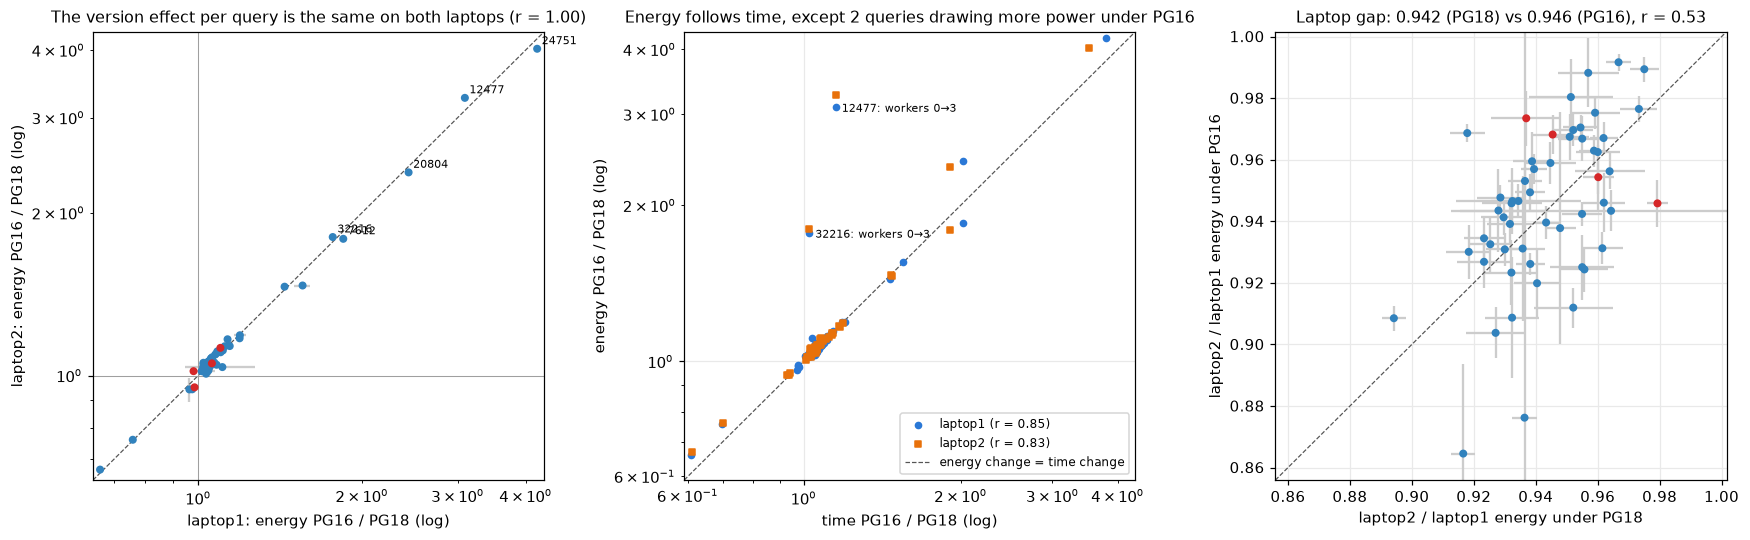

laptop1: energy PG16/PG18 median 1.056 (range 0.66–4.20), one pass 1.115; time median 1.051, one pass 1.051;  beyond noise: 6 lower, 45 higher of 54
laptop2: energy PG16/PG18 median 1.057 (range 0.67–4.02), one pass 1.112; time median 1.057, one pass 1.044;  beyond noise: 5 lower, 48 higher of 54
laptop2/laptop1 under PG18: energy median 0.942, one pass 0.948, lower beyond noise for 53/54; time median 1.001
laptop2/laptop1 under PG16: energy median 0.946, one pass 0.946, lower beyond noise for 53/54; time median 1.002


In [6]:
LV = [n for n in LAPTOPS if f"{n} PG18" in LBL and f"{n} PG16" in LBL]
VR = {n: ratio(f"{n} PG18", f"{n} PG16", "pkg") for n in LV}
VT = {n: ratio(f"{n} PG18", f"{n} PG16", "t") for n in LV}
GAP = {v: ratio(f"laptop1 PG{v}", f"laptop2 PG{v}", "pkg") for v in ["18", "16"]}
GAPT = {v: ratio(f"laptop1 PG{v}", f"laptop2 PG{v}", "t") for v in ["18", "16"]}
pcol = lambda idx: np.where(KIND[idx] == "probe", "#d62728", "#3182bd")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
ax = axes[0]
a, b = VR["laptop1"], VR["laptop2"]
r_ab = np.corrcoef(np.log(a["ratio"]), np.log(b["ratio"]))[0, 1]
ax.errorbar(a["ratio"], b["ratio"], xerr=[a["ratio"] - a["lo"], a["hi"] - a["ratio"]],
            yerr=[b["ratio"] - b["lo"], b["hi"] - b["ratio"]], fmt="none", ecolor="#ccc", zorder=2)
ax.scatter(a["ratio"], b["ratio"], s=18, c=pcol(a.index), zorder=3)
lim = [min(a["ratio"].min(), b["ratio"].min()) * 0.97, max(a["ratio"].max(), b["ratio"].max()) * 1.03]
ax.plot(lim, lim, color="#555", lw=0.8, ls="--"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.axhline(1, color="#999", lw=0.6); ax.axvline(1, color="#999", lw=0.6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("laptop1: energy PG16 / PG18 (log)"); ax.set_ylabel("laptop2: energy PG16 / PG18 (log)")
ax.set_title(f"The version effect per query is the same on both laptops (r = {r_ab:.2f})", fontsize=10.5)
for q in (np.log(a["ratio"]).abs() + np.log(b["ratio"]).abs()).nlargest(5).index:
    ax.annotate(q, (a.at[q, "ratio"], b.at[q, "ratio"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax = axes[1]
for n, mk in zip(LV, ["o", "s"]):
    r_et = np.corrcoef(np.log(VT[n]["ratio"]), np.log(VR[n]["ratio"]))[0, 1]
    ax.scatter(VT[n]["ratio"], VR[n]["ratio"], s=16, marker=mk, color=COL[f"{n} PG16"], label=f"{n} (r = {r_et:.2f})", zorder=3)
lim = [min(min(VT[n]["ratio"].min(), VR[n]["ratio"].min()) for n in LV) * 0.97,
       max(max(VT[n]["ratio"].max(), VR[n]["ratio"].max()) for n in LV) * 1.03]
ax.plot(lim, lim, color="#555", lw=0.8, ls="--", label="energy change = time change")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
OUTL = [q for q in VR[LV[0]].index if all(VR[n].at[q, "ratio"] / VT[n].at[q, "ratio"] > 1.3 for n in LV)]
for q in OUTL:
    w = (f": workers {S['laptop1 PG18'].at[q, 'workers']:g}→{S['laptop1 PG16'].at[q, 'workers']:g}"
         if q in S["laptop1 PG16"].index else "")
    ax.annotate(q + w, (VT[LV[0]].at[q, "ratio"], VR[LV[0]].at[q, "ratio"]), fontsize=7, xytext=(4, -3),
                textcoords="offset points")
ax.set_xlabel("time PG16 / PG18 (log)"); ax.set_ylabel("energy PG16 / PG18 (log)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Energy follows time" + (f", except {len(OUTL)} queries drawing more power under PG16" if OUTL else ""),
             fontsize=10.5)
ax = axes[2]
x, y = GAP["18"], GAP["16"]
r_g = np.corrcoef(x["ratio"], y["ratio"])[0, 1]
ax.errorbar(x["ratio"], y["ratio"], xerr=[x["ratio"] - x["lo"], x["hi"] - x["ratio"]],
            yerr=[y["ratio"] - y["lo"], y["hi"] - y["ratio"]], fmt="none", ecolor="#ccc", zorder=2)
ax.scatter(x["ratio"], y["ratio"], s=18, c=pcol(x.index), zorder=3)
lim = [min(x["ratio"].min(), y["ratio"].min()) * 0.99, max(x["ratio"].max(), y["ratio"].max()) * 1.01]
ax.plot(lim, lim, color="#555", lw=0.8, ls="--"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("laptop2 / laptop1 energy under PG18"); ax.set_ylabel("laptop2 / laptop1 energy under PG16")
ax.set_title(f"Laptop gap: {x['ratio'].median():.3f} (PG18) vs {y['ratio'].median():.3f} (PG16), r = {r_g:.2f}",
             fontsize=10.5)
fig.tight_layout(); savefig(fig, "version_laptops"); plt.show()

for n in LV:
    v, vt = VR[n], VT[n]
    print(f"{n}: energy PG16/PG18 median {v['ratio'].median():.3f} (range {v['ratio'].min():.2f}–{v['ratio'].max():.2f}), "
          f"one pass {set_ratio(f'{n} PG18', f'{n} PG16'):.3f}; time median {vt['ratio'].median():.3f}, "
          f"one pass {set_ratio(f'{n} PG18', f'{n} PG16', 't'):.3f};  beyond noise: {int((v['hi'] < 1).sum())} lower, "
          f"{int((v['lo'] > 1).sum())} higher of {len(v)}")
for v in ["18", "16"]:
    g, gt = GAP[v], GAPT[v]
    print(f"laptop2/laptop1 under PG{v}: energy median {g['ratio'].median():.3f}, one pass "
          f"{set_ratio(f'laptop1 PG{v}', f'laptop2 PG{v}'):.3f}, lower beyond noise for {int((g['hi'] < 1).sum())}/{len(g)}; "
          f"time median {gt['ratio'].median():.3f}")

**What changed in the plans.** The runner records PostgreSQL's own statistics for every measured copy
(`EXPLAIN ANALYZE`; SQLStorm queries only). A query whose plan nodes, parallel workers or temp-file writes differ
between the versions ran a different plan; buffer hits can differ with the same plan. The table lists the
queries with the largest version effect (mean over both laptops) and what differs.

In [7]:
STATS = ["workers", "nodes", "rows", "hit", "read", "temp"]
chg = {}
for q in VR[LV[0]].index:
    if q not in S["laptop1 PG16"].index:
        continue
    diffs = []
    for st in STATS:
        vals = {(n, v): S[f"{n} PG{v}"].at[q, st] for n in LV for v in ["18", "16"] if q in S[f"{n} PG{v}"].index}
        old, new = vals.get(("laptop1", "18")), vals.get(("laptop1", "16"))
        if old is not None and new is not None and old != new:
            diffs.append(f"{st} {old:g}→{new:g}")
    chg[q] = diffs
PLANCHG = pd.Series({q: any(d.split()[0] in ("workers", "nodes", "temp") for d in v) for q, v in chg.items()})
L = pd.DataFrame({"kind": KIND, **{f"E {n}": VR[n]["ratio"] for n in LV}, **{f"t {n}": VT[n]["ratio"] for n in LV}})
L["exec ms PG18→16 (laptop1)"] = [
    f"{S['laptop1 PG18'].at[q, 'exec_ms']:.0f}→{S['laptop1 PG16'].at[q, 'exec_ms']:.0f}" if q in S["laptop1 PG16"].index else "-"
    for q in L.index]
L["differs (laptop1, PG18→PG16)"] = [", ".join(chg.get(q, [])) or ("-" if q in chg else "(probe: no stats)") for q in L.index]
L["size"] = np.log(L[[f"E {n}" for n in LV]]).abs().mean(axis=1)
with pd.option_context("display.width", 260, "display.max_colwidth", 80):
    print(L.sort_values("size", ascending=False).drop(columns="size").head(14).round(3).to_string())
lr = np.log(L[[f"E {n}" for n in LV]]).abs().mean(axis=1)
print(f"\nSQLStorm queries with a different plan shape (nodes, workers or temp writes) between the versions: "
      f"{int(PLANCHG.sum())}/{len(PLANCHG)};  median |energy change|: plan changed "
      f"{100 * (np.exp(lr[PLANCHG[PLANCHG].index].median()) - 1):.1f}%, same plan "
      f"{100 * (np.exp(lr[PLANCHG[~PLANCHG].index].median()) - 1):.1f}%")

           kind  E laptop1  E laptop2  t laptop1  t laptop2 exec ms PG18→16 (laptop1)                              differs (laptop1, PG18→PG16)
q                                                                                                                                              
24751  sqlstorm      4.200      4.022      3.794      3.522                   257→980                              nodes 14→15, hit 77764→69138
12477  sqlstorm      3.092      3.263      1.152      1.152                 2277→2625                workers 0→3, nodes 19→20, hit 59406→235458
20804  sqlstorm      2.437      2.376      2.021      1.911                  724→1464                                           hit 94663→94975
7612   sqlstorm      1.848      1.790      2.019      1.911                  970→1962                                         hit 110198→110354
32216  sqlstorm      1.767      1.804      1.025      1.025                 3785→3877  workers 0→3, nodes 29→32, hit 121744→150541, temp

**Reading §3.**

* **PG16 is slower and costs more than PG18 on this set.** The median query takes about 5 % longer and uses
  about 5–6 % more package energy; one pass over the 54 queries costs about 11–12 % more energy for 5 % more time.
  Of 54 queries, 45–48 use more energy beyond noise under PG16 and only 5–6 use less.
* **It is the software, not the laptop.** The per-query version effect is the same on both laptops (r ≈ 1.00),
  from 0.66× to 4.2×.
* **Mostly through time; two queries through power.** For most queries the energy ratio equals the time ratio.
  The exceptions are 12477 and 32216: PG16 launches 3 parallel workers where PG18 runs them serially, which
  takes about the same time (1.0–1.15×) but 1.8–3.2× the energy. The largest time change is 24751 (PG16 about
  4× slower, a different plan).
* **A different plan explains part of it, not all.** 13 of 50 SQLStorm queries have a different plan shape
  (plan nodes, workers or temp writes) under PG16; their median change is about 14 %, against about 5–6 % for
  queries with the same plan shape. With the same plan, PG16 is still a few percent slower.
* **The laptop gap repeats under PG16.** laptop2 / laptop1 is 0.942 under PG18 and 0.946 under PG16 (median
  query), lower beyond noise for 53 of 54 queries in both sessions, 11 days apart. Per query the two gaps
  correlate only moderately (r ≈ 0.5): the gap is a near-constant offset, and its spread between queries
  (0.86–0.99) is not much larger than the noise.

## 4. Comparison across all machines

All PG16 runs at their normal clock: both laptops (2.5 GHz cap), the m510 nodes (2.6 GHz cap, turbo allowed)
and er063 (3.7 GHz cap). Absolute levels differ by an order of magnitude, so everything is relative to laptop1
(PG16). For a query, `energy ratio = time ratio × power ratio`: the first figure separates the two.

The 16 copies of a batch run one after another (the server's summed execution time equals the batch's wall time
on every machine), so the slope is the cost of one execution with the per-batch start-up removed. The 1-copy batch,
which includes that start-up once, is shown alongside.

In [8]:
XM = [l for l in ["laptop1 PG16", "laptop2 PG16"] if l in LBL] + [l for l in MAIN if R.at[l, "hw"] != "laptop" and "GHz" not in l]
REF = XM[0]
IDLE = {l: I[l]["idle_pkg_w"].median() for l in LBL}


def machine_row(l):
    re_, rt = ratio(REF, l, "pkg"), ratio(REF, l, "t")
    r1, rt1 = ratio(REF, l, "e1"), ratio(REF, l, "t1")
    pq = E[l].groupby("q")[["pkg", "total", "t", "t1"]].mean().loc[re_.index]
    info = NODE.get(R.at[l, "machine"]) or kv(read(R.at[l, "path"] / "summary.txt"))
    return {"hardware": R.at[l, "hardware"] + f" ({R.at[l, 'cpu']})", "CPUs": info.get("cpu_count", "?"),
            "clock cap": f"{R.at[l, 'clock_ghz']:.1f} GHz", "rounds": f"{rounds(l):.1f}", "queries": len(re_),
            "one pass: package (J)": pq["pkg"].sum(), "one pass: pkg + DRAM (J)": pq["total"].sum(),
            "one pass: time (s)": pq["t"].sum(), "power while running (W)": pq["pkg"].sum() / pq["t"].sum(),
            "idle package (W)": IDLE[l], "energy vs laptop1 (median query)": re_["ratio"].median(),
            "time vs laptop1 (median query)": rt["ratio"].median(),
            "1-copy energy vs laptop1": r1["ratio"].median(), "1-copy time vs laptop1": rt1["ratio"].median(),
            "1-copy time / slope time": (pq["t1"] / pq["t"]).median()}


MT = pd.DataFrame({l: machine_row(l) for l in XM + [l for l in LBL if "GHz" in l]})
with pd.option_context("display.width", 260, "display.max_colwidth", 40):
    print(MT.to_string(formatters=None, float_format=lambda v: f"{v:.3g}"))

                                                        laptop1 PG16                        laptop2 PG16                                  ms1126                                  ms0837                                  ms0834                                   er063                          ms1126 2.0 GHz
hardware                          Dell Latitude 7490 (Core i5-8350U)  Dell Latitude 7490 (Core i5-8350U)  HP m510 Server Cartridge (Xeon D-1548)  HP m510 Server Cartridge (Xeon D-1548)  HP m510 Server Cartridge (Xeon D-1548)  Dell PowerEdge C6620 (XEON GOLD 5512U)  HP m510 Server Cartridge (Xeon D-1548)
CPUs                                                               8                                   8                                      16                                      16                                      16                                      56                                      16
clock cap                                                    2.5 GHz                 

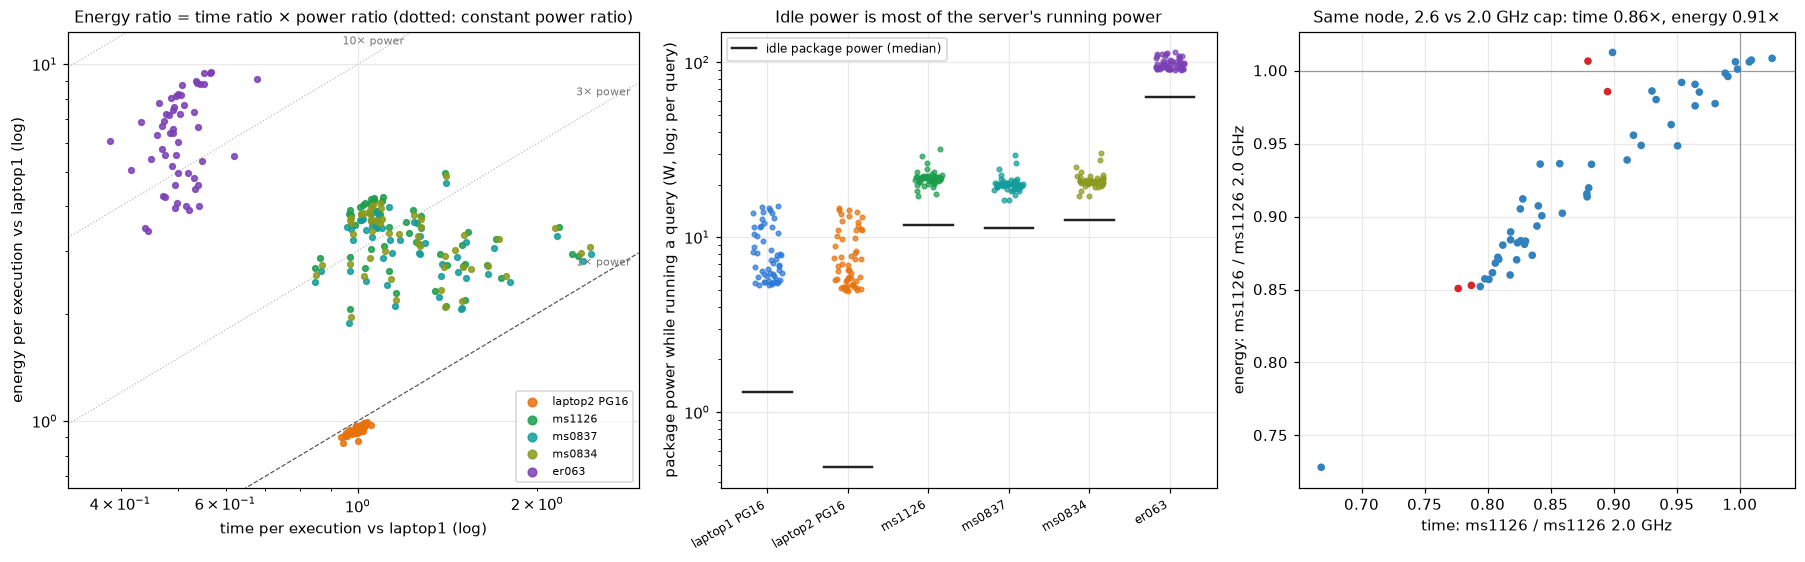

laptop2 PG16 vs laptop1 PG16: energy 0.95× (range 0.86–0.99), time 1.00× (0.94–1.05), power 0.9×; idle 0.5 W = 7% of its running power
ms1126   vs laptop1 PG16: energy 3.50× (range 2.06–4.94), time 1.11× (0.85–2.34), power 3.0×; idle 11.7 W = 53% of its running power
ms0837   vs laptop1 PG16: energy 3.21× (range 1.89–4.65), time 1.12× (0.85–2.47), power 2.7×; idle 11.3 W = 55% of its running power
ms0834   vs laptop1 PG16: energy 3.34× (range 1.95–4.86), time 1.10× (0.85–2.46), power 2.9×; idle 12.5 W = 58% of its running power
er063    vs laptop1 PG16: energy 6.41× (range 3.42–9.49), time 0.50× (0.38–0.68), power 13.3×; idle 63.2 W = 65% of its running power
clock ms1126 vs ms1126 2.0 GHz: energy 0.916 one pass, time 0.862; 16-copy clock 1836 → 2308 MHz


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2), gridspec_kw={"width_ratios": [1.15, 1, 1]})
ax = axes[0]
for l in XM[1:]:
    re_, rt = ratio(REF, l, "pkg"), ratio(REF, l, "t")
    ax.scatter(rt["ratio"], re_["ratio"], s=14, color=COL[l], label=f"{l}", zorder=3, alpha=0.85)
xs = pd.concat([ratio(REF, l, "t")["ratio"] for l in XM[1:]])
ys = pd.concat([ratio(REF, l, "pkg")["ratio"] for l in XM[1:]])
x0, x1, y0, y1 = xs.min() * 0.85, xs.max() * 1.2, ys.min() * 0.75, ys.max() * 1.3
for k in [1, 3, 10, 30]:
    ax.plot([x0, x1], [k * x0, k * x1], color="#555" if k == 1 else "#bbb", lw=0.8, ls="--" if k == 1 else ":", zorder=1)
    xe = min(x1, y1 / k)                                     # where the line leaves the plot
    if xe > x0 * 1.3:
        ax.text(xe / 1.03, k * xe / 1.03, f"{k}× power", fontsize=7, color="#777", ha="right", va="top")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
ax.set_xlabel("time per execution vs laptop1 (log)"); ax.set_ylabel("energy per execution vs laptop1 (log)")
ax.legend(fontsize=7.5, loc="lower right", markerscale=1.5)
ax.set_title("Energy ratio = time ratio × power ratio (dotted: constant power ratio)", fontsize=10.5)
ax = axes[1]
for j, l in enumerate(XM):
    p = (E[l].groupby("q")["pkg"].mean() / E[l].groupby("q")["t"].mean())
    ax.scatter(j + np.random.default_rng(j).uniform(-0.18, 0.18, len(p)), p, s=9, color=COL[l], alpha=0.7, zorder=3)
    ax.plot([j - 0.3, j + 0.3], [IDLE[l]] * 2, color="#222", lw=1.6, zorder=4)
ax.plot([], [], color="#222", lw=1.6, label="idle package power (median)")
ax.set_xticks(range(len(XM))); ax.set_xticklabels(XM, rotation=30, ha="right", fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("package power while running a query (W, log; per query)"); ax.legend(fontsize=8)
ax.set_title("Idle power is most of the server's running power", fontsize=10.5)
ax = axes[2]
CLK = [l for l in LBL if "GHz" in l]
if CLK:
    base = CLK[0]; fast = base.split()[0]
    re_, rt = ratio(base, fast, "pkg"), ratio(base, fast, "t")
    ax.scatter(rt["ratio"], re_["ratio"], s=16, c=pcol(re_.index), zorder=3)
    ax.axhline(1, color="#999", lw=0.8); ax.axvline(1, color="#999", lw=0.8)
    ax.set_xlabel(f"time: {fast} / {base}"); ax.set_ylabel(f"energy: {fast} / {base}")
    ax.set_title(f"Same node, 2.6 vs 2.0 GHz cap: time {rt['ratio'].median():.2f}×, energy {re_['ratio'].median():.2f}×",
                 fontsize=10.5)
fig.tight_layout(); savefig(fig, "machines_energy_time_power"); plt.show()

for l in XM[1:]:
    re_, rt = ratio(REF, l, "pkg"), ratio(REF, l, "t")
    pr = re_["ratio"] / rt["ratio"]
    print(f"{l:8s} vs {REF}: energy {re_['ratio'].median():.2f}× (range {re_['ratio'].min():.2f}–{re_['ratio'].max():.2f}), "
          f"time {rt['ratio'].median():.2f}× ({rt['ratio'].min():.2f}–{rt['ratio'].max():.2f}), power {pr.median():.1f}×; "
          f"idle {IDLE[l]:.1f} W = {IDLE[l] / (MT.at['power while running (W)', l]):.0%} of its running power")
if CLK:
    print(f"clock {fast} vs {base}: energy {set_ratio(base, fast):.3f} one pass, time {set_ratio(base, fast, 't'):.3f}; "
          f"16-copy clock {E[base]['mhz16'].median():.0f} → {E[fast]['mhz16'].median():.0f} MHz")

**Probes and the 1-copy batch.** The four synthetic probes isolate one kind of work each (CPU arithmetic, hash
join — memory latency, sequential scan — memory bandwidth, sort). Left: their energy and time relative to laptop1,
next to the median SQLStorm query. Right: whether the machine ranking depends on measuring with 16 copies (slope)
or one copy at a time.

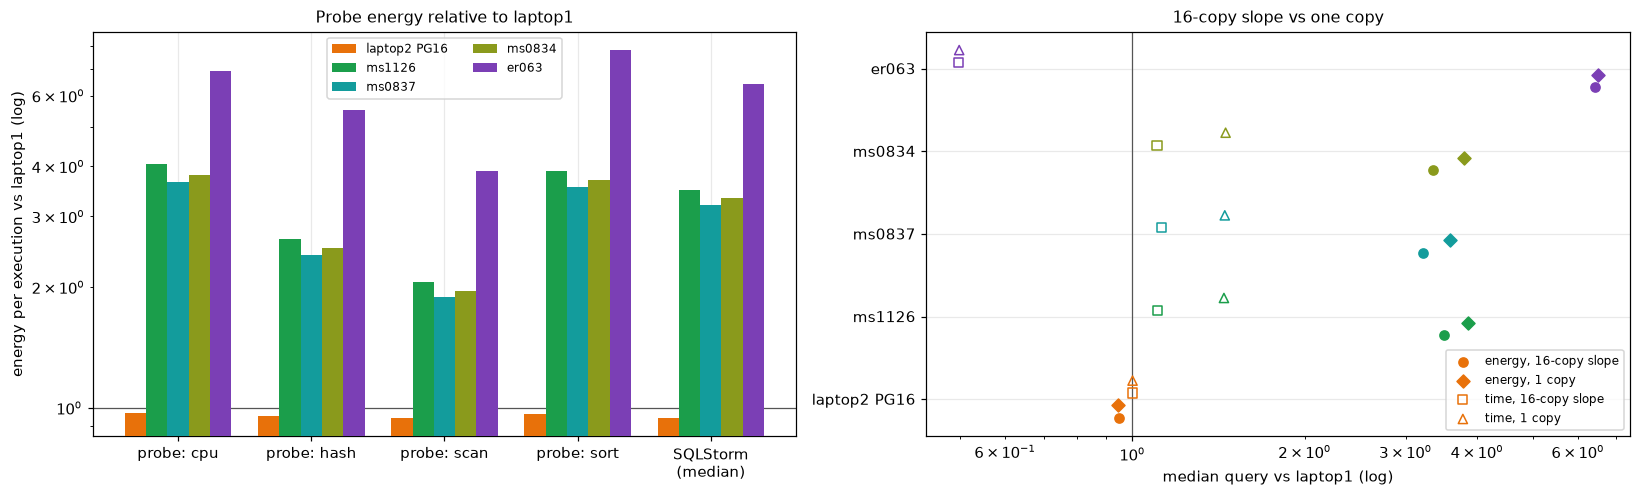

                laptop2 PG16  ms1126  ms0837  ms0834  er063
probe_cpu pkg           0.97    4.05    3.66    3.81   6.90
probe_cpu t             1.05    1.05    1.05    1.05   0.43
probe_hash pkg          0.95    2.63    2.40    2.50   5.52
probe_hash t            1.00    1.13    1.12    1.14   0.62
probe_scan pkg          0.95    2.06    1.89    1.95   3.90
probe_scan t            0.97    0.97    0.97    0.97   0.52
probe_sort pkg          0.97    3.90    3.56    3.71   7.80
probe_sort t            1.03    0.97    0.97    0.97   0.46


In [10]:
PRB = sorted(KIND.index[KIND == "probe"])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
ax = axes[0]
w = 0.8 / (len(XM) - 1)
for j, l in enumerate(XM[1:]):
    re_ = ratio(REF, l, "pkg")
    vals = [re_.at[p, "ratio"] for p in PRB] + [re_.loc[KIND[re_.index] == "sqlstorm", "ratio"].median()]
    ax.bar(np.arange(len(vals)) + (j - (len(XM) - 2) / 2) * w, vals, w, color=COL[l], label=l, zorder=3)
ax.axhline(1, color="#555", lw=0.8)
ax.set_xticks(range(len(PRB) + 1)); ax.set_xticklabels([p.replace("probe_", "probe: ") for p in PRB] + ["SQLStorm\n(median)"])
ax.set_yscale("log"); ax.set_ylabel("energy per execution vs laptop1 (log)"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Probe energy relative to laptop1", fontsize=10.5)
ax = axes[1]
for j, l in enumerate(XM[1:]):
    for k, (col, mk, lb) in enumerate([("pkg", "o", "energy, 16-copy slope"), ("e1", "D", "energy, 1 copy"),
                                       ("t", "s", "time, 16-copy slope"), ("t1", "^", "time, 1 copy")]):
        ax.scatter(ratio(REF, l, col)["ratio"].median(), j + (k - 1.5) * 0.15, marker=mk, s=36,
                   color=COL[l] if k < 2 else "none", edgecolor=COL[l], zorder=3, label=lb if j == 0 else None)
ax.axvline(1, color="#555", lw=0.8)
ax.set_yticks(range(len(XM) - 1)); ax.set_yticklabels(XM[1:])
ax.set_xscale("log"); ax.set_xlabel("median query vs laptop1 (log)")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("16-copy slope vs one copy", fontsize=10.5)
fig.tight_layout(); savefig(fig, "machines_probes_onecopy"); plt.show()
PT = pd.DataFrame({l: {f"{p} {c}": ratio(REF, l, c).at[p, "ratio"] for p in PRB for c in ["pkg", "t"]} for l in XM[1:]})
print(PT.round(2).to_string())

**Reading §4.**

* **The m510 runs the set at about laptop speed, for 3.2–3.5× the energy.** The median query takes about 1.1×
  laptop1's time; the power while running is about 3× higher. er063 is about 2× faster than a laptop but draws
  about 13× the power, so it uses about 6.4× the energy per query.
* **Idle power is most of a server's running power.** Measured before each entry, idle package power is 53–58 %
  of the m510's power while running a query and about 65 % of er063's, against 7–17 % on the laptops. Most of what
  the slope charges to a query on a server is the cost of keeping the machine on for that time. This also makes
  energy on a server follow time more closely (§7); §5 separates the two parts.
* **A higher clock saved energy on the m510.** On the same node (ms1126), the 2.6 GHz cap ran the set 14 % faster
  than the 2.0 GHz cap and used about 8 % *less* energy. Finishing sooner pays less of the large idle power.
  Per query, the energy saving tracks the time saving; queries the clock does not speed up save nothing.
* **The ratio depends on the kind of work.** Relative to laptop1, the scan probe costs about 2× on the m510 and
  3.9× on er063. The CPU and sort probes cost about 4× on the m510 and 7–8× on er063. Memory-bandwidth work is
  relatively cheapest on the servers.
* **The slope vs one copy does not change the picture.** The machines rank the same way with both. The m510 is
  1.45× slower than a laptop for one copy but only 1.1× slower in the slope: the 1-copy batch carries the per-batch
  start-up (client, connection) once, and that fixed cost is relatively larger on the m510. The slope, from 16
  back-to-back copies, leaves it out. The 1-copy ratio is about 0.4 higher for the m510 and about equal for er063.

## 5. Idle draw per machine, and the cost over idle

Before every entry the runner measures 5 s of the machine sitting idle (PostgreSQL running, nothing executing):
the **idle draw**. Below, first that draw per machine — package, DRAM, psys where available — and how steady it
is over a 3–4 h run.

The slope energy of a query includes that draw for as long as the query runs. Taking it out leaves the **cost
over idle**, the energy the query adds on top of keeping the machine on:

`over idle = slope energy − idle power × slope time`, per entry, with the idle power measured just before that
entry (package and DRAM each against their own idle; psys against idle psys).

The full slope is what a query costs on a machine that would otherwise be idle-but-on; the cost over idle is what
it costs on a machine that is on anyway. Both are shown.

                                              hardware package (W) DRAM (W) pkg + DRAM (W) psys (W) cores (W) pkg+DRAM spread (IQR, %) first → last round (%) busy power while running (W) idle / running
laptop1 PG18        Dell Latitude 7490 (Core i5-8350U)        1.36    0.583           1.94      NaN      0.17                     2.33                 -0.487                         8.16          0.238
laptop2 PG18        Dell Latitude 7490 (Core i5-8350U)       0.473    0.256           0.73      NaN    0.0845                     5.89                   1.04                         7.41         0.0985
laptop1 PG16        Dell Latitude 7490 (Core i5-8350U)        1.31    0.578           1.88      NaN      0.11                     1.96                 -0.556                         8.62          0.219
laptop2 PG16        Dell Latitude 7490 (Core i5-8350U)       0.483    0.256          0.739      NaN     0.084                      6.5                   1.72                         7.89      

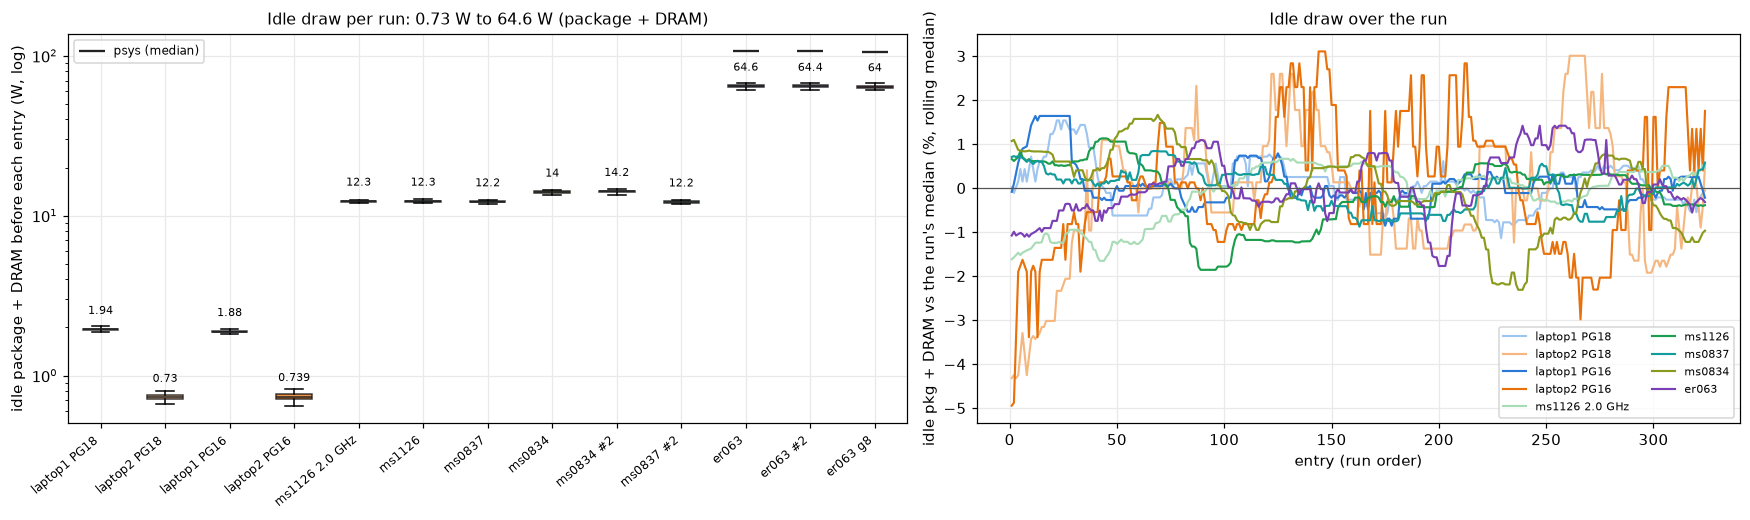

In [11]:
IDL = {}
for l in LBL:
    i = I[l]
    pd_ = i["idle_pkg_w"] + i["idle_dram_w"]
    first, last = pd_.iloc[:54].median(), pd_.iloc[-54:].median()
    IDL[l] = {"hardware": f"{R.at[l, 'hardware']} ({R.at[l, 'cpu']})",
              "package (W)": i["idle_pkg_w"].median(), "DRAM (W)": i["idle_dram_w"].median(),
              "pkg + DRAM (W)": pd_.median(),
              "psys (W)": i["idle_psys_w"].median() if "idle_psys_w" in i else np.nan,
              "cores (W)": i["idle_core_w"].median() if R.at[l, "hw"] == "laptop" else np.nan,
              "pkg+DRAM spread (IQR, %)": 100 * (pd_.quantile(0.75) - pd_.quantile(0.25)) / pd_.median(),
              "first → last round (%)": 100 * (last / first - 1),
              "busy power while running (W)": (E[l]["total"].sum() / E[l]["t"].sum())}
IDT = pd.DataFrame(IDL).T
IDT["idle / running"] = IDT["pkg + DRAM (W)"] / IDT["busy power while running (W)"]
with pd.option_context("display.width", 250, "display.max_colwidth", 42):
    print(IDT.to_string(float_format=lambda v: f"{v:.3g}"))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
for j, l in enumerate(LBL):
    i = I[l]
    pd_ = i["idle_pkg_w"] + i["idle_dram_w"]
    ax.boxplot([pd_], positions=[j], widths=0.55, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=COL[l], alpha=0.75), medianprops=dict(color="#222"))
    if "idle_psys_w" in i:
        ax.scatter([j], [i["idle_psys_w"].median()], marker="_", s=300, color="#222", zorder=4,
                   label="psys (median)" if j == LBL.index(next(x for x in LBL if "idle_psys_w" in I[x])) else None)
    ax.text(j, pd_.median() * 1.25, f"{pd_.median():.3g}", ha="center", fontsize=7)
ax.set_xticks(range(len(LBL))); ax.set_xticklabels(LBL, rotation=40, ha="right", fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("idle package + DRAM before each entry (W, log)")
ax.legend(fontsize=8, loc="upper left")
ax.set_title(f"Idle draw per run: {IDT['pkg + DRAM (W)'].min():.2g} W to {IDT['pkg + DRAM (W)'].max():.3g} W "
             f"(package + DRAM)", fontsize=10.5)
ax = axes[1]
for l in MAIN:
    i = I[l]
    pd_ = (i["idle_pkg_w"] + i["idle_dram_w"])
    rel = 100 * (pd_ / pd_.median() - 1)
    ax.plot(i["entry"], rel.rolling(27, center=True, min_periods=10).median(), color=COL[l], lw=1.4, label=l)
ax.axhline(0, color="#555", lw=0.8)
ax.set_xlabel("entry (run order)"); ax.set_ylabel("idle pkg + DRAM vs the run's median (%, rolling median)")
ax.legend(fontsize=7.5, ncol=2)
ax.set_title("Idle draw over the run", fontsize=10.5)
fig.tight_layout(); savefig(fig, "idle_draw"); plt.show()

                one pass pkg+DRAM (J)  idle part (J)  over idle (J)  over-idle share  power over idle while running (W)  queries with over idle ≤ 0  vs laptop1: full (median query)  vs laptop1: over idle (median query)
laptop1 PG18                      649            155            494            0.762                               6.21                           0                            0.949                                 0.942
laptop2 PG18                      592             59            533              0.9                               6.67                           0                            0.852                                  1.02
laptop1 PG16                      720            158            562            0.781                               6.73                           0                              NaN                                   NaN
laptop2 PG16                      658           61.5            596            0.906                               7.15     

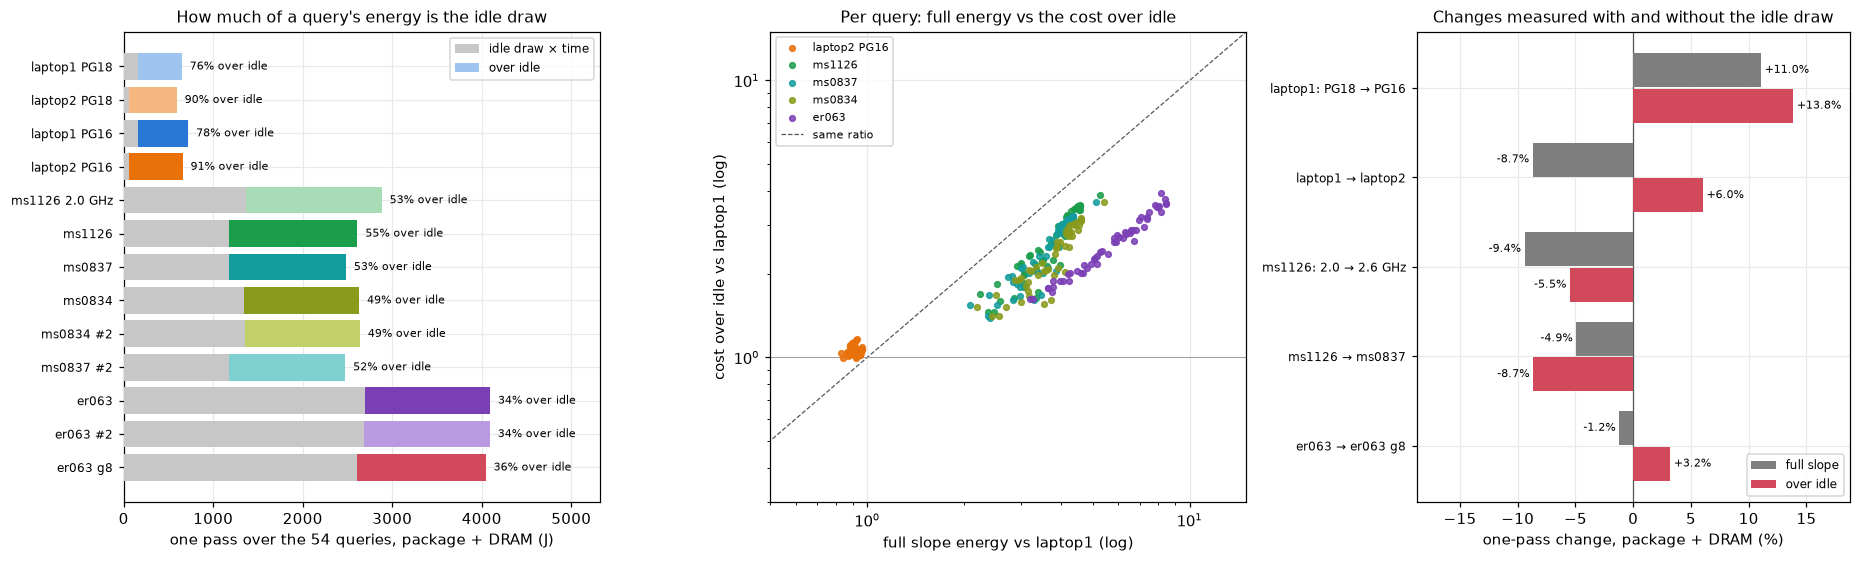

laptop1: PG18 → PG16     full  +11.0%   over idle  +13.8%   time   +5.1%
laptop1 → laptop2        full   -8.7%   over idle   +6.0%   time   -0.3%
ms1126: 2.0 → 2.6 GHz    full   -9.4%   over idle   -5.5%   time  -13.8%
ms1126 → ms0837          full   -4.9%   over idle   -8.7%   time   +0.3%
er063 → er063 g8         full   -1.2%   over idle   +3.2%   time   -3.1%


In [12]:
for l in LBL:
    e = E[l]
    e["pkg_oi"] = e["pkg"] - e["idle_pkg_w"] * e["t"]
    e["dram_oi"] = e["dram"] - e["idle_dram_w"] * e["t"]
    e["total_oi"] = e["pkg_oi"] + e["dram_oi"]
    if "psys" in e and "idle_psys_w" in e:
        e["psys_oi"] = e["psys"] - e["idle_psys_w"] * e["t"]

OI = {}
for l in LBL:
    pq = E[l].groupby("q")[["total", "total_oi", "pkg", "pkg_oi", "t"]].mean()
    tot, oi = pq["total"].sum(), pq["total_oi"].sum()
    OI[l] = {"one pass pkg+DRAM (J)": tot, "idle part (J)": tot - oi, "over idle (J)": oi, "over-idle share": oi / tot,
             "power over idle while running (W)": oi / pq["t"].sum(),
             "queries with over idle ≤ 0": int((pq["total_oi"] <= 0).sum())}
    if l != REF:
        OI[l]["vs laptop1: full (median query)"] = ratio(REF, l, "total")["ratio"].median()
        OI[l]["vs laptop1: over idle (median query)"] = ratio(REF, l, "total_oi")["ratio"].median()
OIT = pd.DataFrame(OI).T
with pd.option_context("display.width", 250):
    print(OIT.to_string(float_format=lambda v: f"{v:.3g}"))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
ax = axes[0]
y = np.arange(len(LBL))[::-1]
ip, op = OIT["idle part (J)"].astype(float), OIT["over idle (J)"].astype(float)
ax.barh(y, ip, color="#c7c7c7", label="idle draw × time", zorder=3)
ax.barh(y, op, left=ip, color=[COL[l] for l in LBL], label="over idle", zorder=3)
for yy, l in zip(y, LBL):
    ax.text(ip[l] + op[l], yy, f"  {100 * OIT.at[l, 'over-idle share']:.0f}% over idle", va="center", fontsize=7.5)
ax.set_yticks(y); ax.set_yticklabels(LBL, fontsize=8)
ax.set_xlabel("one pass over the 54 queries, package + DRAM (J)")
ax.set_xlim(0, (ip + op).max() * 1.3); ax.legend(fontsize=8, loc="upper right")
ax.set_title("How much of a query's energy is the idle draw", fontsize=10.5)
ax = axes[1]
XO = [l for l in XM if l != REF]
for l in XO:
    a, b = ratio(REF, l, "total"), ratio(REF, l, "total_oi")
    ok = b["ratio"] > 0
    ax.scatter(a["ratio"][ok], b["ratio"][ok], s=14, color=COL[l], label=l, zorder=3, alpha=0.85)
lim = [0.3, 40]
ax.plot(lim, lim, color="#555", lw=0.8, ls="--", label="same ratio")
ax.axhline(1, color="#999", lw=0.6)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.5, 15); ax.set_ylim(0.3, 15)
ax.set_xlabel("full slope energy vs laptop1 (log)"); ax.set_ylabel("cost over idle vs laptop1 (log)")
ax.legend(fontsize=7.5, loc="upper left")
ax.set_title("Per query: full energy vs the cost over idle", fontsize=10.5)
ax = axes[2]
PAIRS = [(a, b, lb) for a, b, lb in [
    ("laptop1 PG18", "laptop1 PG16", "laptop1: PG18 → PG16"), ("laptop1 PG16", "laptop2 PG16", "laptop1 → laptop2"),
    ("ms1126 2.0 GHz", "ms1126", "ms1126: 2.0 → 2.6 GHz"), ("ms1126", "ms0837", "ms1126 → ms0837"),
    ("er063", "er063 g8", "er063 → er063 g8")] if a in LBL and b in LBL]
yy = np.arange(len(PAIRS))[::-1]
for k, (col, lb, c) in enumerate([("total", "full slope", "#7f7f7f"), ("total_oi", "over idle", "#d1495b")]):
    v = [100 * (set_ratio(a, b, col) - 1) for a, b, _ in PAIRS]
    ax.barh(yy + (0.2 if k == 0 else -0.2), v, 0.38, color=c, label=lb, zorder=3)
    for yv, vv in zip(yy + (0.2 if k == 0 else -0.2), v):
        ax.text(vv, yv, f" {vv:+.1f}% " if vv >= 0 else f" {vv:+.1f}% ", va="center",
                ha="left" if vv >= 0 else "right", fontsize=7)
ax.axvline(0, color="#555", lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels([lb for _, _, lb in PAIRS], fontsize=8)
ax.set_xlabel("one-pass change, package + DRAM (%)"); ax.legend(fontsize=8, loc="lower right")
xm = max(abs(ax.get_xlim()[0]), abs(ax.get_xlim()[1])) * 1.25
ax.set_xlim(-xm, xm)
ax.set_title("Changes measured with and without the idle draw", fontsize=10.5)
fig.tight_layout(); savefig(fig, "cost_over_idle"); plt.show()
for a, b, lb in PAIRS:
    print(f"{lb:24s} full {100 * (set_ratio(a, b, 'total') - 1):+6.1f}%   over idle {100 * (set_ratio(a, b, 'total_oi') - 1):+6.1f}%   "
          f"time {100 * (set_ratio(a, b, 't') - 1):+6.1f}%")

**Does taking out the idle draw change which queries count as expensive?** τ between machines for the full slope
and for the cost over idle, and rank-order bars of the cost over idle on the two server types, ordered by
laptop1's cost over idle (compare with the full-energy bars in §7).

                              τ full  τ over idle
pair                                             
laptop1 PG16 vs laptop2 PG16   0.986        0.982
laptop1 PG16 vs ms1126         0.888        0.866
laptop1 PG16 vs ms0837         0.891        0.867
laptop1 PG16 vs ms0834         0.890        0.876
laptop1 PG16 vs er063          0.873        0.883
laptop2 PG16 vs ms1126         0.885        0.878
laptop2 PG16 vs ms0837         0.888        0.880
laptop2 PG16 vs ms0834         0.887        0.885
laptop2 PG16 vs er063          0.867        0.895
ms1126 vs ms0837               0.994        0.987
ms1126 vs ms0834               0.990        0.982
ms1126 vs er063                0.926        0.936
ms0837 vs ms0834               0.996        0.992
ms0837 vs er063                0.920        0.934
ms0834 vs er063                0.919        0.932

within each machine, τ between full and over-idle order: laptop1 PG16 0.97, laptop2 PG16 0.99, ms1126 0.98, ms0837 0.98, ms0834 0.98, er063 0.95


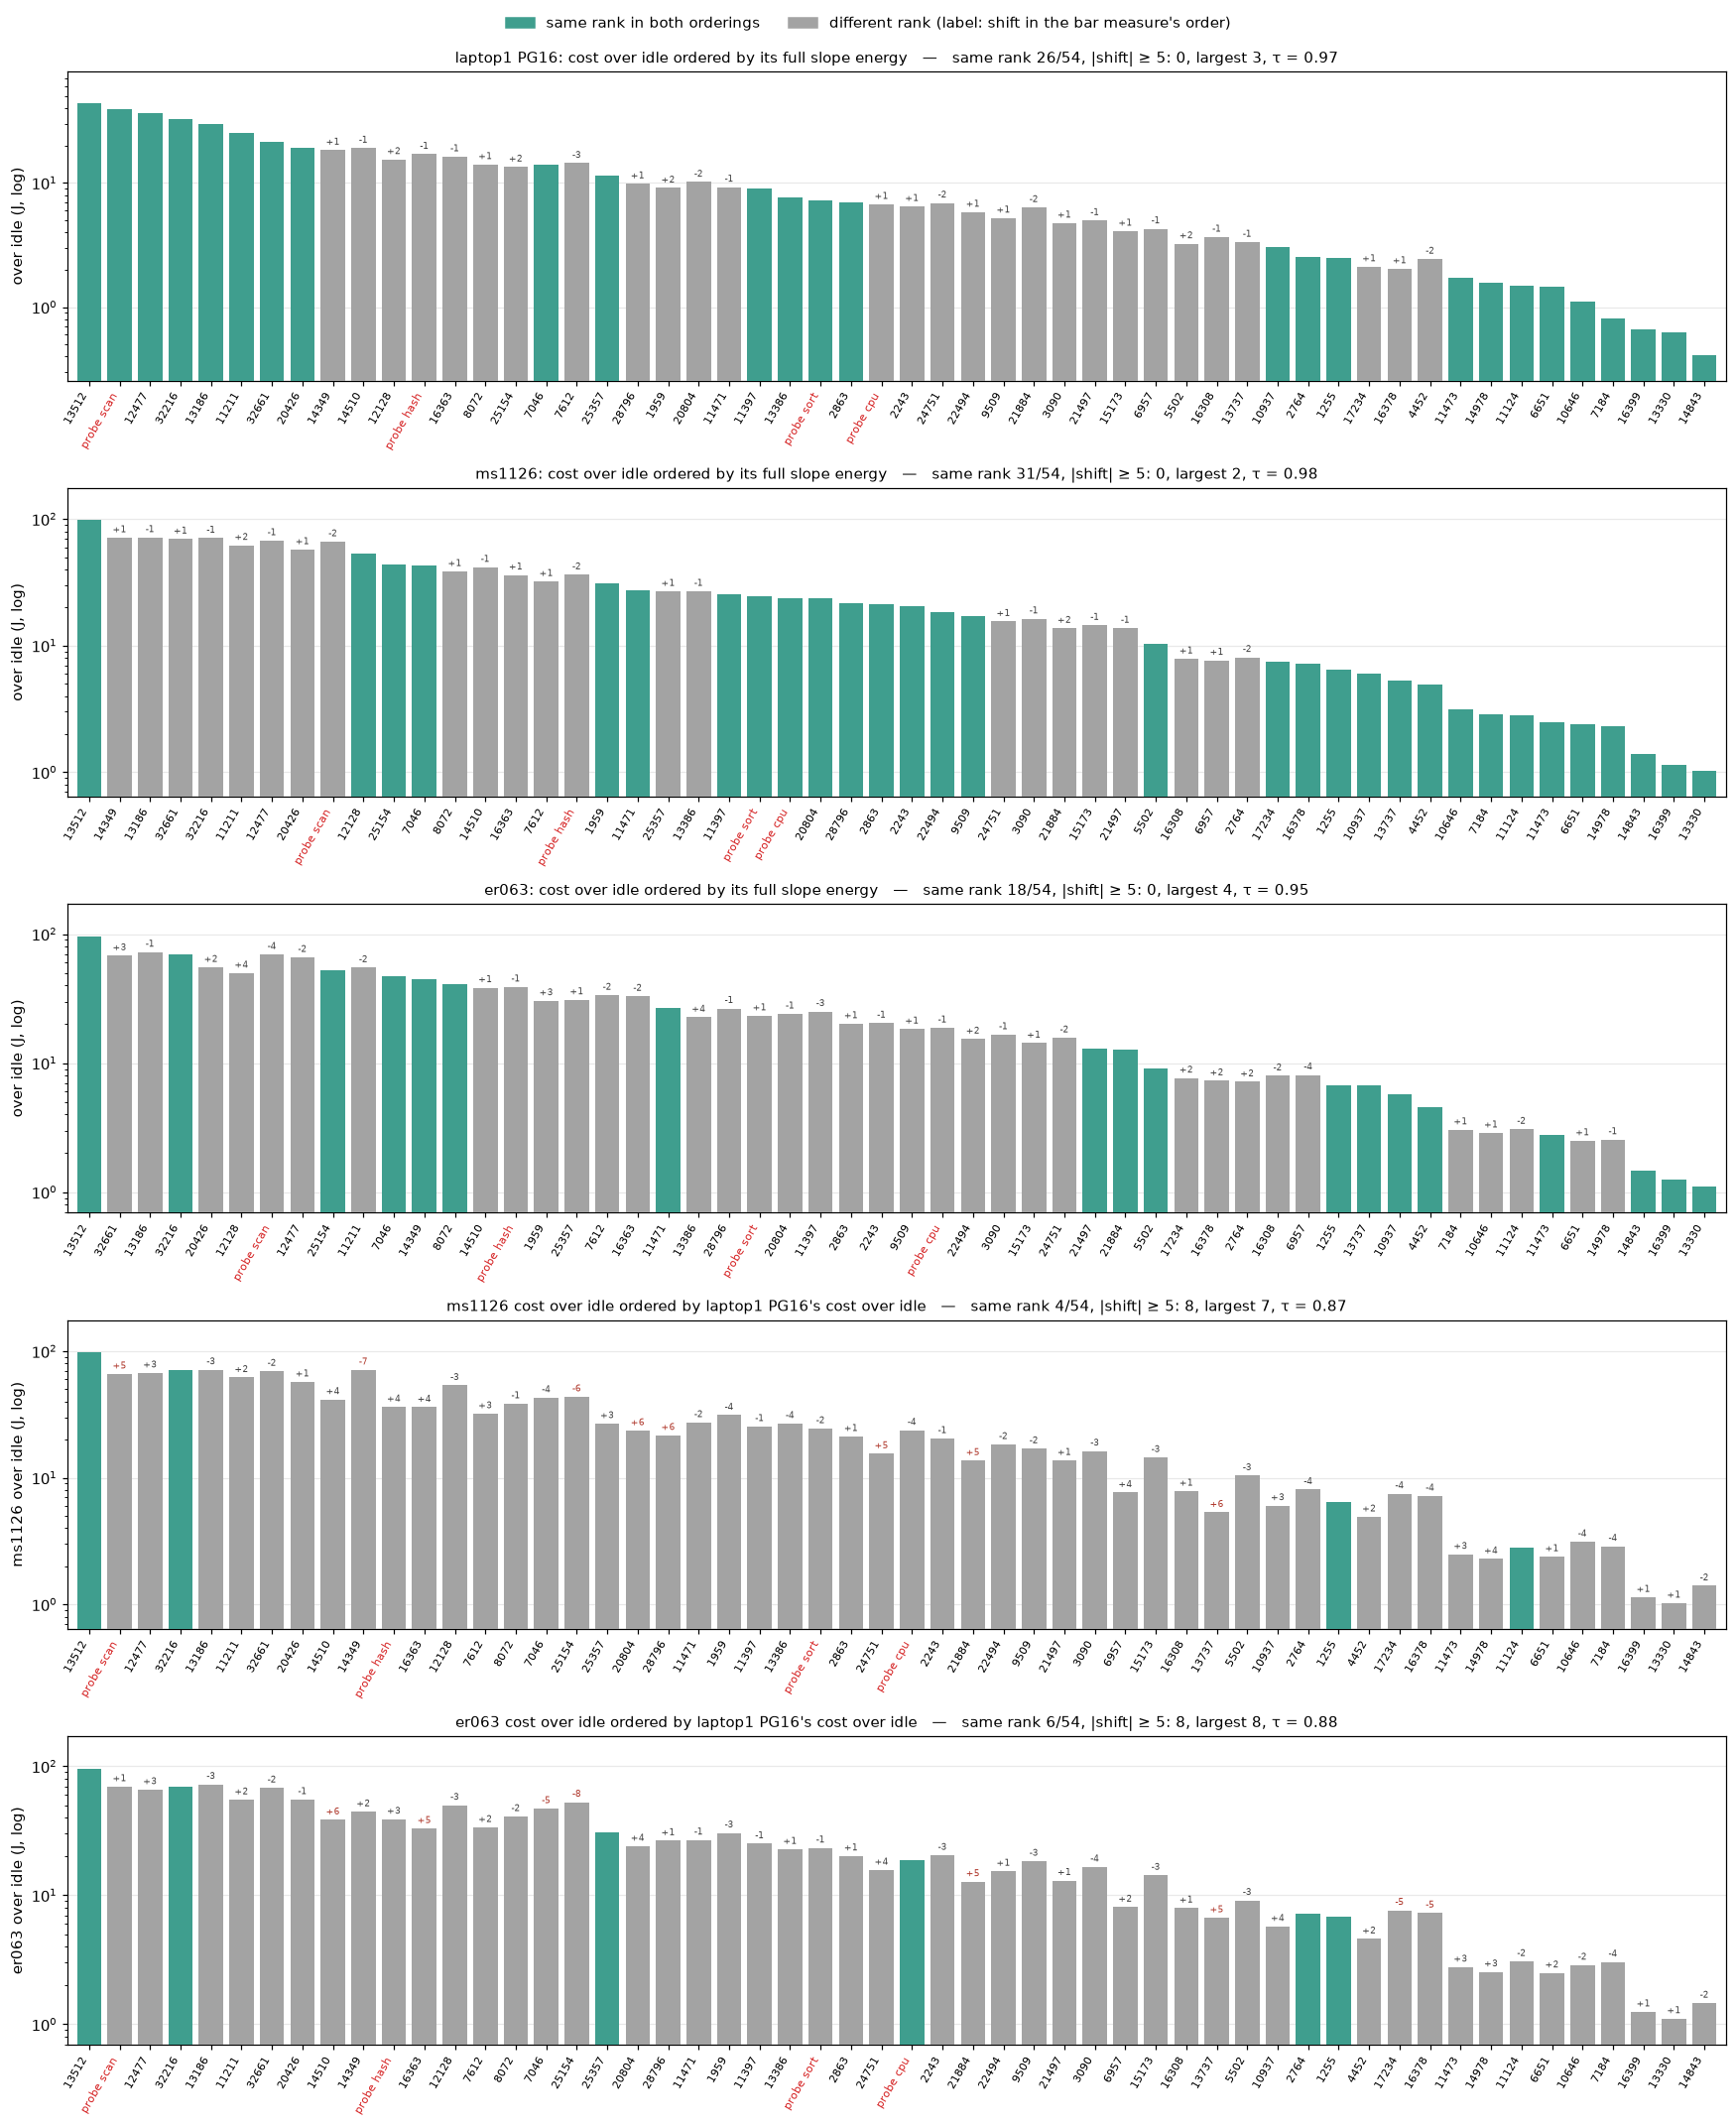

In [13]:
OIM = {l: E[l].groupby("q")["total_oi"].mean() for l in XM}
FUM = {l: E[l].groupby("q")["total"].mean() for l in XM}
rows = []
for i_, a in enumerate(XM):
    for b in XM[i_ + 1:]:
        q_ = OIM[a].index.intersection(OIM[b].index)
        rows.append({"pair": f"{a} vs {b}", "τ full": kendall(FUM[a][q_], FUM[b][q_]), "τ over idle": kendall(OIM[a][q_], OIM[b][q_])})
TOI = pd.DataFrame(rows).set_index("pair")
print(TOI.round(3).to_string())
print(f"\nwithin each machine, τ between full and over-idle order: " + ", ".join(
    f"{l} {kendall(FUM[l], OIM[l]):.2f}" for l in XM))
pos = lambda s: s.clip(lower=s[s > 0].min() / 2)                 # log bars: a (rare) non-positive value sits at the floor
SRV = [x for x in XM if R.at[x, "hw"] == "m510"][:1] + [x for x in XM if R.at[x, "hw"] == "c6620"][:1]
RBI = [(FUM[l], pos(OIM[l]), f"{l}: cost over idle ordered by its full slope energy", "over idle (J, log)")
       for l in [REF] + SRV]
RBI += [(OIM[REF], pos(OIM[l]), f"{l} cost over idle ordered by {REF}'s cost over idle", f"{l} over idle (J, log)")
        for l in SRV]
rank_figure(RBI, "rank_bars_over_idle")

**Reading §5.**

* **Idle draw spans two orders of magnitude.** Package + DRAM at idle is 0.7 W on laptop2, 1.9 W on laptop1,
  12–14 W on an m510 node and 64 W on er063 (psys 106 W). It is steady: the spread within a run is 1–7 %, and
  first vs last round differ by under 2 % (laptop2 starts up to 5 % low in its first ~20 entries). Repeat
  sessions reproduce it to within 1 %. Among the m510 nodes the idle draw differs by up to 16 % (12.2 vs 14.2 W),
  mostly from ms0834's higher DRAM idle.
* **On the servers, most of a query's energy is the idle draw.** Over one pass, the idle draw × time is 9–24 % of
  the laptops' energy, about half on the m510 (45–51 %) and two thirds on er063 (64–66 %).
* **Over idle, the servers are much closer to the laptops.**
  * In full energy the median query costs 3.7–3.9× laptop1 on the m510 and 5.9× on er063.
  * Over idle it costs 2.4–2.7× on both. er063's large disadvantage is mostly its idle draw.
  * Running a query adds about 14 W over idle on an m510 and about 34 W on er063, against 6–7 W on a laptop.
* **Some conclusions flip once the idle draw is taken out** (right panel):
  * **laptop1 vs laptop2:** laptop2's 9 % lower energy is entirely idle draw (0.7 vs 1.9 W). Over idle,
    laptop2 uses 6 % *more*. The gap measured in `compare_laptops.ipynb` is a difference in what the machine burns
    while doing nothing.
  * **More parallel workers on er063 (`g8`):** −1.2 % in full energy but +3.2 % over idle. The saving comes from
    paying the 64 W idle draw for a shorter time; the queries themselves draw more.
  * **The 2.6 GHz clock on ms1126:** it saves energy both ways (−9.4 % full, −5.5 % over idle), so finishing sooner
    is not its only gain.
  * **PG18 → PG16 on laptop1:** +11 % full, +14 % over idle. The extra cost is real work, not idle time.
  * **ms1126 → ms0837:** the node difference grows over idle (−4.9 % → −8.7 %), so it is not an idle-draw
    difference either.
* **The query ranking hardly depends on it.** Within a machine, the order by full energy and by cost over idle
  agree at τ 0.95–0.99. Between machines τ changes by at most ±0.03: slightly lower between a laptop and an m510,
  slightly higher between er063 and the rest.

## 6. Consistency across the CloudLab m510 nodes

Three m510 nodes with identical hardware and the same 2.6 GHz turbo setup: ms1126 (13 Oct) and ms0837 / ms0834
(15 Oct, running at the same time in one experiment). Per query, each node's mean is compared with ms1126. A
node's difference splits into a **node offset** (the median ratio over all queries — the node is simply more or
less efficient) and a **query-specific** part (the spread of the ratios around that offset beyond what the
repeat noise explains). Laptop1 vs laptop2 (PG16) is the same calculation on a pair of identical laptops.

ms0837 and ms0834 each ran the set a second time (`#2`, a later session with the same settings), and so did
er063. Comparing a node with its own second session shows whether a node's offset is a stable property of the
node or changes from session to session.

In [14]:
NODES = [l for l in MAIN if R.at[l, "hw"] == "m510" and "GHz" not in l]
REPEATS = [(l.split(" #")[0], l) for l in LBL if R.at[l, "role"] == "repeat" and l.split(" #")[0] in LBL]
NREF = NODES[0]


def components(a, b, col):
    """b vs a: node offset (median ratio), query-specific spread beyond noise (SD of log ratio), repeat CVs."""
    x = ratio(a, b, col)
    lr = np.log(x["ratio"])
    se = (np.log(x["hi"]) - np.log(x["lo"])) / (2 * 1.96)
    spread = np.sqrt(max(lr.var() - (se ** 2).mean(), 0))
    return {"offset": x["ratio"].median(), "query spread": spread, "noise (median se)": se.median(),
            "beyond noise": f"{int(((x['lo'] > 1) | (x['hi'] < 1)).sum())}/{len(x)}"}


CMP = {}
for col in ["pkg", "dram", "total", "t"]:
    for b in NODES[1:]:
        CMP[(col, f"{b} / {NREF}")] = components(NREF, b, col)
    if len(NODES) >= 3:
        CMP[(col, f"{NODES[2]} / {NODES[1]}")] = components(NODES[1], NODES[2], col)
    for a, b in REPEATS:
        CMP[(col, f"{b} / {a} (same node, later session)")] = components(a, b, col)
    if "laptop2 PG16" in LBL:
        CMP[(col, "laptop2 / laptop1 (PG16)")] = components("laptop1 PG16", "laptop2 PG16", col)
C5 = pd.DataFrame(CMP).T
C5["offset"] = C5["offset"].map(lambda v: f"{100 * (v - 1):+.1f}%")
for c in ["query spread", "noise (median se)"]:
    C5[c] = C5[c].map(lambda v: f"{100 * v:.1f}%")
print("rounds:", ", ".join(f"{l} {rounds(l):.1f}" for l in NODES))
print(C5.to_string())
print("\nidle per run (median W): " + "; ".join(
    f"{l} package {I[l]['idle_pkg_w'].median():.2f}, DRAM {I[l]['idle_dram_w'].median():.2f}"
    for l in LBL if R.at[l, "hw"] == "m510" and "GHz" not in l))
M510 = [l for l in LBL if R.at[l, "hw"] == "m510" and "GHz" not in l]
print(f"package offset of every m510 session vs {NREF} (median query): " + ", ".join(
    f"{l} {100 * (ratio(NREF, l, 'pkg')['ratio'].median() - 1):+.1f}%" for l in M510 if l != NREF))

rounds: ms1126 6.0, ms0837 6.0, ms0834 6.0
                                                     offset query spread noise (median se) beyond noise
pkg   ms0837 / ms1126                                 -7.9%         1.9%              0.6%        49/54
      ms0834 / ms1126                                 -4.1%         2.2%              0.6%        41/54
      ms0834 / ms0837                                 +4.4%         0.2%              0.5%        49/54
      ms0834 #2 / ms0834 (same node, later session)   +0.2%         0.0%              0.5%         5/54
      ms0837 #2 / ms0837 (same node, later session)   +0.0%         0.0%              0.5%         2/54
      er063 #2 / er063 (same node, later session)     -0.1%         0.0%              0.3%         0/54
      laptop2 / laptop1 (PG16)                        -5.4%         2.5%              0.4%        53/54
dram  ms0837 / ms1126                                 +6.6%         0.7%              0.7%        52/54
      ms0834 / ms1126

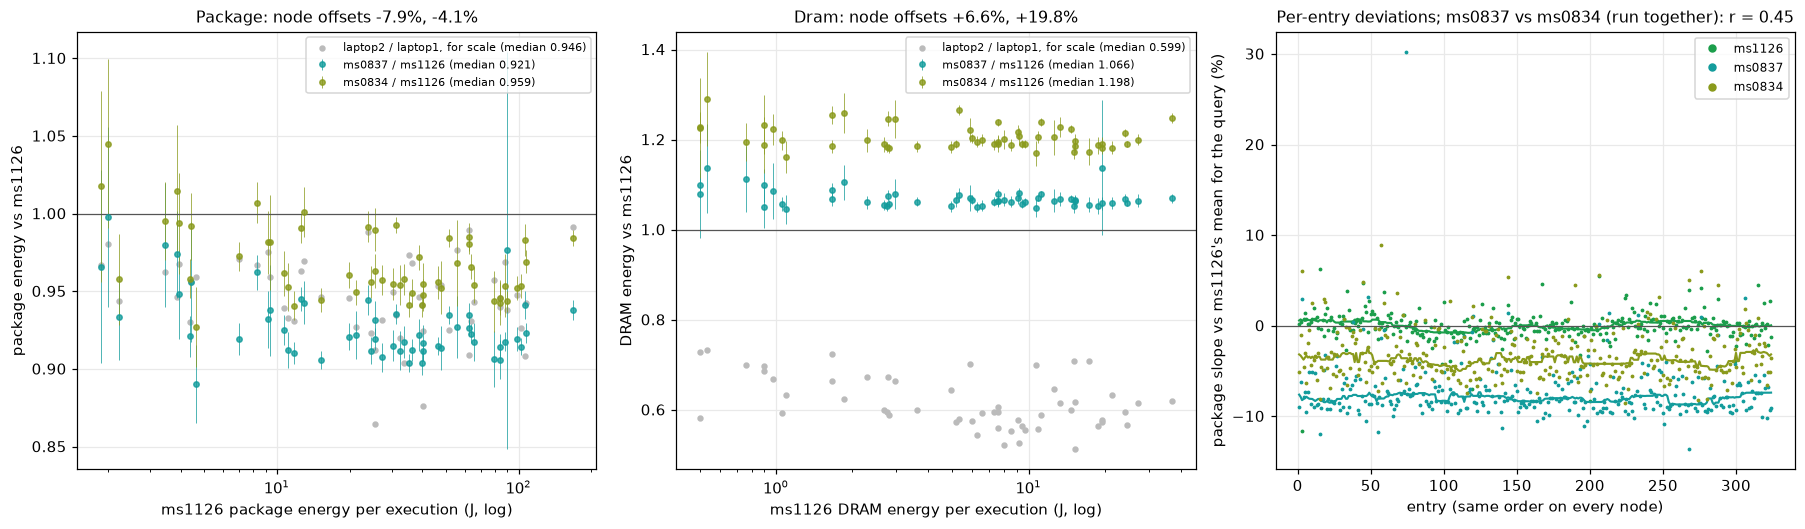

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.9))
for ax, col, nm in [(axes[0], "pkg", "package"), (axes[1], "dram", "DRAM")]:
    for b in NODES[1:]:
        x = ratio(NREF, b, col)
        ax.errorbar(x["a"], x["ratio"], yerr=[x["ratio"] - x["lo"], x["hi"] - x["ratio"]], fmt="o", ms=3.5,
                    color=COL[b], ecolor=COL[b], elinewidth=0.6, alpha=0.8, label=f"{b} / {NREF} (median {x['ratio'].median():.3f})")
    if "laptop2 PG16" in LBL:
        y = ratio("laptop1 PG16", "laptop2 PG16", col)
        ax.scatter(ratio(NREF, NODES[-1], col).reindex(y.index)["a"], y["ratio"], s=10, color="#bbb",
                   label=f"laptop2 / laptop1, for scale (median {y['ratio'].median():.3f})", zorder=1)
    ax.axhline(1, color="#555", lw=0.8)
    ax.set_xscale("log"); ax.set_xlabel(f"{NREF} {nm} energy per execution (J, log)")
    ax.set_ylabel(f"{nm} energy vs {NREF}"); ax.legend(fontsize=7.5)
    x0 = ratio(NREF, NODES[1], col)["ratio"].median() if len(NODES) > 1 else 1
    ax.set_title(f"{nm.capitalize()}: node offsets " + ", ".join(
        f"{100 * (ratio(NREF, b, col)['ratio'].median() - 1):+.1f}%" for b in NODES[1:]), fontsize=10.5)
ax = axes[2]
mref = E[NREF].groupby("q")["pkg"].mean()
DEV = {}
for l in NODES:
    e = E[l]
    DEV[l] = pd.Series((e["pkg"] / e["q"].map(mref) - 1).to_numpy(), index=e["entry"])
    ax.plot(DEV[l].index, 100 * DEV[l], ".", ms=3, color=COL[l], label=l)
    ax.plot(DEV[l].index, 100 * DEV[l].rolling(27, center=True, min_periods=10).median(), color=COL[l], lw=1.4)
ax.axhline(0, color="#555", lw=0.8)
ax.set_xlabel("entry (same order on every node)"); ax.set_ylabel(f"package slope vs {NREF}'s mean for the query (%)")
ax.legend(fontsize=8, markerscale=3)
if len(NODES) >= 3:
    both = pd.concat([DEV[NODES[1]], DEV[NODES[2]]], axis=1, join="inner")
    rc = both.corr().iloc[0, 1]
    ax.set_title(f"Per-entry deviations; {NODES[1]} vs {NODES[2]} (run together): r = {rc:.2f}", fontsize=10.5)
fig.tight_layout(); savefig(fig, "cloudlab_nodes"); plt.show()

**How many rounds and nodes?** With the round-to-round CV of a query's slope (`cv`) and the spread of node
offsets (`s_node`, the SD over the m510 nodes' offsets), the 95 % half-width of a query's mean over `k` nodes ×
`n` rounds is `1.96 · √(s_node² / k + cv² / (k·n))`. Below for package energy, with the median `cv` of each
machine's complete runs.

In [16]:
offs = np.array([1.0] + [ratio(NREF, b, "pkg")["ratio"].median() for b in NODES[1:]])
s_node = np.std(np.log(offs), ddof=1) if len(offs) >= 2 else np.nan
for a, b in REPEATS:
    print(f"session repeat {b} / {a}: package offset {100 * (ratio(a, b, 'pkg')['ratio'].median() - 1):+.1f}%")
CVM = {l: _cv(l, "pkg").median() for l in LBL if R.at[l, "complete"]}
print(f"node offsets (pkg, vs {NREF}): " + ", ".join(f"{v:.3f}" for v in offs) + f"  → s_node = {100 * s_node:.2f}%")
print("repeat CV of a query's package slope (median, complete runs): " + ", ".join(f"{l} {100 * v:.2f}%" for l, v in CVM.items()))
cv = CVM.get(NREF, np.nanmedian(list(CVM.values())))
grid = pd.DataFrame({f"{k} node{'s' * (k > 1)}": {f"{n} round{'s' * (n > 1)}": 1.96 * np.sqrt(s_node ** 2 / k + cv ** 2 / (k * n))
                                                 for n in [1, 2, 3, 6]} for k in [1, 2, 3, 5]})
print(f"\n95% half-width of a query's m510 package energy (cv {100 * cv:.2f}%, s_node {100 * s_node:.2f}%):")
print(grid.map(lambda v: f"±{100 * v:.1f}%").to_string())
print(f"\nrounds for ±1% on one machine (noise only): " + ", ".join(
    f"{l} {int(np.ceil((1.96 * v / 0.01) ** 2))}" for l, v in CVM.items()))

session repeat ms0834 #2 / ms0834: package offset +0.2%
session repeat ms0837 #2 / ms0837: package offset +0.0%
session repeat er063 #2 / er063: package offset -0.1%
node offsets (pkg, vs ms1126): 1.000, 0.921, 0.959  → s_node = 4.09%
repeat CV of a query's package slope (median, complete runs): laptop1 PG18 0.61%, laptop2 PG18 0.58%, laptop1 PG16 0.58%, laptop2 PG16 0.59%, ms1126 2.0 GHz 0.78%, ms1126 0.93%, ms0837 0.77%, ms0834 1.00%, ms0834 #2 0.82%, ms0837 #2 0.70%, er063 0.55%, er063 #2 0.42%, er063 g8 0.56%

95% half-width of a query's m510 package energy (cv 0.93%, s_node 4.09%):
         1 node 2 nodes 3 nodes 5 nodes
1 round   ±8.2%   ±5.8%   ±4.8%   ±3.7%
2 rounds  ±8.1%   ±5.7%   ±4.7%   ±3.6%
3 rounds  ±8.1%   ±5.7%   ±4.7%   ±3.6%
6 rounds  ±8.1%   ±5.7%   ±4.7%   ±3.6%

rounds for ±1% on one machine (noise only): laptop1 PG18 2, laptop2 PG18 2, laptop1 PG16 2, laptop2 PG16 2, ms1126 2.0 GHz 3, ms1126 4, ms0837 3, ms0834 4, ms0834 #2 3, ms0837 #2 2, er063 2, er063 #2 1, er

**Reading §6.**

* **Identical m510 nodes do the same work at different power.** Time agrees within ±0.1 % between the three
  nodes; package energy does not. ms0837 uses 7.9 % and ms0834 4.1 % less package energy than ms1126 on the median
  query. That is a node-to-node SD of about 4 %, similar in size to the 5 % gap between the two laptops.
* **The offset belongs to the node and reproduces exactly.** Each node's second session lands within 0.2 % of its
  first, with no query-specific spread and only 0–5 of 54 queries beyond noise. er063's second session matches to
  0.1 %. So the node offset is a stable property of the node, not something that changes per session.
* **Between ms0837 and ms0834 the difference is a pure constant.** ms0834 uses 4.4 % more than ms0837 with only
  0.2 % query-specific spread; they ran the same day in the same experiment. ms1126 differs from both by a
  constant plus about 2 % per-query scatter. It ran two days earlier in another experiment, so something in that
  setup differs beyond the node itself.
* **DRAM differs more than package.** Even after the ×0.25 unit fix on ms1126, DRAM differs by +7 % and +20 % per
  query, with idle DRAM of 0.6 / 0.9 / 1.6 W. Package + DRAM therefore partly cancels: ms0834 matches ms1126 within
  1 % in total, while ms0837 stays 5 % lower. Which zone a comparison uses changes the answer.
* **Running at the same time is not the same environment.** ms0837 and ms0834's per-entry deviations correlate
  only weakly (r ≈ 0.45); shared conditions explain little of the round-to-round noise.
* **Practical consequence.** A query measured on one m510 node has about ±8 % 95 % uncertainty from the node
  alone, and extra rounds on that node do not reduce it. Spreading over 3 nodes gives about ±4.7 %. Because the
  offset reproduces across sessions, a node can instead be *calibrated*: measure it once against a reference node
  and divide its results by its offset. What remains is the 0.2–2 % per-query scatter above plus the repeat
  noise. A single machine's repeat
  noise (median CV 0.4–1.0 %) needs only 1–4 rounds for ±1 %.

## 7. Rank order across RAPL zones and machines

Does the choice of meter change which queries count as expensive? Each machine ranks the 54 queries by its
per-query mean in every zone it has; agreement is Kendall's τ (1 = same order, 0 = unrelated; τ = 0.8 means 90 %
of query pairs are ordered the same way). Then the same across machines: does "query A uses less energy than B"
carry over from one machine to another?

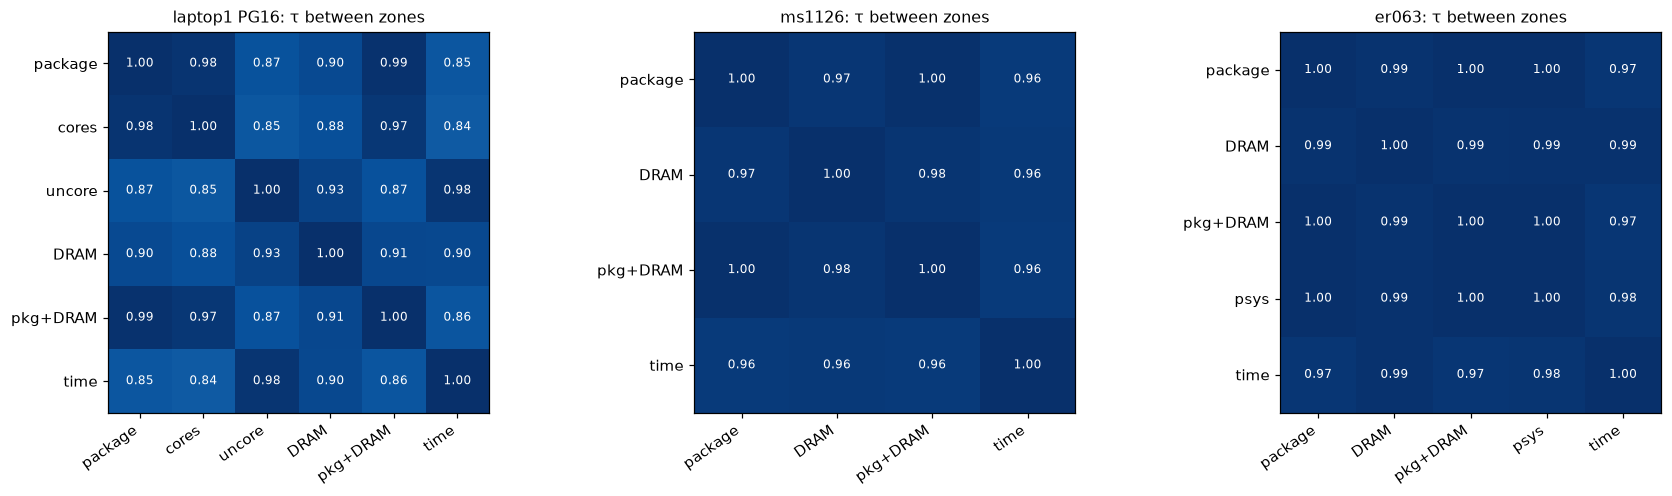

laptop1 PG18    vs package: cores τ=0.98 top10 10/10 bottom10 10/10; uncore τ=0.88 top10 9/10 bottom10 9/10; DRAM τ=0.91 top10 9/10 bottom10 10/10; pkg+DRAM τ=0.99 top10 10/10 bottom10 10/10; time τ=0.86 top10 8/10 bottom10 9/10
laptop2 PG18    vs package: cores τ=0.98 top10 10/10 bottom10 10/10; uncore τ=0.88 top10 9/10 bottom10 9/10; DRAM τ=0.91 top10 9/10 bottom10 10/10; pkg+DRAM τ=1.00 top10 10/10 bottom10 10/10; time τ=0.86 top10 8/10 bottom10 9/10
laptop1 PG16    vs package: cores τ=0.98 top10 10/10 bottom10 9/10; uncore τ=0.87 top10 9/10 bottom10 10/10; DRAM τ=0.90 top10 9/10 bottom10 9/10; pkg+DRAM τ=0.99 top10 10/10 bottom10 10/10; time τ=0.85 top10 8/10 bottom10 10/10
laptop2 PG16    vs package: cores τ=0.98 top10 10/10 bottom10 10/10; uncore τ=0.86 top10 9/10 bottom10 9/10; DRAM τ=0.91 top10 9/10 bottom10 9/10; pkg+DRAM τ=1.00 top10 10/10 bottom10 10/10; time τ=0.84 top10 8/10 bottom10 9/10
ms1126 2.0 GHz  vs package: DRAM τ=0.98 top10 9/10 bottom10 9/10; pkg+DRAM τ=0.99 top

In [17]:
ZL = {"pkg": "package", "core": "cores", "rest": "uncore", "dram": "DRAM", "total": "pkg+DRAM", "psys": "psys", "t": "time"}


def zone_means(l):
    return E[l].groupby("q")[[z for z in ZL if z in E[l]]].mean()


REP = [l for l in ["laptop1 PG16", NREF, "er063"] if l in LBL]
fig, axes = plt.subplots(1, len(REP), figsize=(5.4 * len(REP), 4.6))
TAUZ = {}
for ax, l in zip(np.atleast_1d(axes), REP):
    m = zone_means(l)
    zs = list(m.columns)
    tau = pd.DataFrame([[kendall(m[a], m[b]) for b in zs] for a in zs], index=zs, columns=zs)
    TAUZ[l] = tau
    ax.imshow(tau, cmap="Blues", vmin=0, vmax=1)
    for a in range(len(zs)):
        for b in range(len(zs)):
            ax.text(b, a, f"{tau.iat[a, b]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if tau.iat[a, b] > 0.6 else "#222")
    ax.set_xticks(range(len(zs))); ax.set_xticklabels([ZL[z] for z in zs], rotation=35, ha="right")
    ax.set_yticks(range(len(zs))); ax.set_yticklabels([ZL[z] for z in zs]); ax.grid(False)
    ax.set_title(f"{l}: τ between zones", fontsize=10.5)
fig.tight_layout(); savefig(fig, "rank_zones"); plt.show()


def topk(a, b, k=10):
    return len(set(a.nlargest(k).index) & set(b.nlargest(k).index)), len(set(a.nsmallest(k).index) & set(b.nsmallest(k).index))


for l in MAIN:
    m = zone_means(l)
    print(f"{l:15s} vs package: " + "; ".join(
        f"{ZL[z]} τ={kendall(m['pkg'], m[z]):.2f} top10 {topk(m['pkg'], m[z])[0]}/10 bottom10 {topk(m['pkg'], m[z])[1]}/10"
        for z in m.columns if z != "pkg"))

In [18]:
def movers(l, z, n=6):
    m = zone_means(l)
    rk = m[["pkg", z]].rank(ascending=False)
    d = (rk[z] - rk["pkg"]).abs().nlargest(n).index
    out = pd.DataFrame({"kind": KIND[d], "rank package": rk.loc[d, "pkg"].astype(int), f"rank {ZL[z]}": rk.loc[d, z].astype(int),
                        "package (J)": m.loc[d, "pkg"], f"{ZL[z]} (J)": m.loc[d, z],
                        f"{ZL[z]} / package": m.loc[d, z] / m.loc[d, "pkg"], "time (s)": m.loc[d, "t"]})
    return out


for l, z in [("laptop1 PG16", "dram"), ("laptop1 PG16", "rest"), (NREF, "dram"), ("er063", "dram"), ("er063", "psys")]:
    if l in LBL and z in E[l]:
        print(f"\n{l}: largest rank changes, package → {ZL[z]} (rank 1 = most expensive; median {ZL[z]}/package "
              f"{(zone_means(l)[z] / zone_means(l)['pkg']).median():.3f})")
        print(movers(l, z).round(4).to_string())


laptop1 PG16: largest rank changes, package → DRAM (rank 1 = most expensive; median DRAM/package 0.108)
           kind  rank package  rank DRAM  package (J)  DRAM (J)  DRAM / package  time (s)
q                                                                                        
14349  sqlstorm             9          3      21.5405    3.6924          0.1714    3.6147
7046   sqlstorm            17         11      16.3226    2.1711          0.1330    2.3748
10937  sqlstorm            40         45       3.3585    0.2437          0.0726    0.2909
14510  sqlstorm            10         15      21.1541    1.6917          0.0800    2.0057
10646  sqlstorm            50         46       1.2803    0.1588          0.1241    0.1740
12477  sqlstorm             3          7      38.5242    3.1961          0.0830    2.6268

laptop1 PG16: largest rank changes, package → uncore (rank 1 = most expensive; median uncore/package 0.178)
                kind  rank package  rank uncore  package (J)  unco

**Rank-order bars.** Each panel puts the 54 queries in the order of one measure (most expensive on the left)
and draws the bars with another. A **teal** bar holds the same rank in both orders. A **grey** bar is labelled
with its shift: `+k` means the query sits `k` places further right, i.e. cheaper, in the bar measure's own order,
and `−k` means `k` places further left. The y axis is logarithmic because the queries span three orders of
magnitude. Below: the other zones of one machine, each ordered by that machine's package energy.

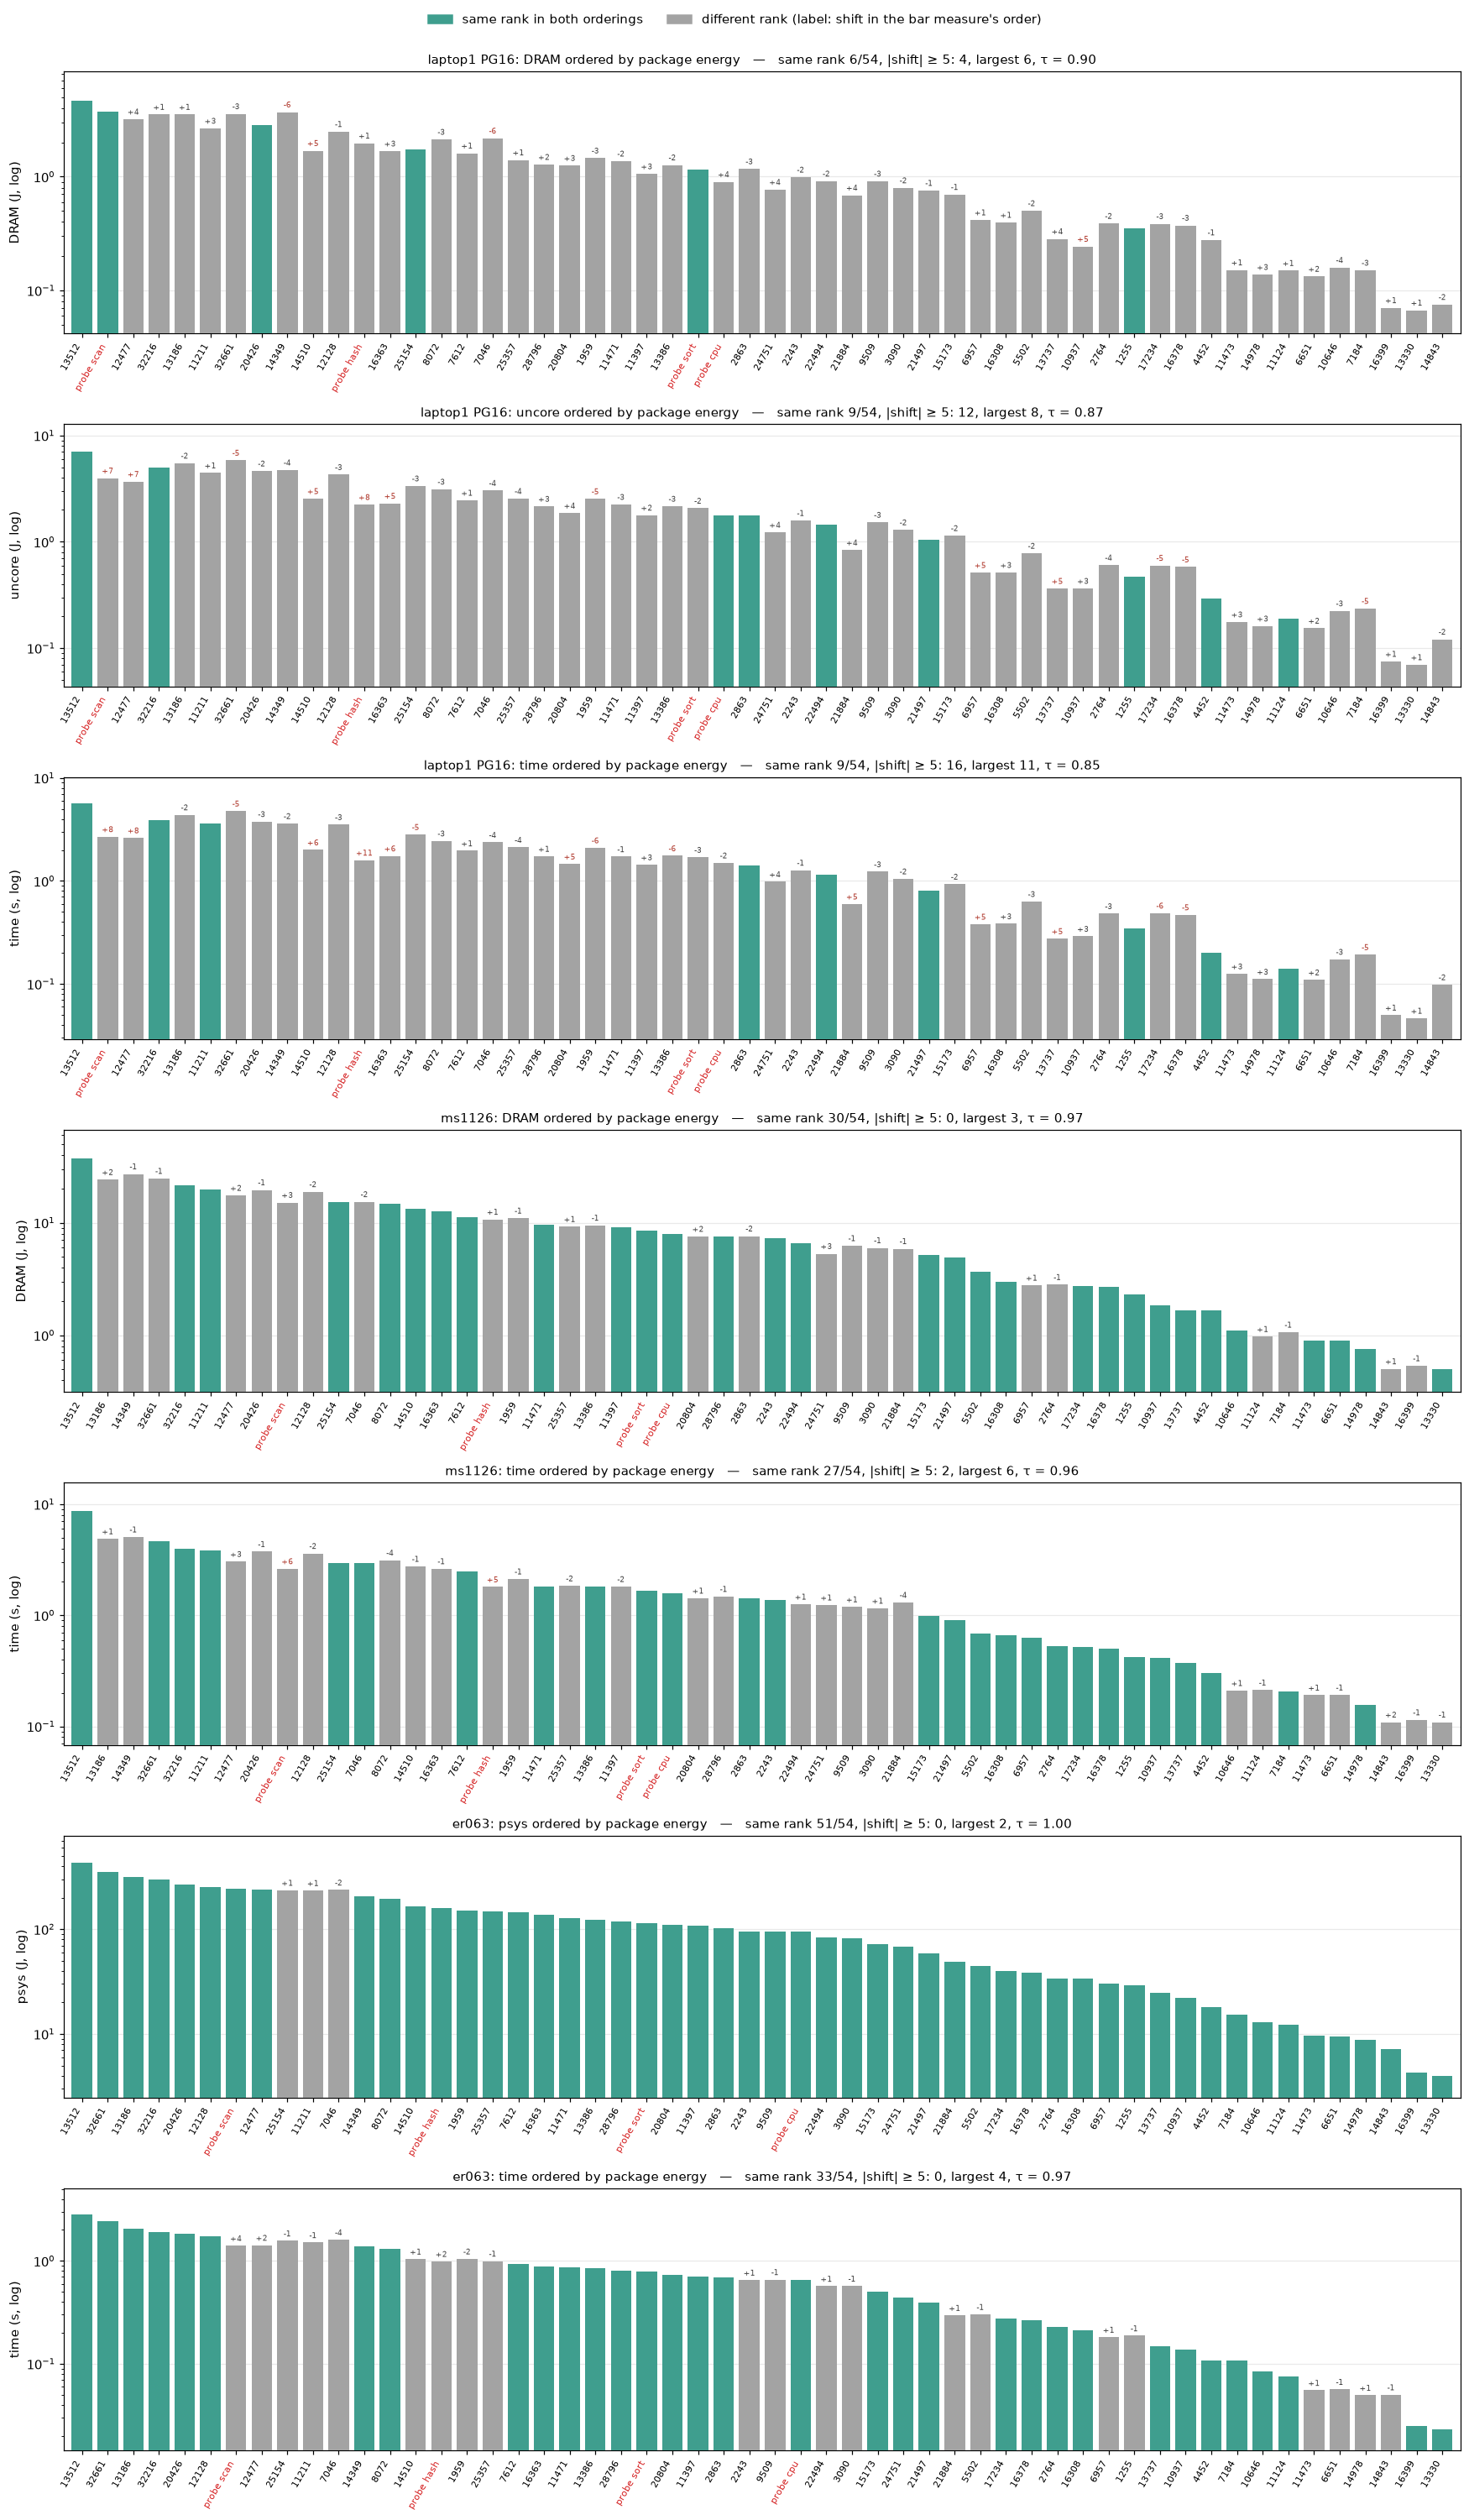

In [19]:
ZP = []
for l, z, unit in [("laptop1 PG16", "dram", "J"), ("laptop1 PG16", "rest", "J"), ("laptop1 PG16", "t", "s"),
                   (NREF, "dram", "J"), (NREF, "t", "s"), ("er063", "psys", "J"), ("er063", "t", "s")]:
    if l in LBL and z in E[l]:
        m = zone_means(l)
        ZP.append((m["pkg"], m[z], f"{l}: {ZL[z]} ordered by package energy", f"{ZL[z]} ({unit}, log)"))
rank_figure(ZP, "rank_bars_zones")

**Across machines.** τ of the package-energy order between every pair of runs (left) and of the time order
(middle). Right: a stricter test that ignores pairs too close to call — among query pairs whose difference is
beyond 3σ of the repeat noise on **both** runs, the share ordered the other way round.

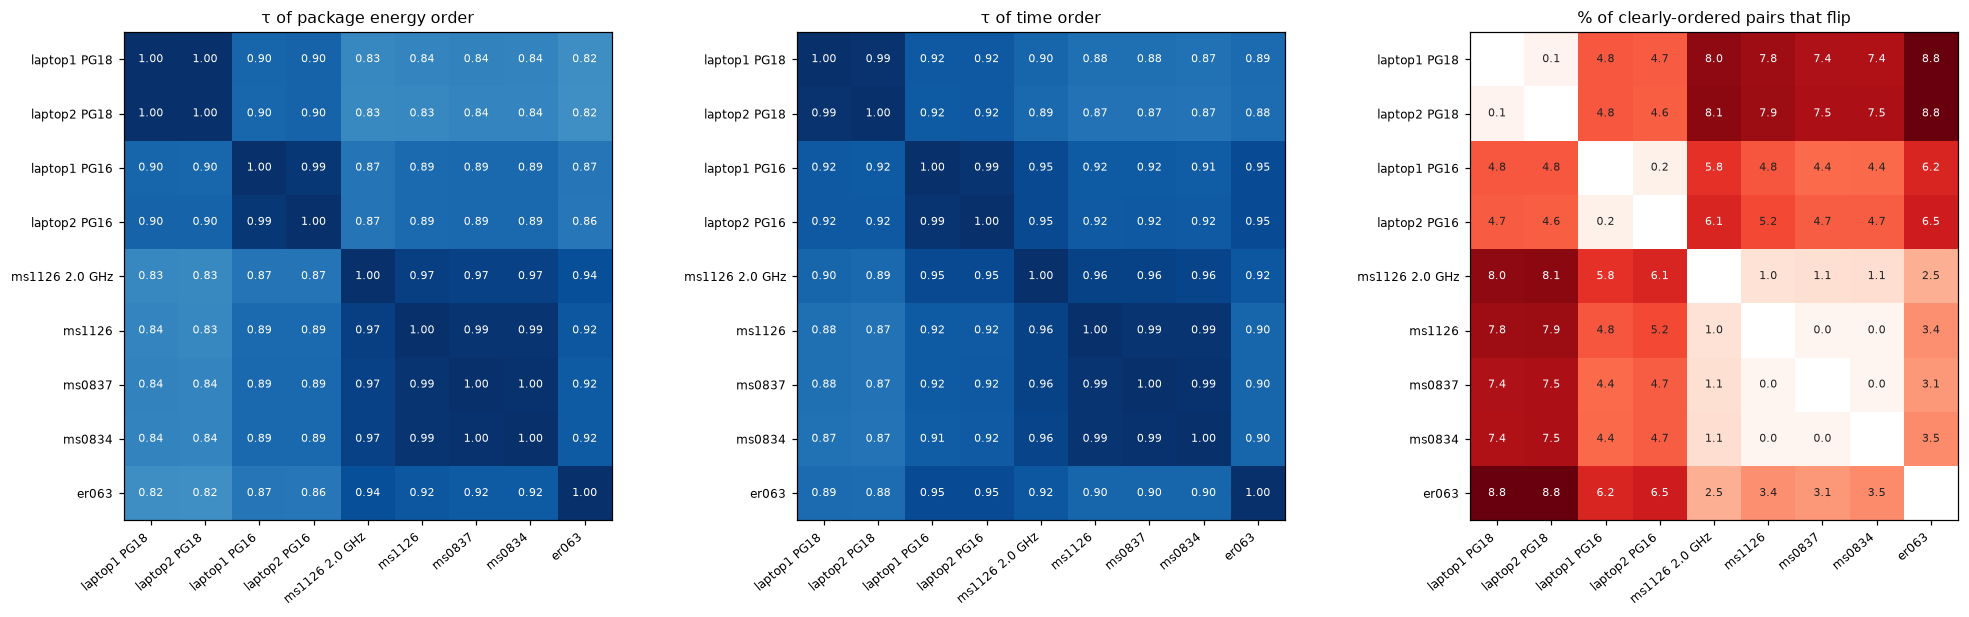

54 queries in every run.  τ package energy: laptops among themselves 0.90+, m510 nodes among themselves 0.97+
laptop1 PG16 vs ms1126: τ energy 0.888, time 0.916; 1405/1431 pairs clearly ordered on both, 68 flipped: 10646/11473, 10646/14978, 10646/6651, 10937/13737, 10937/16378, 10937/17234, 10937/2764, 11124/11473 …
laptop1 PG16 vs er063: τ energy 0.866, time 0.947; 1413/1431 pairs clearly ordered on both, 87 flipped: 10646/11124, 10646/11473, 10646/14978, 10646/6651, 10646/7184, 10937/1255, 10937/16378, 10937/17234 …
ms1126 vs er063: τ energy 0.925, time 0.897; 1416/1431 pairs clearly ordered on both, 48 flipped: 10646/7184, 10937/13737, 11211/12128, 11211/12477, 11211/14349, 11211/20426, 11211/probe_scan, 11397/20804 …
laptop1 PG16 vs laptop1 PG18: τ energy 0.898, time 0.922; 1413/1431 pairs clearly ordered on both, 68 flipped: 10937/24751, 11211/12477, 11211/14510, 11211/32216, 11397/20804, 11397/7612, 11471/7612, 12128/12477 …


In [20]:
MP = {l: E[l].groupby("q")["pkg"].mean() for l in MAIN}
MTM = {l: E[l].groupby("q")["t"].mean() for l in MAIN}
qs = sorted(set.intersection(*[set(MP[l].index) for l in MAIN]))
TAU_E = pd.DataFrame([[kendall(MP[a][qs], MP[b][qs]) for b in MAIN] for a in MAIN], index=MAIN, columns=MAIN)
TAU_T = pd.DataFrame([[kendall(MTM[a][qs], MTM[b][qs]) for b in MAIN] for a in MAIN], index=MAIN, columns=MAIN)


def flips(a, b, col="pkg"):
    A, B = per_query(a, col).align(per_query(b, col), join="inner", axis=0)
    i, j = np.triu_indices(len(A), 1)
    dA, dB = A["mean"].to_numpy()[i] - A["mean"].to_numpy()[j], B["mean"].to_numpy()[i] - B["mean"].to_numpy()[j]
    sA = np.hypot(A["se"].to_numpy()[i], A["se"].to_numpy()[j])
    sB = np.hypot(B["se"].to_numpy()[i], B["se"].to_numpy()[j])
    res = (np.abs(dA) > 3 * sA) & (np.abs(dB) > 3 * sB)
    flip = res & (np.sign(dA) != np.sign(dB))
    pairs = [(A.index[x], A.index[y]) for x, y in zip(i[flip], j[flip])]
    return res.sum(), flip.sum(), len(i), pairs


FL = {(a, b): flips(a, b) for a in MAIN for b in MAIN if a != b}
FLIP = pd.DataFrame([[np.nan if a == b else FL[(a, b)][1] / max(FL[(a, b)][0], 1) for b in MAIN] for a in MAIN], index=MAIN, columns=MAIN)

fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.6))
for ax, M, ttl, cm, vmin, vmax, fmt in [
        (axes[0], TAU_E, "τ of package energy order", "Blues", 0.5, 1, "{:.2f}"),
        (axes[1], TAU_T, "τ of time order", "Blues", 0.5, 1, "{:.2f}"),
        (axes[2], 100 * FLIP, "% of clearly-ordered pairs that flip", "Reds", 0, max(5, np.nanmax(100 * FLIP.to_numpy())), "{:.1f}")]:
    ax.imshow(M.astype(float), cmap=cm, vmin=vmin, vmax=vmax)
    for a in range(len(MAIN)):
        for b in range(len(MAIN)):
            v = M.iat[a, b]
            if pd.notna(v):
                ax.text(b, a, fmt.format(v), ha="center", va="center", fontsize=7,
                        color="white" if (v - vmin) / (vmax - vmin) > 0.6 else "#222")
    ax.set_xticks(range(len(MAIN))); ax.set_xticklabels(MAIN, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(MAIN))); ax.set_yticklabels(MAIN, fontsize=8); ax.grid(False)
    ax.set_title(ttl, fontsize=10.5)
fig.tight_layout(); savefig(fig, "rank_machines"); plt.show()

print(f"{len(qs)} queries in every run.  τ package energy: laptops among themselves "
      f"{np.nanmin(TAU_E.loc[[l for l in MAIN if R.at[l, 'hw'] == 'laptop'], [l for l in MAIN if R.at[l, 'hw'] == 'laptop']].to_numpy()):.2f}+, "
      f"m510 nodes among themselves {np.nanmin(TAU_E.loc[[l for l in MAIN if R.at[l, 'hw'] == 'm510'], [l for l in MAIN if R.at[l, 'hw'] == 'm510']].to_numpy()):.2f}+")
for a, b in [("laptop1 PG16", NREF), ("laptop1 PG16", "er063"), (NREF, "er063"), ("laptop1 PG16", "laptop1 PG18")]:
    if a in LBL and b in LBL:
        res, fl, n, pairs = FL[(a, b)]
        print(f"{a} vs {b}: τ energy {TAU_E.at[a, b]:.3f}, time {TAU_T.at[a, b]:.3f}; {res}/{n} pairs clearly ordered on both, "
              f"{fl} flipped" + (": " + ", ".join(f"{x}/{y}" for x, y in pairs[:8]) + (" …" if len(pairs) > 8 else "") if fl else ""))

The same rank-order bars across runs: package energy on one run, ordered by package energy on another — an
identical m510 node, the other laptop, the other PostgreSQL version, and the two server types against laptop1.

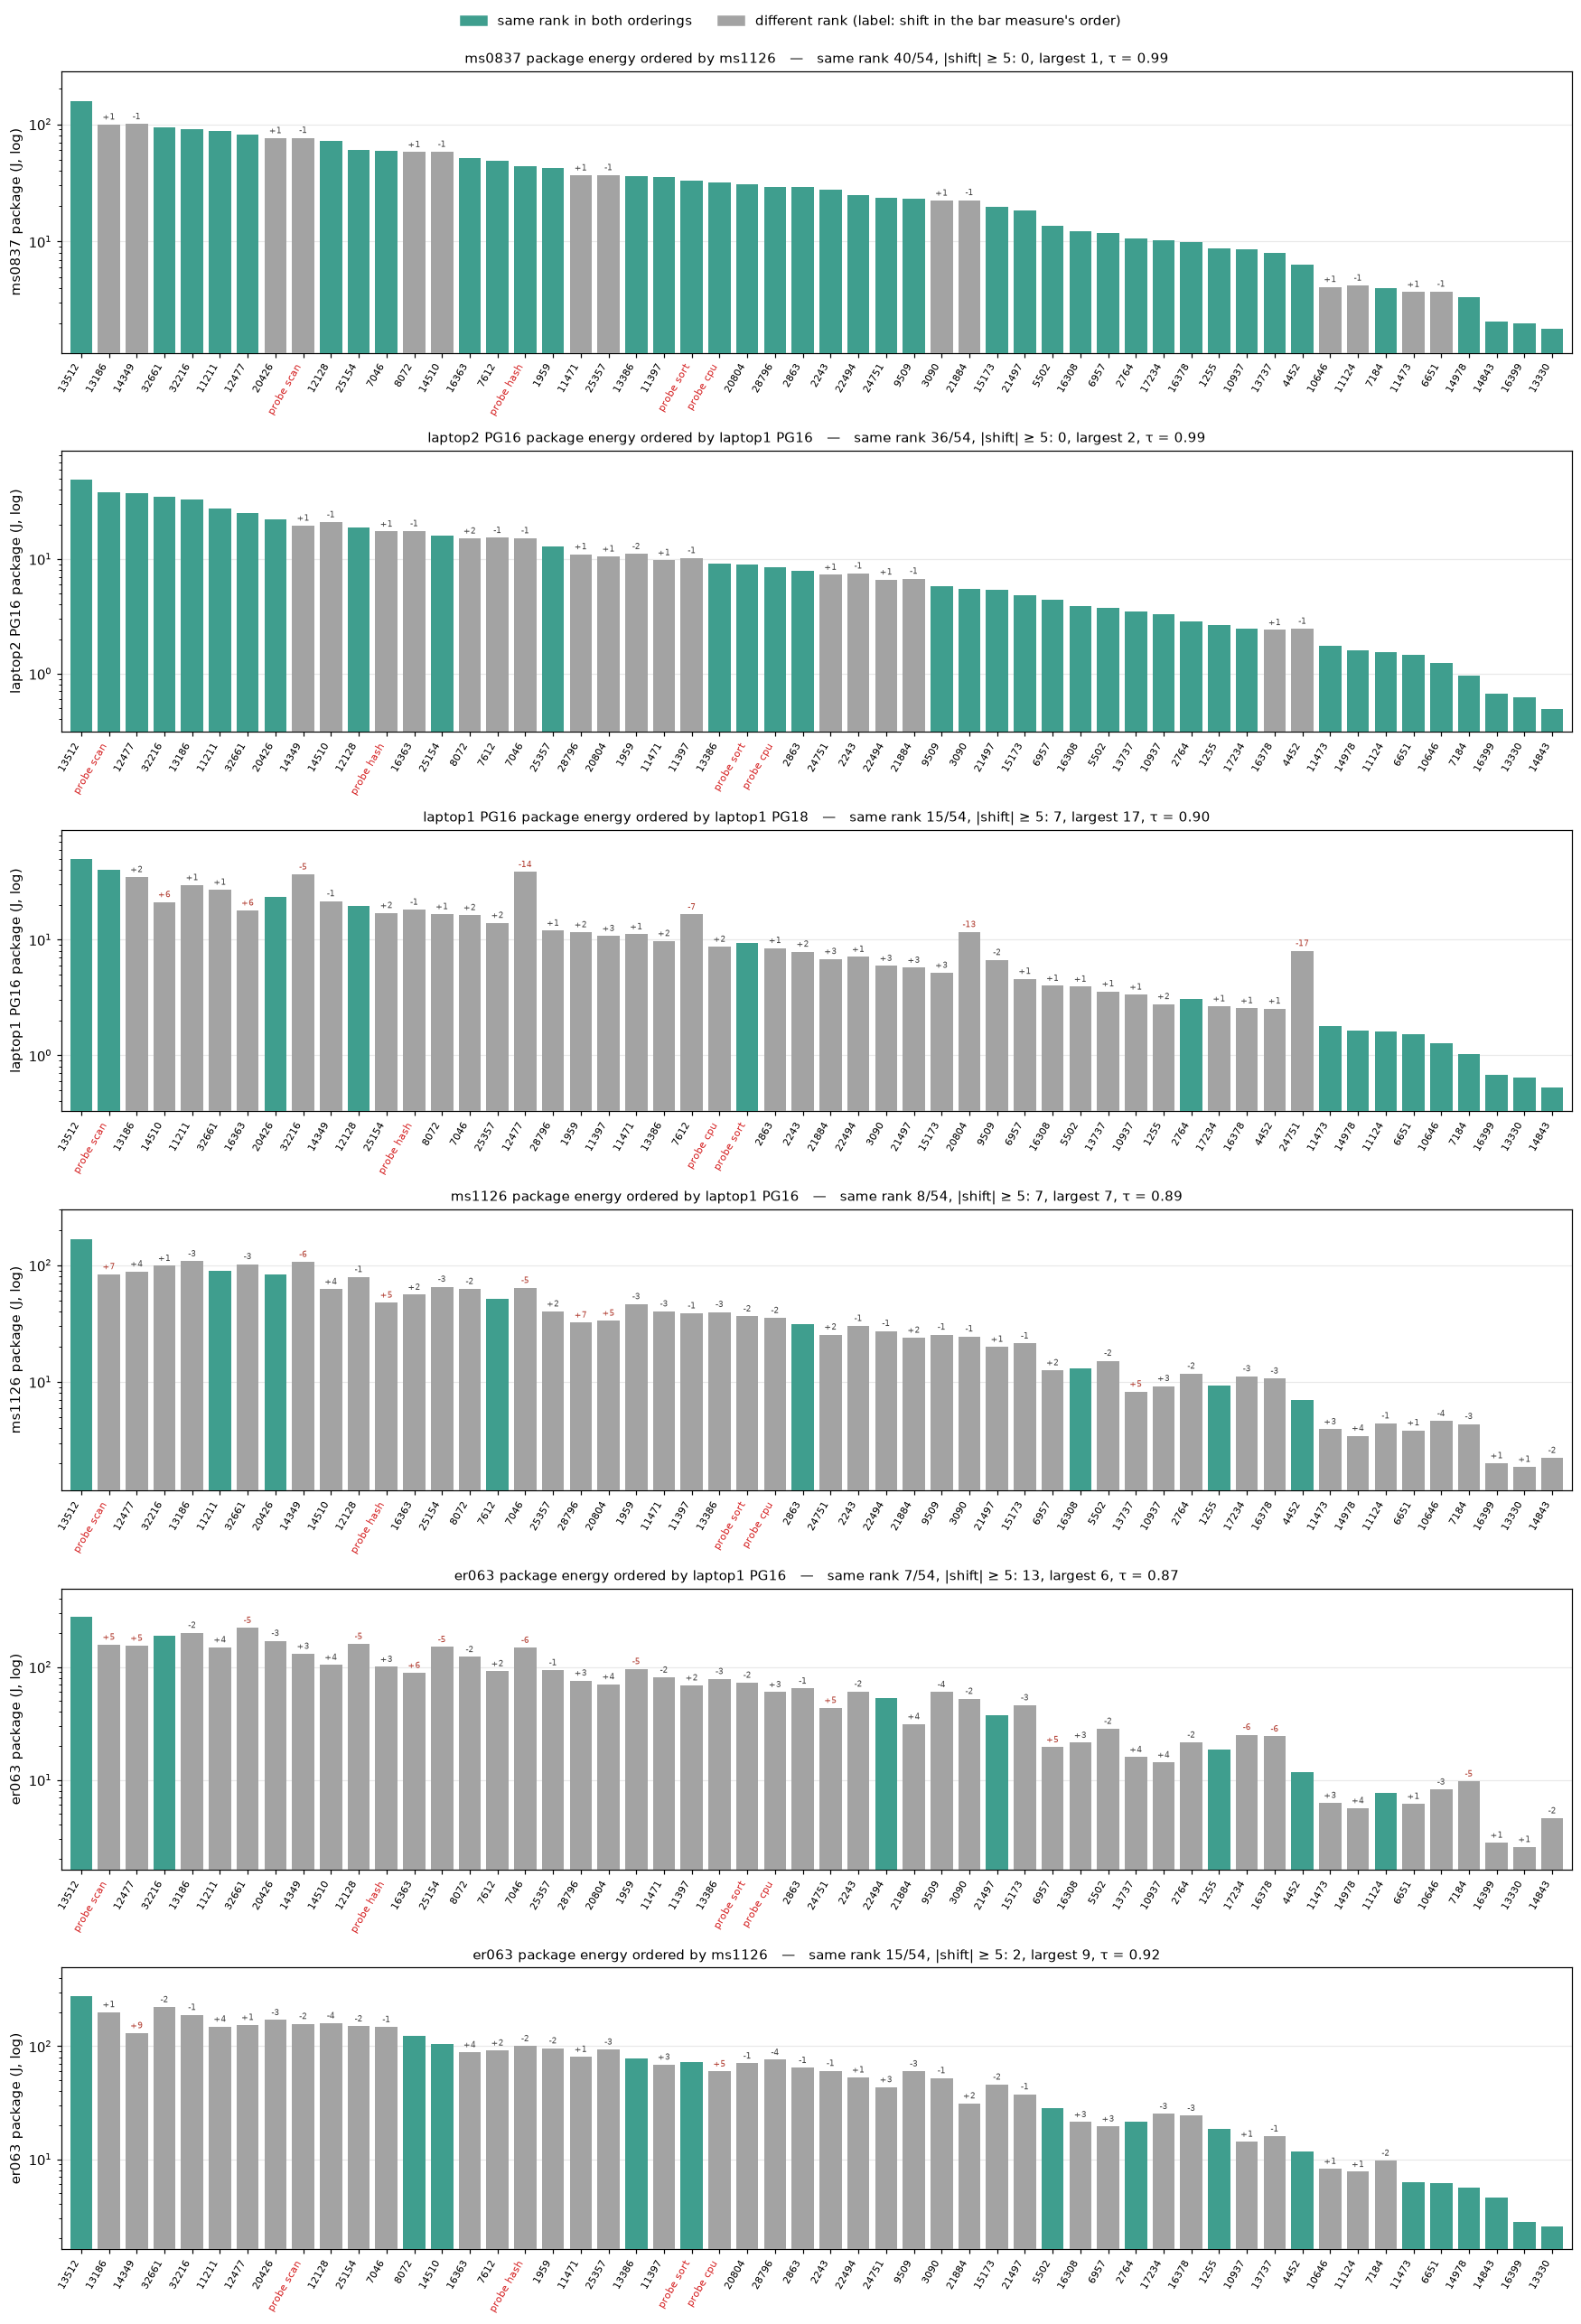

In [21]:
MPAN = []
for a, b in [(NREF, NODES[1] if len(NODES) > 1 else None), ("laptop1 PG16", "laptop2 PG16"),
             ("laptop1 PG18", "laptop1 PG16"), ("laptop1 PG16", NREF), ("laptop1 PG16", "er063"), (NREF, "er063")]:
    if a in LBL and b in LBL:
        MPAN.append((MP[a], MP[b], f"{b} package energy ordered by {a}", f"{b} package (J, log)"))
rank_figure(MPAN, "rank_bars_machines")

**Reading §7.**

* **Within a machine, the zone choice matters on the laptops and hardly on the servers.**
  * On the laptops, cores and package rank queries almost the same way (τ 0.98), and package + DRAM equals package
    (τ ≥ 0.99). The uncore and DRAM orders differ more (τ 0.87–0.91). Uncore follows time almost exactly
    (τ 0.98), as a nearly constant power would.
  * On the servers every zone and time agree (τ ≥ 0.96). This is what the idle-dominated power of §4 predicts.
    psys on er063 is about 1.57× package for every query (τ 1.00), so it adds no ranking information.
  * The 10 most and least expensive queries are the same 9–10 in every zone.
* **Across machines, identical hardware gives the same order.** Among the three m510 nodes τ is 0.98–0.99, and
  ≤ 0.1 % of clearly-ordered pairs flip. Between the two laptops on one PostgreSQL version τ is 0.99–1.00.
* **Hardware and version change the order more:**
  * Laptop vs server: τ 0.82–0.89.
  * PG18 vs PG16 on the same laptop: τ 0.90.
  * Among query pairs that are clearly ordered on both runs, 3–9 % flip between hardware types or versions.
  * The flips concentrate on short queries such as 10646, 10937 and 11124. There a fixed per-execution cost that
    differs between machines can outweigh the work itself.
* **Between laptops and servers, time orders agree better than energy orders,** e.g. laptop1 vs er063: τ 0.95
  for time, 0.87 for energy. The laptops' energy order carries their uncore and DRAM differences (above); the
  servers' energy order is mostly time.

## 8. C6620 with more parallel workers (`turbo_g8`)

er063 ran the set again with PostgreSQL allowed more parallelism (session `turbo_g8`): everything else — clock,
gate, order, data, buffers, `work_mem` — as in its first run. The table below lists the parameters that differ.
The C6620 has 28 cores / 56 threads, so the default limit of 4 workers per gather leaves most of it idle even
with 16 copies.

Each query's g8 slope is compared with er063's first run. er063's second session with the original settings
(`er063 #2`) is the yardstick: a g8 change only means something where it is larger than the change between two
sessions with identical settings.

In [22]:
C6 = [l for l in LBL if R.at[l, "hw"] == "c6620"]
CBASE = next((l for l in C6 if R.at[l, "role"] == "main"), None)
CVAR = [l for l in C6 if R.at[l, "role"] == "variant"]
CREP = [l for l in C6 if R.at[l, "role"] == "repeat"]
keys = sorted(set().union(*[PAR[l] for l in C6]))
PD = pd.DataFrame({l: {k: PAR[l].get(k, "(default)") for k in keys} for l in C6})
print("PostgreSQL parameters set by each er063 session (only those that differ between them):")
print(PD[PD.nunique(axis=1) > 1].to_string())

STAT = {}
for v in CVAR + CREP:
    re_, rt = ratio(CBASE, v, "pkg"), ratio(CBASE, v, "t")
    rp = ratio(CBASE, v, "psys") if "psys" in E[v] and "psys" in E[CBASE] else None
    pw = (re_["b"] / rt["b"]) / (re_["a"] / rt["a"])
    STAT[v] = {"energy (median query)": re_["ratio"].median(), "energy (one pass)": set_ratio(CBASE, v),
               "time (median query)": rt["ratio"].median(), "time (one pass)": set_ratio(CBASE, v, "t"),
               "power while running (median)": pw.median(),
               "psys (one pass)": set_ratio(CBASE, v, "psys") if rp is not None else np.nan,
               "energy lower beyond noise": int((re_["hi"] < 1).sum()), "energy higher beyond noise": int((re_["lo"] > 1).sum()),
               "idle package (W)": I[v]["idle_pkg_w"].median()}
print(f"\nvs {CBASE} (idle package {I[CBASE]['idle_pkg_w'].median():.1f} W):")
print(pd.DataFrame(STAT).round(3).to_string())

PostgreSQL parameters set by each er063 session (only those that differ between them):
                                     er063   er063 #2 er063 g8
max_parallel_workers             (default)  (default)        8
max_parallel_workers_per_gather          4          4        8
max_worker_processes             (default)  (default)        8
min_parallel_index_scan_size     (default)  (default)     64kB
min_parallel_table_scan_size     (default)  (default)      1MB

vs er063 (idle package 63.2 W):
                              er063 g8  er063 #2
energy (median query)            1.001     0.999
energy (one pass)                0.988     0.999
time (median query)              0.996     1.001
time (one pass)                  0.969     1.001
power while running (median)     1.012     0.999
psys (one pass)                  0.986     1.000
energy lower beyond noise       19.000     0.000
energy higher beyond noise      19.000     0.000
idle package (W)                62.648    63.062


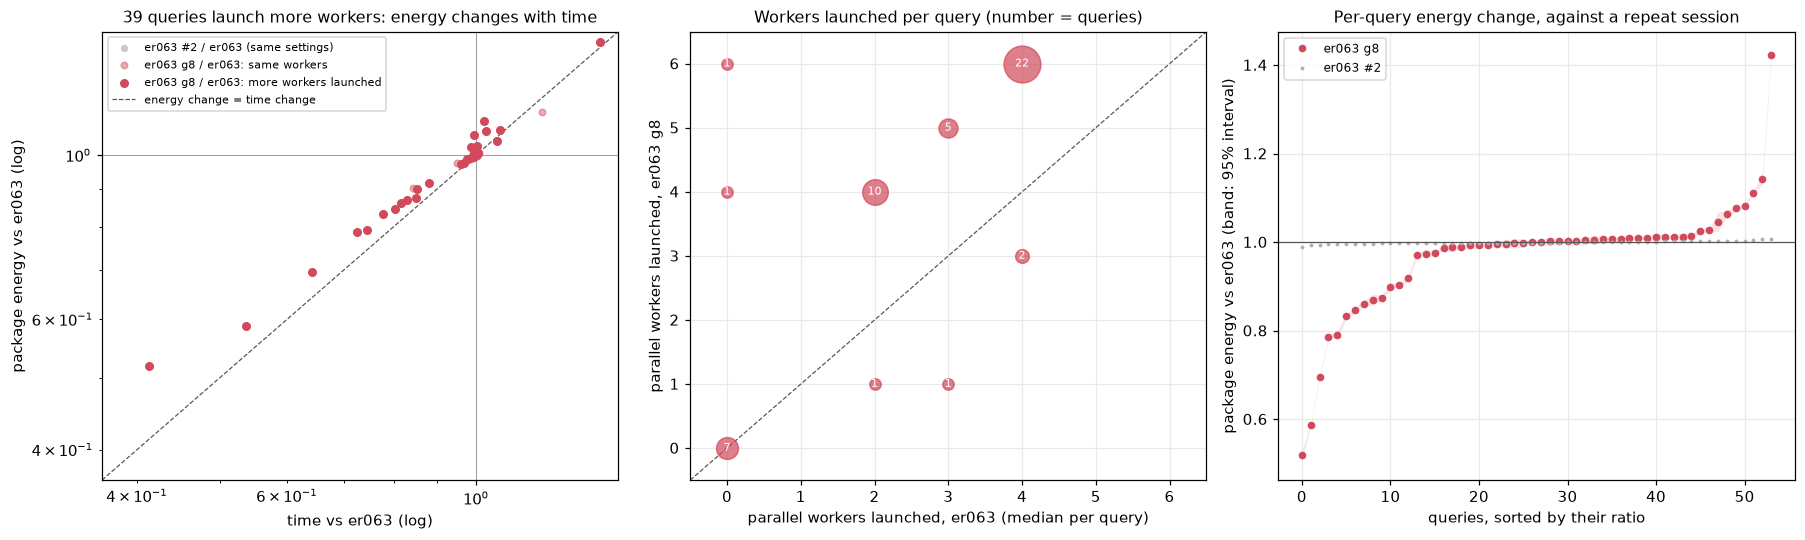

er063 g8: 39 SQLStorm queries launch more workers; their median energy ratio 0.996, time 0.992;  queries with the same workers: energy 1.001, time 1.002
           kind  energy   time workers er063→g8 exec ms er063→g8
q                                                               
14843  sqlstorm   0.519  0.413              0→6            48→20
12128  sqlstorm   0.588  0.537              0→4         1743→937
10937  sqlstorm   0.696  0.642              2→4           137→88
14510  sqlstorm   1.423  1.398              2→4        1042→1454
11124  sqlstorm   0.787  0.724              2→4            74→53
16308  sqlstorm   0.791  0.744              2→4          210→156
6651   sqlstorm   0.833  0.778              3→5            56→43
11473  sqlstorm   0.846  0.804              4→6            55→44
14978  sqlstorm   0.861  0.817              4→6            49→40
16399  sqlstorm   0.870  0.829              4→6            24→20
13512  sqlstorm   0.875  0.850              2→4        2801→2363
44

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5))
WCH = {}
for v in CVAR:
    WCH[v] = pd.Series({q: S[v].at[q, "workers"] - S[CBASE].at[q, "workers"]
                        for q in S[v].index.intersection(S[CBASE].index)})
ax = axes[0]
for v in CREP:
    re_, rt = ratio(CBASE, v, "pkg"), ratio(CBASE, v, "t")
    ax.scatter(rt["ratio"], re_["ratio"], s=14, color="#c9c9c9", label=f"{v} / {CBASE} (same settings)", zorder=2)
for v in CVAR:
    re_, rt = ratio(CBASE, v, "pkg"), ratio(CBASE, v, "t")
    more = WCH[v].reindex(re_.index).fillna(0) > 0
    ax.scatter(rt["ratio"][~more], re_["ratio"][~more], s=18, color=COL.get(v, "#d1495b"), alpha=0.45,
               label=f"{v} / {CBASE}: same workers", zorder=3)
    ax.scatter(rt["ratio"][more], re_["ratio"][more], s=24, color=COL.get(v, "#d1495b"),
               label=f"{v} / {CBASE}: more workers launched", zorder=4)
lim = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lim, lim, color="#555", lw=0.8, ls="--", label="energy change = time change")
ax.axhline(1, color="#999", lw=0.6); ax.axvline(1, color="#999", lw=0.6)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel(f"time vs {CBASE} (log)"); ax.set_ylabel(f"package energy vs {CBASE} (log)"); ax.legend(fontsize=7.5)
if CVAR:
    v = CVAR[0]
    mq = WCH[v][WCH[v] > 0].index
    ax.set_title(f"{len(mq)} queries launch more workers: energy changes with time", fontsize=10.5)
ax = axes[1]
for v in CVAR:
    w0 = S[CBASE]["workers"].reindex(WCH[v].index)
    w1 = S[v]["workers"].reindex(WCH[v].index)
    cnt = pd.crosstab(w0, w1)
    for (a, b), n in cnt.stack().items():
        if n:
            ax.scatter(a, b, s=30 + 25 * n, color=COL.get(v, "#d1495b"), alpha=0.7, zorder=3)
            ax.text(a, b, str(n), ha="center", va="center", fontsize=7, color="white", zorder=4)
    mx = max(w0.max(), w1.max()) + 0.5
    ax.plot([-0.5, mx], [-0.5, mx], color="#555", lw=0.8, ls="--")
    ax.set_xlim(-0.5, mx); ax.set_ylim(-0.5, mx)
ax.set_xlabel(f"parallel workers launched, {CBASE} (median per query)")
ax.set_ylabel("parallel workers launched, " + ", ".join(CVAR))
ax.set_title("Workers launched per query (number = queries)", fontsize=10.5)
ax = axes[2]
for v in CVAR + CREP:
    re_ = ratio(CBASE, v, "pkg")
    d = re_.sort_values("ratio")
    ax.plot(np.arange(len(d)), d["ratio"], "o" if v in CVAR else ".", ms=4 if v in CVAR else 3,
            color=COL.get(v, "#d1495b") if v in CVAR else "#b0b0b0", label=v)
    if v in CVAR:
        ax.fill_between(np.arange(len(d)), d["lo"], d["hi"], color=COL.get(v, "#d1495b"), alpha=0.15, lw=0)
ax.axhline(1, color="#555", lw=0.8)
ax.set_xlabel("queries, sorted by their ratio"); ax.set_ylabel(f"package energy vs {CBASE} (band: 95% interval)")
ax.legend(fontsize=8)
ax.set_title("Per-query energy change, against a repeat session", fontsize=10.5)
fig.tight_layout(); savefig(fig, "c6620_g8"); plt.show()

for v in CVAR:
    re_, rt = ratio(CBASE, v, "pkg"), ratio(CBASE, v, "t")
    more = WCH[v][WCH[v] > 0].index
    same_w = re_.index.difference(more)
    print(f"{v}: {len(more)} SQLStorm queries launch more workers; their median energy ratio {re_.loc[more, 'ratio'].median():.3f}, "
          f"time {rt.loc[more, 'ratio'].median():.3f};  queries with the same workers: energy {re_.loc[same_w, 'ratio'].median():.3f}, "
          f"time {rt.loc[same_w, 'ratio'].median():.3f}")
    T7 = pd.DataFrame({"kind": KIND[re_.index], "energy": re_["ratio"], "time": rt["ratio"],
                       f"workers {CBASE}→{v.split()[-1]}": [f"{S[CBASE]['workers'].get(q, np.nan):g}→{S[v]['workers'].get(q, np.nan):g}"
                                                         if q in S[v].index else "-" for q in re_.index],
                       f"exec ms {CBASE}→{v.split()[-1]}": [f"{S[CBASE]['exec_ms'].get(q, np.nan):.0f}→{S[v]['exec_ms'].get(q, np.nan):.0f}"
                                                         if q in S[v].index else "-" for q in re_.index]})
    T7["|log|"] = np.log(T7["energy"]).abs()
    print(T7.sort_values("|log|", ascending=False).drop(columns="|log|").head(12).round(3).to_string())

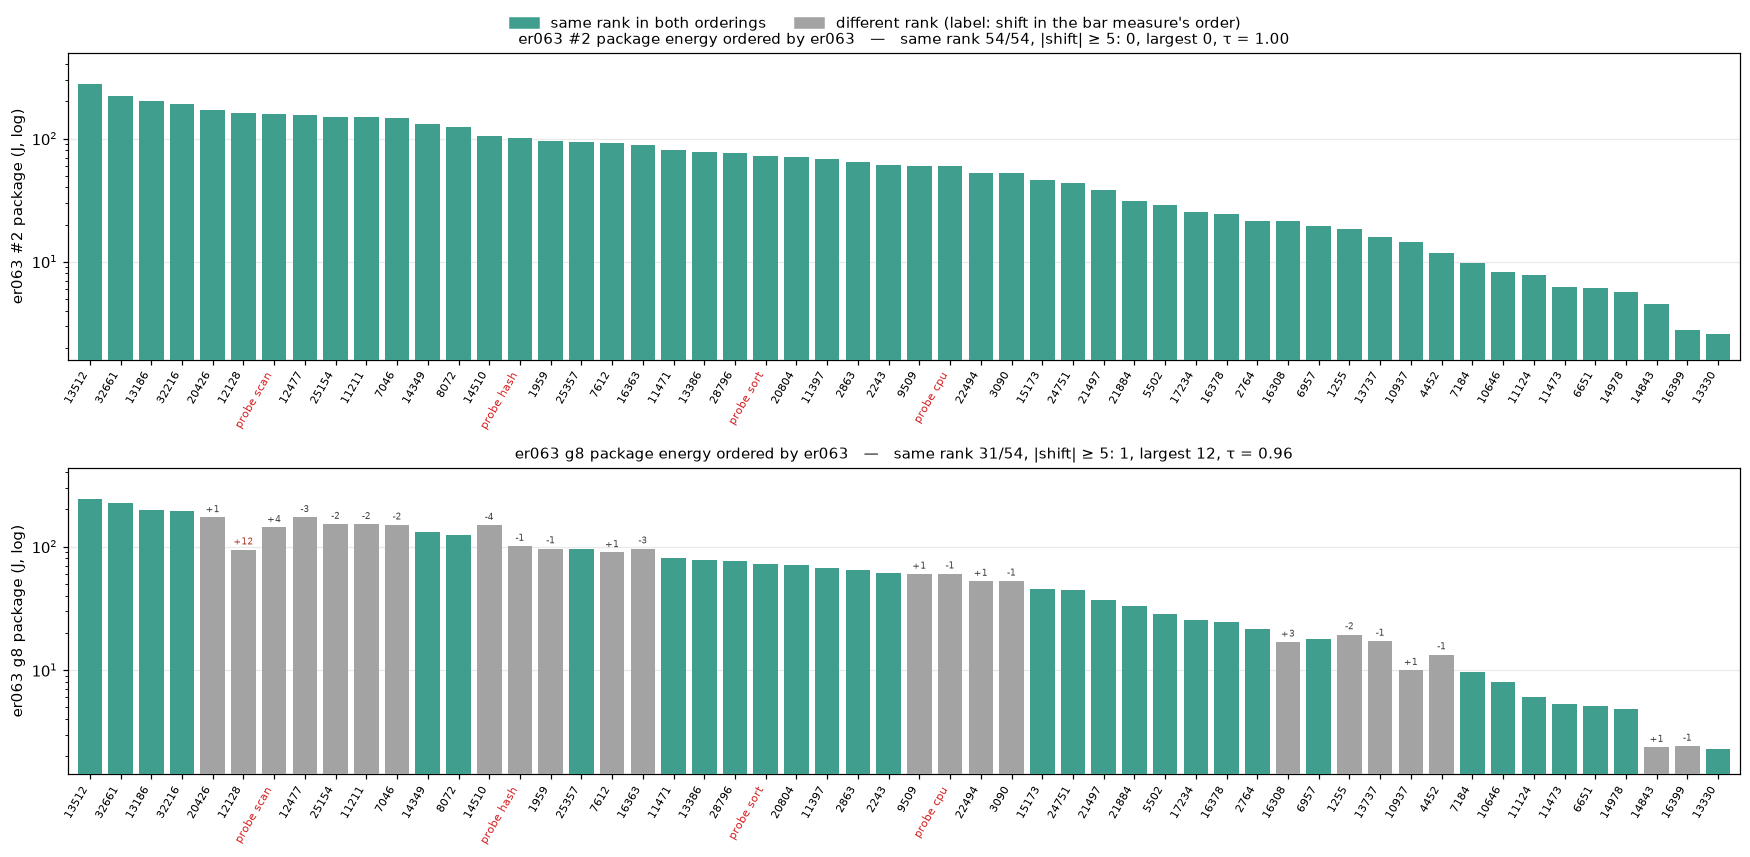

In [24]:
RB7 = [(MP.get(CBASE, E[CBASE].groupby("q")["pkg"].mean()), E[v].groupby("q")["pkg"].mean(),
        f"{v} package energy ordered by {CBASE}", f"{v} package (J, log)") for v in CREP + CVAR]
if RB7:
    rank_figure(RB7, "rank_bars_c6620")

**Reading §8.**

* **Same session settings give the same numbers.** `er063 #2` matches er063 for every query: one pass within
  0.1 %, no query beyond noise, identical ranks. Every difference in `er063 g8` is therefore caused by the
  parameters.
* **Allowing more parallelism moves individual queries a lot and the total a little.**
  * One pass takes 3.1 % less time and 1.2 % less package energy (psys 1.4 % less); the median query is unchanged.
  * 39 of 50 SQLStorm queries launch more workers. Most went from 2 to 4 or from 4 to 6.
  * 19 queries use less energy beyond noise and 19 use more.
* **Energy follows time, as on the laptops (§3).** Power while running rises only about 1 %, so a query that gets
  faster also gets cheaper.
  * Winners: 14843 (0 → 6 workers, 0.52× energy), 12128 (0 → 4, 0.59×), and several short queries going from 2–4 to
    4–6 workers (0.79–0.87×).
  * Losers: 14510 (2 → 4 workers, 1.42×, its execution time rose from 1.0 to 1.5 s) and 4452 (3 → 1 workers,
    1.14×).
  * More workers is not always faster on this 56-thread machine, even with idle threads available.
* **The query ranking barely changes** (τ 0.96). Only 12128 moves far, 12 places cheaper.

## 9. Repeatability per machine

**Noise model.** A query's slope repeats with SD `σ = √(a² + (k·E)²)`: a fixed part `a` (J) that dominates
short queries and a proportional part `k`. Fitted per run on the queries with 3+ rounds (log residuals, grid
search), so later notebooks can tell a real difference from noise on each machine. Right: drift — each round's
slopes relative to the query's mean over the run.

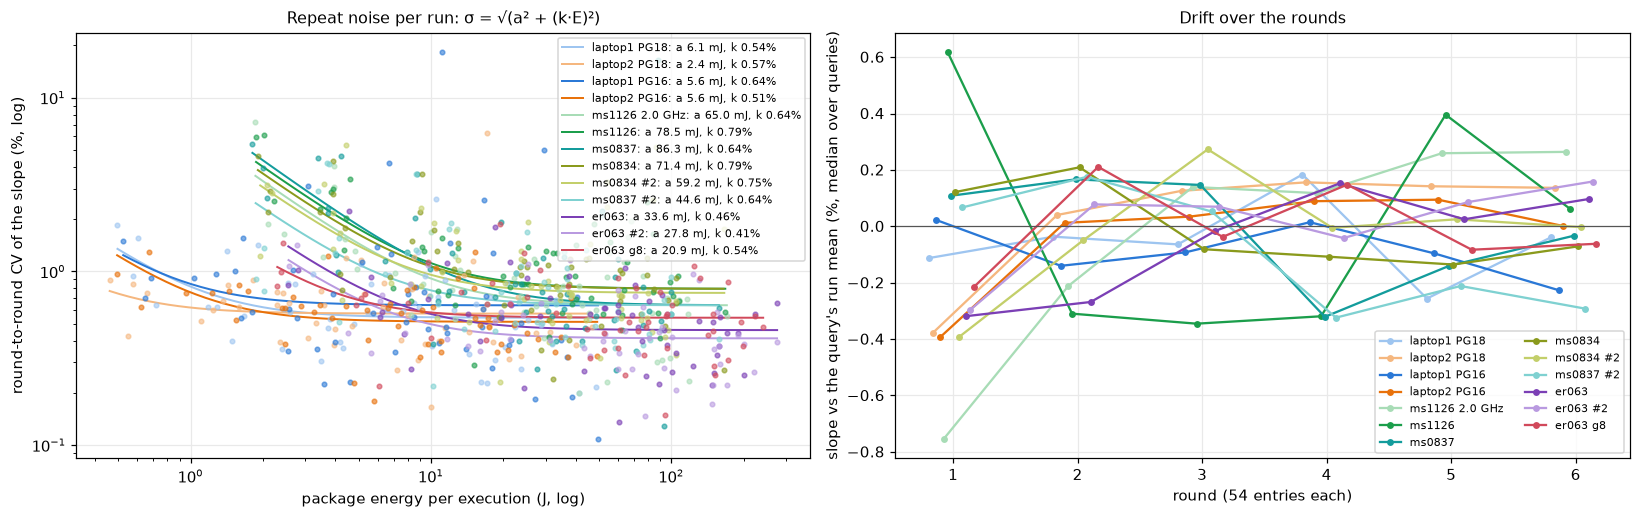

                a (mJ)  k (%)  median CV (%)  queries  rounds
laptop1 PG18      6.14   0.54           0.61     54.0     6.0
laptop2 PG18      2.39   0.57           0.58     54.0     6.0
laptop1 PG16      5.58   0.64           0.58     54.0     6.0
laptop2 PG16      5.58   0.51           0.59     54.0     6.0
ms1126 2.0 GHz   65.01   0.64           0.78     54.0     6.0
ms1126           78.52   0.79           0.93     54.0     6.0
ms0837           86.29   0.64           0.77     54.0     6.0
ms0834           71.45   0.79           1.00     54.0     6.0
ms0834 #2        59.15   0.75           0.82     54.0     6.0
ms0837 #2        44.56   0.64           0.70     54.0     6.0
er063            33.57   0.46           0.55     54.0     6.0
er063 #2         27.80   0.41           0.42     54.0     6.0
er063 g8         20.94   0.54           0.56     54.0     6.0
laptop1 PG18    round medians: -0.11%, -0.04%, -0.06%, +0.18%, -0.26%, -0.04%
laptop2 PG18    round medians: -0.38%, +0.04%, +0.13%,

In [25]:
def fit_noise(m, s):
    m, s = np.asarray(m), np.asarray(s)
    ok = (m > 0) & (s > 0)
    m, s = m[ok], s[ok]
    A = np.exp(np.linspace(np.log(1e-5), np.log(5), 140))
    K = np.exp(np.linspace(np.log(1e-4), np.log(0.2), 140))
    pred = 0.5 * np.log(A[:, None, None] ** 2 + (K[None, :, None] * m[None, None, :]) ** 2)
    err = ((np.log(s)[None, None, :] - pred) ** 2).sum(axis=2)
    ia, ik = np.unravel_index(err.argmin(), err.shape)
    return A[ia], K[ik]


NOISE = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
for l in LBL:
    pqv = per_query(l, "pkg")
    pqv = pqv[pqv["n"] >= 3]
    if len(pqv) < 10:
        print(f"{l}: {len(pqv)} queries with 3+ rounds so far — no noise fit yet")
        continue
    a, k = fit_noise(pqv["mean"], pqv["sd"])
    NOISE[l] = {"a (mJ)": 1000 * a, "k (%)": 100 * k, "median CV (%)": 100 * (pqv["sd"] / pqv["mean"]).median(),
                "queries": len(pqv), "rounds": rounds(l)}
    ax.scatter(pqv["mean"], 100 * pqv["sd"] / pqv["mean"], s=9, color=COL[l], alpha=0.6, zorder=3)
    ee = np.exp(np.linspace(np.log(pqv["mean"].min()), np.log(pqv["mean"].max()), 50))
    ax.plot(ee, 100 * np.sqrt(a ** 2 + (k * ee) ** 2) / ee, color=COL[l], lw=1.3,
            label=f"{l}: a {1000 * a:.1f} mJ, k {100 * k:.2f}%")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("package energy per execution (J, log)"); ax.set_ylabel("round-to-round CV of the slope (%, log)")
ax.legend(fontsize=7)
ax.set_title("Repeat noise per run: σ = √(a² + (k·E)²)", fontsize=10.5)
ax = axes[1]
DRIFT = {}
for j, l in enumerate(LBL):
    e = E[l]
    if (e["round"].value_counts() == 54).sum() < 2:
        continue
    rel = e["pkg"] / e.groupby("q")["pkg"].transform("mean") - 1
    full = e["round"].value_counts()
    g = rel.groupby(e["round"]).median()[lambda s: full[s.index] == 54]     # complete rounds only
    DRIFT[l] = g
    ax.plot(g.index + (j - len(LBL) / 2) * 0.03, 100 * g, "o-", ms=3.5, color=COL[l], label=l)
ax.axhline(0, color="#555", lw=0.8)
ax.set_xlabel("round (54 entries each)"); ax.set_ylabel("slope vs the query's run mean (%, median over queries)")
ax.legend(fontsize=7, ncol=2)
ax.set_title("Drift over the rounds", fontsize=10.5)
fig.tight_layout(); savefig(fig, "noise_drift"); plt.show()
print(pd.DataFrame(NOISE).T.round(2).to_string())
for l, g in DRIFT.items():
    print(f"{l:15s} round medians: " + ", ".join(f"{100 * v:+.2f}%" for v in g))

## 10. Variance compared across machines

§9 fits one noise model per run. Here the machines are compared on the same footing: per SQLStorm query, the
round-to-round CV (SD / mean over its 6 entries) of every measured quantity, summarised by the median over the 50
queries with a bootstrap 95 % interval (resampling queries). Then three questions:

* Which machine is noisier? Per query, whose CV is larger; with 50 independent queries, equal noise gives about
  half each way (sign test).
* Are the same queries noisy everywhere? Rank correlation (Spearman) of the per-query CV between runs.
* Is the energy noise only time noise? Per entry, the deviation of energy and of time from the query's mean, and
  their correlation.

All energies in this section are the package zone; DRAM is left out.

median per-query CV over the rounds (%), bootstrap 95 % interval over the 50 SQLStorm queries

                   package slope        time slope package power while running 1-copy package energy       1-copy time package over idle rounds for ±1 % (median query) one round: ±95 % (median / 90th pct query)
laptop1 PG18    0.61 (0.54–0.68)  0.50 (0.45–0.71)            0.52 (0.44–0.64)      1.13 (1.00–1.38)  0.80 (0.67–1.17)  0.79 (0.71–0.90)                              2                              ±1.2 / ±2.2 %
laptop2 PG18    0.57 (0.48–0.69)  0.38 (0.30–0.46)            0.59 (0.48–0.66)      0.96 (0.80–1.09)  0.48 (0.38–0.59)  0.70 (0.66–0.80)                              2                              ±1.1 / ±1.9 %
laptop1 PG16    0.55 (0.48–0.73)  0.46 (0.38–0.61)            0.48 (0.40–0.62)      1.18 (0.99–1.45)  1.02 (0.82–1.27)  0.70 (0.63–0.84)                              2                              ±1.1 / ±3.3 %
laptop2 PG16    0.59 (0.49–0.63)  0.41 (0.34–0.49)           

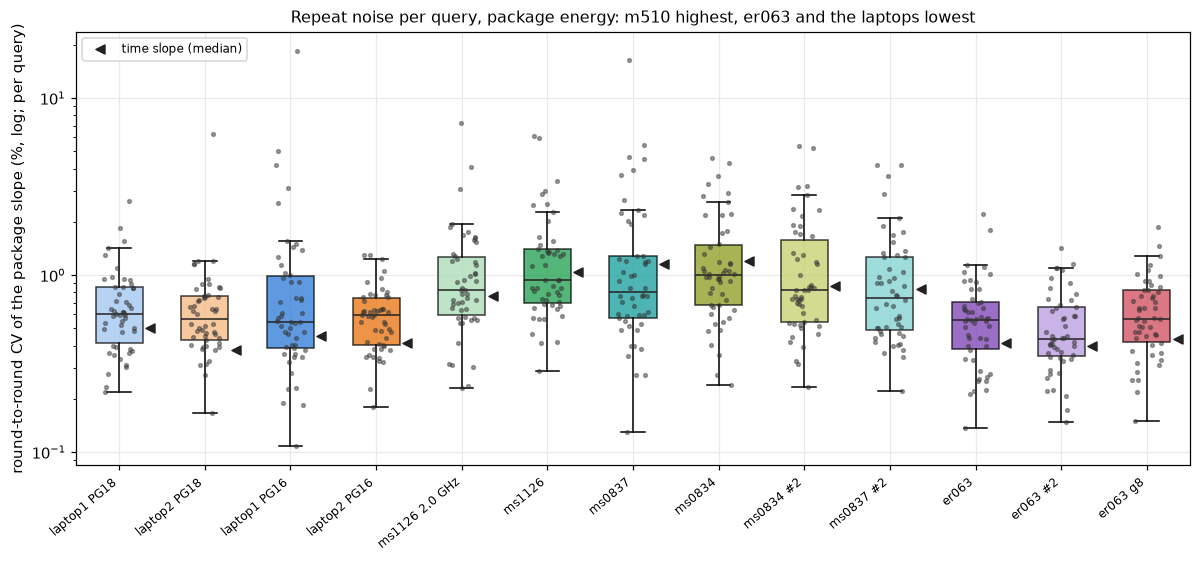

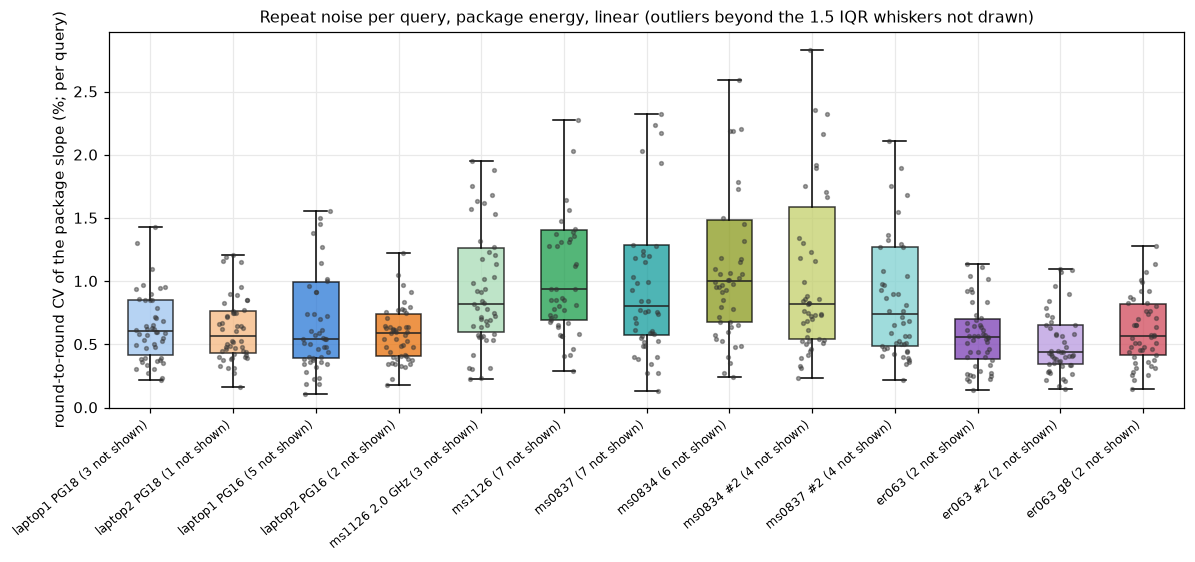

not drawn (beyond the whiskers, still in every statistic): laptop1 PG18: 11397, 14843, 16399; laptop2 PG18: 25154; laptop1 PG16: 11211, 11471, 2764, 8072, 9509; laptop2 PG16: 16399, 7612; ms1126 2.0 GHz: 11473, 13330, 6651; ms1126: 10646, 11473, 12128, 13330, 14843, 16399, 6651; ms0837: 11124, 11211, 1255, 13330, 14843, 14978, 16399; ms0834: 11473, 1255, 13330, 14843, 16363, 6651; ms0834 #2: 11124, 11211, 14978, 16399; ms0837 #2: 11473, 1255, 14978, 6651; er063: 1255, 14843; er063 #2: 16399, 21497; er063 g8: 1255, 16399


In [26]:
VAR_COLS = [("pkg", "package slope"), ("t", "time slope"), ("P", "package power while running"),
            ("e1", "1-copy package energy"), ("t1", "1-copy time"), ("pkg_oi", "package over idle")]
for l in LBL:
    E[l]["P"] = E[l]["pkg"] / E[l]["t"]
SQ = {l: E[l][E[l]["kind"] == "sqlstorm"] for l in LBL}


def cv_q(l, col):
    g = SQ[l].groupby("q")[col]
    return (g.std() / g.mean().abs())[g.size() >= 3]


def med_ci(s, B=2000, seed=0):
    v = s.dropna().to_numpy()
    b = np.median(np.random.default_rng(seed).choice(v, (B, len(v))), axis=1)
    return np.median(v), *np.quantile(b, [0.025, 0.975])


VT = {}
for l in LBL:
    row = {}
    for c, name in VAR_COLS:
        m, lo, hi = med_ci(100 * cv_q(l, c))
        row[name] = f"{m:.2f} ({lo:.2f}–{hi:.2f})"
    cv = cv_q(l, "pkg")
    row["rounds for ±1 % (median query)"] = int(np.ceil((1.96 * cv.median() / 0.01) ** 2))
    row["one round: ±95 % (median / 90th pct query)"] = f"±{196 * cv.median():.1f} / ±{196 * cv.quantile(0.9):.1f} %"
    VT[l] = row
VT = pd.DataFrame(VT).T
print("median per-query CV over the rounds (%), bootstrap 95 % interval over the 50 SQLStorm queries\n")
with pd.option_context("display.width", 280, "display.max_colwidth", 30):
    print(VT.to_string())

fig, ax = plt.subplots(figsize=(11, 5.2))
for j, l in enumerate(LBL):
    v = 100 * cv_q(l, "pkg")
    ax.boxplot([v], positions=[j], widths=0.55, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=COL[l], alpha=0.75), medianprops=dict(color="#222"))
    ax.scatter(j + np.random.default_rng(j).uniform(-0.18, 0.18, len(v)), v, s=6, color="#333", alpha=0.45, zorder=3)
    t_ = 100 * cv_q(l, "t")
    ax.scatter([j + 0.36], [t_.median()], marker="<", s=34, color="#222", zorder=4,
               label="time slope (median)" if j == 0 else None)
ax.set_xticks(range(len(LBL))); ax.set_xticklabels(LBL, rotation=40, ha="right", fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("round-to-round CV of the package slope (%, log; per query)")
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Repeat noise per query, package energy: m510 highest, er063 and the laptops lowest", fontsize=10.5)
fig.tight_layout(); savefig(fig, "variance_machines"); plt.show()

# the same on a linear axis; the boxes and whiskers (1.5 IQR) use every query, only the points beyond the
# whiskers are not drawn, so the axis can zoom in on the boxes
fig, ax = plt.subplots(figsize=(11, 5.2))
HIDDEN, TOPS = {}, []
for j, l in enumerate(LBL):
    v = 100 * cv_q(l, "pkg")
    q1, q3 = v.quantile([0.25, 0.75])
    lo_w, hi_w = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    shown = v.between(lo_w, hi_w)
    HIDDEN[l] = sorted(v.index[~shown])
    TOPS.append(v[shown].max())
    ax.boxplot([v], positions=[j], widths=0.55, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=COL[l], alpha=0.75), medianprops=dict(color="#222"))
    ax.scatter(j + np.random.default_rng(j).uniform(-0.18, 0.18, shown.sum()), v[shown], s=6, color="#333", alpha=0.45, zorder=3)
ax.set_xticks(range(len(LBL)))
ax.set_xticklabels([f"{l} ({len(HIDDEN[l])} not shown)" for l in LBL], rotation=40, ha="right", fontsize=8)
ax.set_ylim(0, max(TOPS) * 1.05); ax.set_ylabel("round-to-round CV of the package slope (%; per query)")
ax.set_title("Repeat noise per query, package energy, linear (outliers beyond the 1.5 IQR whiskers not drawn)", fontsize=10.5)
fig.tight_layout(); savefig(fig, "variance_machines_linear"); plt.show()
print("not drawn (beyond the whiskers, still in every statistic):",
      "; ".join(f"{l}: {', '.join(v) or '-'}" for l, v in HIDDEN.items()))

In [27]:
from math import comb


def sign_p(k, n):
    """two-sided sign test: k of n queries noisier in one run"""
    t = sum(comb(n, i) for i in range(0, min(k, n - k) + 1)) / 2 ** n
    return min(1.0, 2 * t)


VM = MAIN + [l for l in LBL if R.at[l, "role"] == "variant"]
CVT = pd.DataFrame({l: cv_q(l, "pkg") for l in VM})
SPEAR = CVT.corr("spearman")
rows = []
for i_, a in enumerate(VM):
    for b in VM[i_ + 1:]:
        x = CVT[[a, b]].dropna()
        k = int((x[a] > x[b]).sum())
        share = 100 * max(k, len(x) - k) / len(x)
        rows.append({"hardware": " vs ".join(sorted([R.at[a, "hw"], R.at[b, "hw"]])), "noisier run": a if k * 2 > len(x) else b,
                     "share": share, "p": sign_p(k, len(x)), "spearman": SPEAR.at[a, b]})
PAIRV = pd.DataFrame(rows)
print("per pair of runs (package slope): the share of queries where the noisier run has the larger CV, the sign test,\n"
      "and the Spearman correlation of the per-query CV; summarised by hardware pair\n")
print(PAIRV.groupby("hardware").agg(pairs=("p", "size"), share_min=("share", "min"), share_max=("share", "max"),
                                    pairs_p_below_001=("p", lambda v: int((v < 0.01).sum())),
                                    spearman_median=("spearman", "median")).round(2).to_string())
print("\npairs with p < 0.01 — how often each run is the noisier one:",
      PAIRV.loc[PAIRV["p"] < 0.01, "noisier run"].value_counts().to_dict())

per pair of runs (package slope): the share of queries where the noisier run has the larger CV, the sign test,
and the Spearman correlation of the per-query CV; summarised by hardware pair

                  pairs  share_min  share_max  pairs_p_below_001  spearman_median
hardware                                                                         
c6620 vs c6620        1       52.0       52.0                  0             0.32
c6620 vs laptop       8       50.0       58.0                  0             0.22
c6620 vs m510         8       68.0       86.0                  7             0.16
laptop vs laptop      6       50.0       56.0                  0             0.20
laptop vs m510       16       68.0       92.0                 14             0.17
m510 vs m510          6       50.0       66.0                  0             0.44

pairs with p < 0.01 — how often each run is the noisier one: {'ms1126': 6, 'ms0837': 5, 'ms0834': 5, 'ms1126 2.0 GHz': 5}


In [28]:
rows = {}
for l in VM:
    q = SQ[l]
    g = q.groupby("q")
    de = q["pkg"] / g["pkg"].transform("mean") - 1
    dt = q["t"] / g["t"].transform("mean") - 1
    ce, ct = cv_q(l, "pkg"), cv_q(l, "t")
    third = pd.qcut(g["pkg"].mean().rank(method="first"), 3, labels=["short", "middle", "long"])
    rows[l] = {"CV energy / CV time (median query)": (ce / ct).median(),
               "corr. of energy and time deviations": np.corrcoef(de, dt)[0, 1],
               **{f"CV package, {k} third (%)": 100 * ce[third == k].median() for k in ["short", "middle", "long"]}}
NT = pd.DataFrame(rows).T
print(NT.round(2).to_string())

                CV energy / CV time (median query)  corr. of energy and time deviations  CV package, short third (%)  CV package, middle third (%)  CV package, long third (%)
laptop1 PG18                                  1.07                                 0.69                         0.64                          0.60                        0.49
laptop2 PG18                                  1.52                                 0.81                         0.66                          0.63                        0.47
laptop1 PG16                                  1.12                                 0.58                         0.74                          0.53                        0.40
laptop2 PG16                                  1.46                                 0.44                         0.71                          0.59                        0.42
ms1126 2.0 GHz                                1.03                                 0.88                         1.32         

**Reading §10** (package energy throughout).

* **The m510 is the noisiest machine; er063 and the laptops are alike.** The median query's package slope repeats
  with a CV of 0.74–1.00 % on the m510 nodes, 0.55–0.61 % on the laptops and 0.44–0.57 % on er063.
  * Query by query, an m510 run is noisier than a laptop run for 68–92 % of the queries (14 of 16 pairs beyond
    chance, sign test p < 0.01) and noisier than er063 for 68–86 % (7 of 8 pairs).
  * er063 vs the laptops (50–58 %) and the m510 nodes among themselves (50–66 %) are not distinguishable.
* **The m510's extra noise sits in short queries.** In the shortest third of the queries its CV is 1.3–2.0 %, 2–3× a
  laptop's. In the longest third it is 0.6–0.8 %, against 0.4–0.5 % elsewhere. That is the fixed part `a` of §9's
  noise model (45–86 mJ on the m510 vs 2–6 mJ on the laptops and 21–34 mJ on er063).
* **The noise depends on the quantity.**
  * The 1-copy batch repeats worse than the slope everywhere: energy 0.8–1.7 %; 1-copy time on the m510
    2.1–2.5 % at the 2.6 GHz cap. The per-batch start-up it includes varies.
  * The cost over idle (§5) is precise on the laptops (0.65–0.8 %) but not on er063 (3.5–3.9 %). There it is about a
    third of the slope, the difference of two large numbers.
* **Noise is mostly not a property of the query.** Which queries are noisy hardly carries over between machines
  (Spearman of the per-query CV 0.16–0.22 between hardware types). It carries over somewhat between the m510 nodes
  (0.44). A query that is noisy on one machine is not necessarily noisy on another.
* **On the servers, energy noise is time noise; on the laptops it is partly power.** Per entry, the deviations of
  energy and time correlate at 0.87–0.92 on the servers, against 0.44–0.81 on the laptops, where the power while
  running fluctuates on its own. On the m510 at 2.6 GHz energy varies *less* than time (ratio 0.67–0.80): a slower
  execution draws slightly less power.
* **What it means for the number of rounds.** For ±1 % (95 %) on the median query:
  * 1–2 rounds suffice on the laptops and er063, 3–4 on the m510.
  * A single round, as in a full run (§11), gives about ±1.1 % on the laptops and er063 and ±1.5–2.0 % on the m510
    for the median query, and ±2–7 % for the noisiest tenth.
  * This does not include the m510's node offset (§6).

## 11. Estimate: a full uniform 1,16 StackOverflow run on each machine, duplicates removed

**What is estimated.** One pass over SQLStorm's StackOverflow set with the protocol of laptop2's full run
(`so_uniform_1_16_20260930T094325Z`, `laptop2_export.ipynb`): per query 2 warm-ups, a 1-copy and a 16-copy batch,
15 s statement timeout, a warm-up timeout skips the query. Duplicates are removed first: of each set of queries
with identical SQL (normalised as in `laptop2_export.ipynb`: comments, the `EXPLAIN` wrapper, whitespace and case
ignored) only the lowest-numbered query is kept. The time and energy (package + DRAM) of the whole run are
estimated for every machine and setting in this notebook (repeat sessions left out).

**How.**
* **Base: the measured laptop2 full run** (PG18): every query's warm-up and batch times and energies. Its 50
  queries that are also in the compare set agree with the `laptop2 PG18` compare run to 0.1 % (checked below), so
  the compare runs can be chained onto it.
* **Per machine, a time and an energy factor** relative to `laptop2 PG18`, from the 50 SQLStorm queries of the
  compare set: the ratio of the summed warm-ups + batches per entry. The ratio depends on query length (short queries
  carry a fixed per-execution cost that differs between machines), so it is fitted as a line in log–log
  (`log factor = a + b · log laptop2 value`). Outside the range of the 50 queries it is held at its edge value.
* **Timeouts.** A query times out on a machine when its first warm-up would take ≥ 15 s there. For the 363 queries
  that timed out on laptop2, their time from the 300 s re-run (`sqlstorm_analysis.ipynb` §6a, laptop1) is used.
  On a faster machine some of them finish; their energy is then estimated from the machine's power while running.
  A timed-out query costs 15 s at that power.
* **Per-entry overhead** (client start, catalogue, logging) and the thermal gate add time: the median from the
  machine's compare run, minus the compare run's 5 s idle baseline. No idle time is included: no idle baseline, and
  the energy is only what RAPL measures during the warm-ups and batches.
* **Uncertainty:** bootstrap over the 50 calibration queries (refitting both factors), 95 % interval. This covers how
  well 50 queries represent the full set's mix; it does not cover node-to-node offsets (§6).

In [29]:
UNI_RUN = "so_uniform_1_16_20260930T094325Z"
UNI = Path("cache/laptop2_cache") / UNI_RUN                        # from laptop2_export.ipynb
SO_QDIR = Path("cache/sqlstorm_cache/stackoverflow/queries")        # from sqlstorm_analysis.ipynb
RERUN_CSV = Path("csv/sqlstorm_stackoverflow_timeout_rerun.csv")    # from sqlstorm_analysis.ipynb (§6a)
SQLGLOT_CSV = Path("csv/sqlstorm_stackoverflow_sqlglot.csv")        # from sqlstorm_outputs.ipynb
for p, what in [(UNI / f"query_timing_{DB}.csv", "laptop2 full run (laptop2_export.ipynb)"),
                (SO_QDIR, "query files (sqlstorm_analysis.ipynb)"), (RERUN_CSV, "timeout re-run (sqlstorm_analysis.ipynb)")]:
    assert p.exists(), f"missing {what} at {p}"
STMT_TIMEOUT, N_EXEC = 15.0, 19                    # 2 warm-ups + 1 + 16 executions per entry


def entry_table(t, dram_fix=1.0):
    """one row per entry: summed elapsed and energy (pkg + DRAM) of its warm-ups and batches, wall time"""
    t = t.copy()
    t["ts"] = pd.to_datetime(t["timestamp_utc"])
    t["entry"] = (t["phase"].eq("warmup") & t["batch_index"].eq(1)).cumsum()
    t["E"] = t["rapl_pkg_j"].fillna(0) + dram_fix * t["rapl_dram_j"].fillna(0)
    g = t.groupby("entry")
    d = pd.DataFrame({"q": g["query"].first().str.extract(r"([^/]+)\.sql$")[0], "start": g["ts"].min(),
                      "batch_s": g["elapsed_sec"].sum(), "batch_j": g["E"].sum(),
                      "first_s": g["elapsed_sec"].first(), "failed": g["failed"].max(), "batches": g.size(),
                      "gate_s": g[["preheat_s", "cooldown_wait_s"]].sum().sum(axis=1)})
    d["wall_s"] = (d["start"].shift(-1) - d["start"]).dt.total_seconds()
    d["rest_s"] = d["wall_s"] - d["batch_s"] - d["gate_s"]
    return d


def norm_sql(txt):
    s = re.sub(r"--[^\n]*", " ", txt)
    s = re.sub(r"/\*.*?\*/", " ", s, flags=re.S)
    s = re.sub(r"(?is)^\s*EXPLAIN\s*\([^)]*\)", " ", s)
    return re.sub(r"\s+", " ", s).strip().rstrip(";").strip().lower()


UE = entry_table(pd.read_csv(UNI / f"query_timing_{DB}.csv")).set_index("q")
UE["ok"] = (UE["failed"] == 0) & (UE["batches"] == 4)
USUM = kv(read(UNI / "summary.txt"))
SQLN = pd.Series({p.stem: norm_sql(p.read_text("utf-8", "replace")) for p in SO_QDIR.glob("*.sql")})
CANON_Q = SQLN.groupby(SQLN).transform(lambda s: min(s.index, key=int))      # query -> lowest-numbered copy
SGL = pd.read_csv(SQLGLOT_CSV, dtype={"query": str}).set_index("query")["canonical_hash"] if SQLGLOT_CSV.exists() else None
SETS = {"all queries": sorted(UE.index, key=int),
        "identical SQL removed": sorted(set(CANON_Q), key=int)}
if SGL is not None:
    sg = SGL.reindex(SETS["identical SQL removed"])
    SETS["+ sqlglot canonical copies removed"] = sorted(sg.groupby(sg).apply(lambda s: min(s.index, key=int)), key=int)
KEEP = SETS["identical SQL removed"]
RER = pd.read_csv(RERUN_CSV, dtype={"qid": str}).set_index("qid")
print(f"laptop2 full run: {len(UE)} entries ({int(UE['ok'].sum())} complete, {int((~UE['ok']).sum())} timed out), "
      f"{USUM['total_runtime'].split()[0]} h:m:s, PG{USUM['pg']}")
print("query sets: " + "; ".join(f"{k}: {len(v)}" for k, v in SETS.items()))

CE = {l: entry_table(T[l], DRAM_FIX[l]) for l in LBL}
U_REF = "laptop2 PG18"
cq = lambda l: CE[l][(CE[l]["failed"] == 0) & ~CE[l]["q"].str.startswith("probe")].groupby("q")[["batch_s", "batch_j", "first_s"]].mean()
chk = cq(U_REF).join(UE[["batch_s", "batch_j"]], rsuffix="_uni", how="inner")
print(f"check, the {len(chk)} compare-set queries in the full run vs the {U_REF} compare run: time "
      f"{(chk['batch_s_uni'] / chk['batch_s']).median():.4f} (IQR {(chk['batch_s_uni'] / chk['batch_s']).quantile(0.25):.3f}–"
      f"{(chk['batch_s_uni'] / chk['batch_s']).quantile(0.75):.3f}), energy {(chk['batch_j_uni'] / chk['batch_j']).median():.4f}; "
      f"summed: time {chk['batch_s_uni'].sum() / chk['batch_s'].sum():.4f}, energy {chk['batch_j_uni'].sum() / chk['batch_j'].sum():.4f}")
lo_, hi_ = chk["batch_s"].min(), chk["batch_s"].max()
ub = UE.loc[KEEP]
print(f"calibration range (per entry, laptop2): {lo_:.1f}–{hi_:.0f} s; {100 * ub['batch_s'].between(lo_, hi_).mean():.0f} % of the "
      f"deduplicated queries fall inside, holding {100 * ub.loc[ub['batch_s'].between(lo_, hi_), 'batch_s'].sum() / ub['batch_s'].sum():.0f} % of their time")

laptop2 full run: 11794 entries (11431 complete, 363 timed out), 81:48:43 h:m:s, PG18
query sets: all queries: 11794; identical SQL removed: 9519; + sqlglot canonical copies removed: 9089
check, the 50 compare-set queries in the full run vs the laptop2 PG18 compare run: time 0.9986 (IQR 0.996–1.001), energy 1.0006; summed: time 0.9976, energy 1.0023
calibration range (per entry, laptop2): 1.2–109 s; 92 % of the deduplicated queries fall inside, holding 78 % of their time


In [30]:
EST_RUNS = MAIN + [l for l in LBL if R.at[l, "role"] == "variant"]


def fit_factor(x, y, const=False):
    """log y/x = a + b log x, x held inside the calibration range (const: one factor, sum y / sum x)"""
    if const:
        return lambda v: np.full(np.shape(v), y.sum() / x.sum()), 0.0
    lx = np.log(x)
    b, a = np.polyfit(lx, np.log(y / x), 1)
    return lambda v: np.exp(a + b * np.clip(np.log(v), lx.min(), lx.max())), b


def machine_params(l):
    oh = CE[l]["rest_s"].median() - float(CFG[l].get("IDLE_BASELINE_S", "5").split()[0] or 5)
    return {"overhead_s": oh, "gate_s": CE[l]["gate_s"].mean(), "run_w": SQ[l]["total"].sum() / SQ[l]["t"].sum()}


# reference per query: laptop2's summed batch time and energy, its first warm-up, and the timeout re-run's time
REF_Q = UE[["batch_s", "batch_j", "first_s", "ok"]].copy()
rer_t = RER["rerun_elapsed_sec"].where(RER["rerun_outcome"] == "finished")
REF_Q["t_exec"] = np.where(REF_Q["ok"], REF_Q["batch_s"] / N_EXEC, rer_t.reindex(REF_Q.index))
REF_Q.loc[~REF_Q["ok"], "first_s"] = REF_Q["t_exec"] * (UE.loc[REF_Q["ok"], "first_s"] / (UE.loc[REF_Q["ok"], "batch_s"] / N_EXEC)).median()


def estimate(l, qs, cal=None, const=False):
    cal = cq(l).join(cq(U_REF), rsuffix="_ref", how="inner") if cal is None else cal
    ft, bt = fit_factor(cal["batch_s_ref"].to_numpy(), cal["batch_s"].to_numpy(), const)
    fe, be = fit_factor(cal["batch_j_ref"].to_numpy(), cal["batch_j"].to_numpy(), const)
    p = machine_params(l)
    r = REF_Q.loc[qs]
    ok_ref = r["ok"].to_numpy()
    bs_ref = np.where(ok_ref, r["batch_s"], N_EXEC * r["t_exec"].fillna(np.inf))
    f_t = ft(np.where(np.isfinite(bs_ref), bs_ref, hi_))
    first_m = r["first_s"].to_numpy() * f_t
    to = ~(first_m < STMT_TIMEOUT)                                   # NaN (never finished) counts as a timeout
    bs = np.where(to, STMT_TIMEOUT, np.where(ok_ref, r["batch_s"] * f_t, bs_ref * f_t))
    bj = np.where(to, STMT_TIMEOUT * p["run_w"],
                  np.where(ok_ref, r["batch_j"] * fe(r["batch_j"].where(ok_ref, 1).to_numpy()), bs * p["run_w"]))
    extra = p["overhead_s"] + p["gate_s"]
    n = len(qs)
    return {"queries": n, "complete": int((~to).sum()), "time out": int(to.sum()),
            "query time (h)": bs.sum() / 3600, "overhead (h)": n * extra / 3600, "total (h)": (bs.sum() + n * extra) / 3600,
            "total (kWh)": bj.sum() / 3.6e6, "time-factor slope": bt, "energy-factor slope": be}


def boot(l, qs, B=300, seed=1):
    cal = cq(l).join(cq(U_REF), rsuffix="_ref", how="inner")
    rng = np.random.default_rng(seed)
    out = [estimate(l, qs, cal.iloc[rng.integers(0, len(cal), len(cal))]) for _ in range(B)]
    return {k: np.quantile([o[k] for o in out], [0.025, 0.975]) for k in ["total (h)", "total (kWh)"]}


EST = {}
for l in EST_RUNS:
    e = estimate(l, KEEP)
    b = boot(l, KEEP)
    ec = estimate(l, KEEP, const=True)
    EST[l] = {"queries": e["queries"], "complete": e["complete"], "time out": e["time out"],
              "hours": e["total (h)"], "hours 95 %": f"{b['total (h)'][0]:.1f}–{b['total (h)'][1]:.1f}",
              "days": e["total (h)"] / 24, "kWh (pkg + DRAM)": e["total (kWh)"],
              "kWh 95 %": f"{b['total (kWh)'][0]:.2f}–{b['total (kWh)'][1]:.2f}",
              "query share of time": e["query time (h)"] / e["total (h)"],
              "J per query": e["total (kWh)"] * 3.6e6 / e["queries"],
              "one constant factor: hours": ec["total (h)"], "one constant factor: kWh": ec["total (kWh)"],
              "time-factor slope b": e["time-factor slope"], "_e": e, "_hci": b["total (h)"], "_kci": b["total (kWh)"]}
ESTT = pd.DataFrame(EST).T
print(f"Estimated full run, {len(KEEP)} queries (identical SQL removed), 1 pass, uniform 1,16 protocol, 15 s timeout\n")
with pd.option_context("display.width", 300, "display.max_colwidth", 20):
    print(ESTT.drop(columns=["_e", "_hci", "_kci"]).to_string(float_format=lambda v: f"{v:.3g}"))

act = UE["wall_s"].fillna(UE["wall_s"].median()).sum() / 3600
mod = estimate(U_REF, SETS["all queries"])
print(f"\ncheck: the model on laptop2 PG18 for all {len(UE)} queries gives {mod['total (h)']:.1f} h and "
      f"{mod['time out']} timeouts; the full run took {act:.1f} h with {int((~UE['ok']).sum())} timeouts")
print("\nhours by query set (duplicates kept / identical SQL removed / also sqlglot canonical copies removed):")
for l in EST_RUNS:
    print(f"  {l:15s} " + "   ".join(f"{estimate(l, v)['total (h)']:6.1f} h {estimate(l, v)['total (kWh)']:5.2f} kWh" for v in SETS.values()))

Estimated full run, 9519 queries (identical SQL removed), 1 pass, uniform 1,16 protocol, 15 s timeout

               queries complete time out hours  hours 95 % days kWh (pkg + DRAM)   kWh 95 % query share of time J per query one constant factor: hours one constant factor: kWh time-factor slope b
laptop1 PG18      9519     9159      360  78.7   78.3–79.2 3.28             0.54  0.53–0.54               0.856         204                       78.6                    0.536             -0.0255
laptop2 PG18      9519     9158      361  76.1   76.1–76.1 3.17            0.487  0.49–0.49               0.878         184                       76.1                    0.487                   0
laptop1 PG16      9519     9159      360  82.2   78.3–85.9 3.43            0.594  0.55–0.65               0.869         225                       81.4                    0.596             -0.0966
laptop2 PG16      9519     9159      360  79.9   76.1–83.2 3.33            0.537  0.50–0.59               0.881  

  ms0834           103.6 h  2.40 kWh     94.6 h  2.26 kWh     92.5 h  2.22 kWh
  er063             54.3 h  4.37 kWh     50.0 h  4.16 kWh     49.1 h  4.11 kWh
  er063 g8          53.3 h  4.37 kWh     49.3 h  4.17 kWh     48.4 h  4.12 kWh


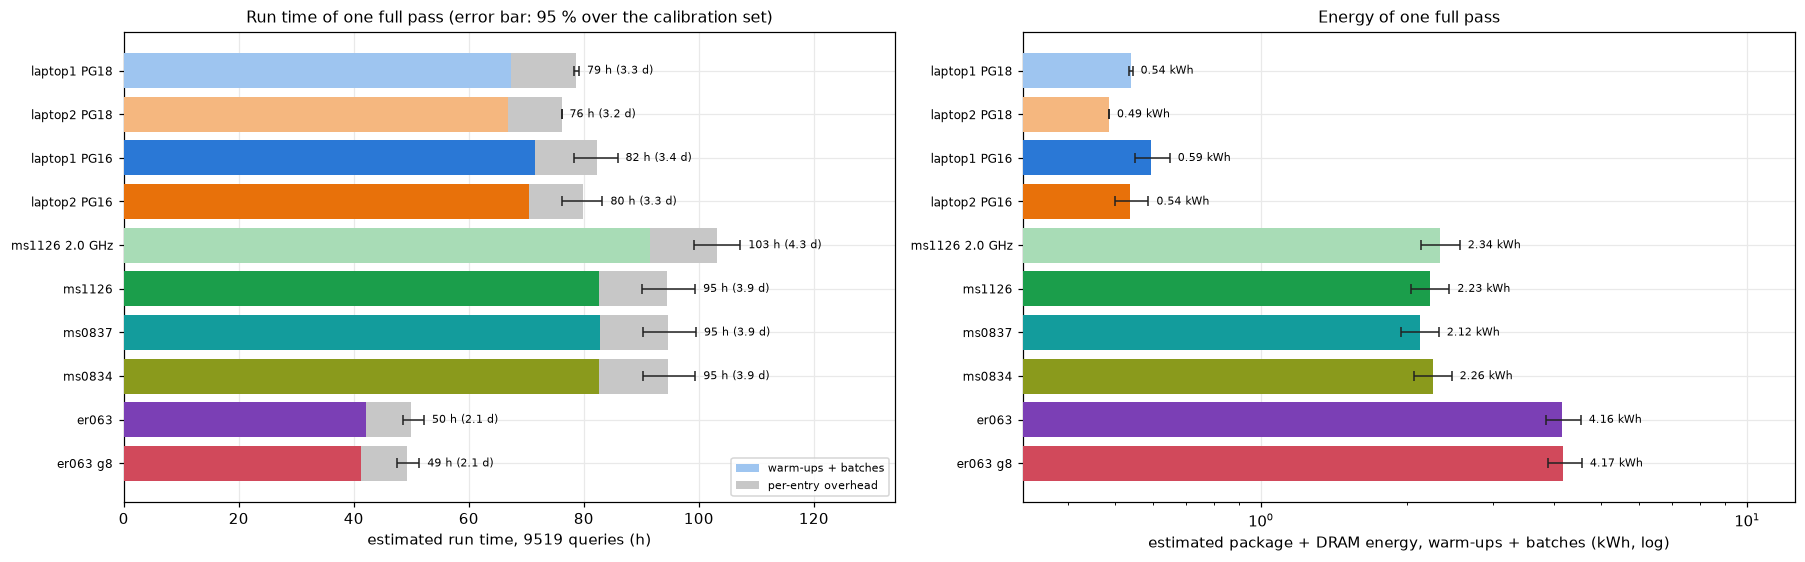

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.2))
y = np.arange(len(EST_RUNS))[::-1]
ax = axes[0]
qh = np.array([EST[l]["_e"]["query time (h)"] for l in EST_RUNS]); oh = np.array([EST[l]["_e"]["overhead (h)"] for l in EST_RUNS])
ax.barh(y, qh, color=[COL[l] for l in EST_RUNS], label="warm-ups + batches", zorder=3)
ax.barh(y, oh, left=qh, color="#c7c7c7", label="per-entry overhead", zorder=3)
for yy, l in zip(y, EST_RUNS):
    lo, hi = EST[l]["_hci"]
    h_ = EST[l]["hours"]
    ax.errorbar(h_, yy, xerr=[[max(0, h_ - lo)], [max(0, hi - h_)]], color="#222", capsize=3, lw=1, zorder=4)
    ax.text(max(hi, h_), yy, f"  {h_:.0f} h ({EST[l]['days']:.1f} d)", va="center", fontsize=7.5)
ax.set_yticks(y); ax.set_yticklabels(EST_RUNS, fontsize=8)
ax.set_xlim(0, (qh + oh).max() * 1.3); ax.set_xlabel(f"estimated run time, {len(KEEP)} queries (h)")
ax.legend(fontsize=7.5, loc="lower right"); ax.set_title("Run time of one full pass (error bar: 95 % over the calibration set)", fontsize=10.5)
ax = axes[1]
qk = np.array([EST[l]["kWh (pkg + DRAM)"] for l in EST_RUNS])
ax.barh(y, qk, color=[COL[l] for l in EST_RUNS], zorder=3)
for yy, l in zip(y, EST_RUNS):
    lo, hi = EST[l]["_kci"]
    k_ = EST[l]["kWh (pkg + DRAM)"]
    ax.errorbar(k_, yy, xerr=[[max(0, k_ - lo)], [max(0, hi - k_)]], color="#222", capsize=3, lw=1, zorder=4)
    ax.text(max(hi, k_), yy, f"  {k_:.2f} kWh", va="center", fontsize=7.5)
ax.set_yticks(y); ax.set_yticklabels(EST_RUNS, fontsize=8); ax.set_xscale("log")
ax.set_xlim(qk.min() / 1.5, qk.max() * 3); ax.set_xlabel("estimated package + DRAM energy, warm-ups + batches (kWh, log)")
ax.set_title("Energy of one full pass", fontsize=10.5)
fig.tight_layout(); savefig(fig, "full_run_estimate"); plt.show()

**Reading §11.**

* **The base reproduces.** laptop2's full run and its compare run agree to 0.1 % in time and energy on the 50
  shared queries. The model applied to laptop2 itself on all 11,794 queries gives 82.1 h and 361 timeouts; the run
  took 81.8 h, with 363 timeouts.
* **Removing duplicates removes 19 % of the queries but only 7 % of the time.**
  * 2,275 of the 11,794 queries repeat another's SQL, which leaves 9,519.
  * The duplicates are mostly short queries, so a laptop run drops from about 82–90 h to 76–82 h.
  * Also removing sqlglot canonical copies (same query with other names) leaves 9,089 queries and saves another
    1–2 h.
* **Estimated time and energy of one pass** (9,519 queries, the full run's protocol, no idle baseline; energy is the
  package + DRAM measured during the warm-ups and batches):

  | machine | time | energy | timeouts |
  |---|---|---|---|
  | laptops (PG18 / PG16) | 76–82 h (3.2–3.4 days) | 0.49–0.59 kWh | 360 |
  | m510 (2.6 GHz) | 95 h (3.9 days), 95 %: 90–99 h | 2.1–2.3 kWh | 364 |
  | m510 at 2.0 GHz | 103 h | 2.3 kWh | 404 |
  | er063 (and g8) | 49–50 h (2.1 days) | 4.2 kWh | 209–214 |
* **The servers trade time for energy differently.**
  * er063 is the fastest, about 1.5× faster than a laptop. Being about 1.8× faster per query, it lets about 150 of
    laptop2's timeouts finish. It also uses the most energy, 7–8.5× a laptop, largely its high power at idle (§5).
  * The m510 takes about 20 % longer than a laptop and uses about 4× the energy.
  * The three m510 nodes differ by about 6 % in energy (the node offsets of §6), not in time.
  * Split over the three m510 nodes, the pass would take about 32 h of wall-clock time.
* **The estimate is not sensitive to the model.**
  * Short queries are relatively slower on the servers: the m510 takes about 2.4× a laptop's time for the shortest
    queries and about 1.0× for the longest.
  * Even so, one constant factor per machine gives totals within 3 % in time and 5 % in energy of the
    length-dependent fit.
  * The bootstrap interval is ±1–5 % in time and ±1–9 % in energy.
* **What it does not cover.**
  * 22 % of the time lies outside the compare set's range, mostly in longer queries; there the factor is held at its
    edge value.
  * Laptop2's timeouts use a re-run made on laptop1.
  * The energy between batches (per-entry overhead) is not measured and is left out.

## 12. Export

`csv/compare_all_machines.csv`: one row per run × query — the run, machine and hardware, rounds
measured, the per-query mean of every zone's slope (J), the package SD and 95 % half-width, time slope (s),
1-copy energy and time, the idle draw before the query's entries (W) and the cost over idle (§5), power while
running, and the package-energy rank within the run (1 = most expensive). DRAM is after the ×0.25 correction. Runs
in progress are exported as they are now.

In [32]:
rows = []
for l in LBL:
    e = E[l]
    g = e.groupby("q")
    NAMES = {"pkg": "pkg_j", "core": "core_j", "rest": "uncore_j", "dram": "dram_j", "total": "pkg_dram_j", "psys": "psys_j",
             "t": "time_s", "e1": "one_copy_pkg_j", "t1": "one_copy_time_s", "pkg_oi": "pkg_over_idle_j",
             "total_oi": "pkg_dram_over_idle_j", "psys_oi": "psys_over_idle_j", "idle_pkg_w": "idle_pkg_w",
             "idle_dram_w": "idle_dram_w", "idle_psys_w": "idle_psys_w"}
    cols = [c for c in NAMES if c in e]
    d = g[cols].mean().rename(columns=NAMES)
    pq_ = per_query(l, "pkg")
    d["pkg_sd_j"] = pq_["sd"]
    d["pkg_ci95_j"] = 1.96 * pq_["se"]
    d["n_rounds"] = pq_["n"]
    d["power_w"] = d["pkg_j"] / d["time_s"]
    d["rank_pkg"] = d["pkg_j"].rank(ascending=False).astype(int)
    d.insert(0, "kind", KIND[d.index])
    for k, v in [("cpu", R.at[l, "cpu"]), ("hardware", R.at[l, "hardware"]), ("machine", R.at[l, "machine"]),
                 ("pg", R.at[l, "pg"]), ("clock_cap_ghz", R.at[l, "clock_ghz"]), ("run_complete", R.at[l, "complete"]),
                 ("run_id", R.at[l, "run"]), ("run", l)]:
        d.insert(0, k, v)
    rows.append(d.reset_index().rename(columns={"q": "query"}))
OUT = pd.concat(rows, ignore_index=True)
OUT.round(6).to_csv("csv/compare_all_machines.csv", index=False)
print(f"wrote csv/compare_all_machines.csv: {len(OUT)} rows ({len(LBL)} runs × up to {OUT['query'].nunique()} queries), "
      f"{OUT.shape[1]} columns")

wrote csv/compare_all_machines.csv: 702 rows (13 runs × up to 54 queries), 30 columns
